
# 1. Environment and Hardware Verification

This section inspects the execution environment before loading the
common observer.

We verify the Python, PyTorch and TorchVision versions, available
hardware acceleration, GPU memory and access to the persistent
Metamer-SAE project directory.

The selected observer for this experiment is ConvNeXt-Tiny with
ImageNet-1K pretrained weights.

All subsequent experiments will use a frozen observer.


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os
import sys
import platform
import torch
import torchvision

print("=" * 65)
print("METAMER-SAE — NOTEBOOK 03")
print("ENVIRONMENT AND HARDWARE VERIFICATION")
print("=" * 65)

print("\n1. SOFTWARE ENVIRONMENT")
print("-" * 40)

print("Python version:", sys.version.split()[0])
print("Platform:", platform.platform())
print("PyTorch version:", torch.__version__)
print("TorchVision version:", torchvision.__version__)

print("\n2. COMPUTING DEVICE")
print("-" * 40)

CUDA_AVAILABLE = torch.cuda.is_available()

print("CUDA available:", CUDA_AVAILABLE)

if CUDA_AVAILABLE:
    print("GPU:", torch.cuda.get_device_name(0))

    gpu_properties = torch.cuda.get_device_properties(0)

    print(
        "Total GPU memory:",
        round(gpu_properties.total_memory / (1024 ** 3), 2),
        "GB"
    )

    print(
        "Currently allocated GPU memory:",
        round(torch.cuda.memory_allocated(0) / (1024 ** 3), 2),
        "GB"
    )
else:
    print("No CUDA GPU detected.")
    print("The notebook can still run on CPU, but extraction may be slower.")

DEVICE = torch.device("cuda" if CUDA_AVAILABLE else "cpu")

print("\nSelected device:", DEVICE)

print("\n3. PROJECT STORAGE")
print("-" * 40)

PROJECT_ROOT = "/content/drive/MyDrive/metamer-sae"
STIMULUS_ROOT = os.path.join(PROJECT_ROOT, "stimuli")

print("=" * 60)
print("METAMER-SAE — GOOGLE DRIVE VERIFICATION")
print("=" * 60)

print("\nProject directory exists:", os.path.isdir(PROJECT_ROOT))
print("Stimulus directory exists:", os.path.isdir(STIMULUS_ROOT))

if os.path.isdir(PROJECT_ROOT):
    print("\nProject folder contents:")
    for item in sorted(os.listdir(PROJECT_ROOT)):
        print(" -", item)

if os.path.isdir(STIMULUS_ROOT):
    print("\nStimulus folder contents:")
    for item in sorted(os.listdir(STIMULUS_ROOT)):
        print(" -", item)

print("\n" + "=" * 60)


METAMER-SAE — NOTEBOOK 03
ENVIRONMENT AND HARDWARE VERIFICATION

1. SOFTWARE ENVIRONMENT
----------------------------------------
Python version: 3.13.16
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch version: 2.14.1+cu130
TorchVision version: 0.29.1+cu130

2. COMPUTING DEVICE
----------------------------------------
CUDA available: True
GPU: Tesla T4
Total GPU memory: 14.56 GB
Currently allocated GPU memory: 0.0 GB

Selected device: cuda

3. PROJECT STORAGE
----------------------------------------
METAMER-SAE — GOOGLE DRIVE VERIFICATION

Project directory exists: True
Stimulus directory exists: True

Project folder contents:
 - 01_environment_and_repository_audit_REVIEWED.ipynb
 - 02_stimulus_collection_and_pairing.ipynb
 - 03_observer_and_activation_extraction.ipynb
 - stimuli

Stimulus folder contents:
 - development
 - manifests
 - primary_evaluation
 - reserve
 - visualizations



## 2. Load the Common Observer: ConvNeXt-Tiny

This section loads the ImageNet-1K pretrained ConvNeXt-Tiny model from TorchVision.

The model will serve as the common observer for all three stimulus conditions:

1. Original natural images.
2. Standard ResNet50 metamers.
3. Adversarial ResNet50 metamers.

The observer will remain frozen throughout the experiment. We will extract activations from its third feature stage (Stage 3), rather than use its final classification output.

The expected Stage 3 activation shape for a 224 × 224 input is `[B, 384, 14, 14]`, where B is the batch size.

We will verify this shape experimentally before proceeding.

In [ ]:
import torch
import torch.nn as nn

from torchvision.models import (
    convnext_tiny,
    ConvNeXt_Tiny_Weights
)

print("=" * 65)
print("METAMER-SAE — LOADING CONVNEXT-TINY")
print("=" * 65)

# Load the official ImageNet-1K pretrained weights
WEIGHTS = ConvNeXt_Tiny_Weights.IMAGENET1K_V1

observer = convnext_tiny(weights=WEIGHTS)

# Set the model to evaluation mode
observer.eval()

# Freeze all observer parameters
for parameter in observer.parameters():
    parameter.requires_grad = False

# Keep the official preprocessing associated with these weights
PREPROCESS = WEIGHTS.transforms()

# Extract the first six feature blocks.
# This ends at the third ConvNeXt feature stage.
observer_stage3 = nn.Sequential(
    *list(observer.features.children())[:6]
)

observer_stage3 = observer_stage3.to(DEVICE)
observer_stage3.eval()

print("\n1. MODEL INFORMATION")
print("-" * 40)

print("Architecture: ConvNeXt-Tiny")
print("Weights: ImageNet-1K pretrained")
print("Device:", DEVICE)

total_parameters = sum(
    parameter.numel()
    for parameter in observer.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in observer.parameters()
    if parameter.requires_grad
)

print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")

print("\n2. PREPROCESSING")
print("-" * 40)

print(PREPROCESS)

print("\n3. FEATURE EXTRACTION")
print("-" * 40)

print("Feature blocks selected: 0 through 5")
print("Target: Third feature stage (Stage 3)")
print("Expected output channels: 384")

print("\n" + "=" * 65)
print("CONVNEXT-TINY LOADED")
print("=" * 65)

METAMER-SAE — LOADING CONVNEXT-TINY
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 128MB/s] 



1. MODEL INFORMATION
----------------------------------------
Architecture: ConvNeXt-Tiny
Weights: ImageNet-1K pretrained
Device: cuda
Total parameters: 28,589,128
Trainable parameters: 0

2. PREPROCESSING
----------------------------------------
ImageClassification(
    crop_size=[224]
    resize_size=[236]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

3. FEATURE EXTRACTION
----------------------------------------
Feature blocks selected: 0 through 5
Target: Third feature stage (Stage 3)
Expected output channels: 384

CONVNEXT-TINY LOADED


In [ ]:
print("=" * 65)
print("METAMER-SAE — STAGE 3 ACTIVATION VALIDATION")
print("=" * 65)

# Create a test batch of two 224 × 224 RGB images
dummy_input = torch.randn(2, 3, 224, 224).to(DEVICE)

with torch.inference_mode():

    # Pass the test images through the selected feature extractor
    stage3_output = observer_stage3(dummy_input)

    # Global average pooling
    pooled_output = torch.nn.functional.adaptive_avg_pool2d(
        stage3_output,
        output_size=1
    ).flatten(1)

print("\n1. INPUT")
print("-" * 40)
print("Input shape:", tuple(dummy_input.shape))

print("\n2. STAGE 3 ACTIVATIONS")
print("-" * 40)
print("Stage 3 shape:", tuple(stage3_output.shape))

print("\n3. GLOBAL AVERAGE POOLED ACTIVATIONS")
print("-" * 40)
print("Pooled shape:", tuple(pooled_output.shape))

print("\n4. VALIDATION")
print("-" * 40)

expected_stage3_shape = (2, 384, 14, 14)
expected_pooled_shape = (2, 384)

assert tuple(stage3_output.shape) == expected_stage3_shape, (
    f"Unexpected Stage 3 shape: {tuple(stage3_output.shape)}"
)

assert tuple(pooled_output.shape) == expected_pooled_shape, (
    f"Unexpected pooled shape: {tuple(pooled_output.shape)}"
)

print("Stage 3 shape verified:", True)
print("Pooled shape verified:", True)

print("\n" + "=" * 65)
print("STAGE 3 VALIDATION PASSED")
print("=" * 65)

METAMER-SAE — STAGE 3 ACTIVATION VALIDATION

1. INPUT
----------------------------------------
Input shape: (2, 3, 224, 224)

2. STAGE 3 ACTIVATIONS
----------------------------------------
Stage 3 shape: (2, 384, 14, 14)

3. GLOBAL AVERAGE POOLED ACTIVATIONS
----------------------------------------
Pooled shape: (2, 384)

4. VALIDATION
----------------------------------------
Stage 3 shape verified: True
Pooled shape verified: True

STAGE 3 VALIDATION PASSED


## 3. Real-Stimulus Preprocessing and Extraction Test

Before extracting activations for the complete stimulus collection, we test the pipeline using one actual image from the development set.

We will:

1. Locate a source image in the development stimulus folder.
2. Load it using PIL.
3. Apply the official ConvNeXt-Tiny preprocessing.
4. Extract Stage 3 spatial activations.
5. Calculate the pooled representation.
6. Verify the output dimensions and numerical validity.

This is a pipeline test only. No model training or fitting takes place.

METAMER-SAE — REAL STIMULUS PIPELINE TEST

1. ORIGINAL IMAGE
----------------------------------------
File: feather_0000_source.png
Original dimensions: (224, 224)
Image mode: RGB


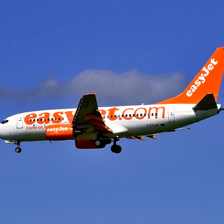


2. PREPROCESSED IMAGE
----------------------------------------
Tensor shape: (1, 3, 224, 224)
Tensor dtype: torch.float32
Device: cuda:0

3. EXTRACTED ACTIVATIONS
----------------------------------------
Spatial shape: (1, 384, 14, 14)
Pooled shape: (1, 384)

4. NUMERICAL VALIDATION
----------------------------------------
Spatial activations finite: True
Pooled activations finite: True

REAL-STIMULUS PIPELINE TEST PASSED


In [ ]:
import os
import glob
import torch
from PIL import Image
from IPython.display import display

print("=" * 65)
print("METAMER-SAE — REAL STIMULUS PIPELINE TEST")
print("=" * 65)

# Locate source images in the development set
SOURCE_DIR = os.path.join(
    STIMULUS_ROOT,
    "development",
    "source"
)

image_extensions = ("*.png", "*.jpg", "*.jpeg")

image_files = []

for extension in image_extensions:
    image_files.extend(
        glob.glob(os.path.join(SOURCE_DIR, extension))
    )

image_files = sorted(image_files)

assert len(image_files) > 0, (
    f"No images found in: {SOURCE_DIR}"
)

# Select the first image deterministically
sample_path = image_files[0]

# Load the image and ensure it is RGB
sample_image = Image.open(sample_path).convert("RGB")

print("\n1. ORIGINAL IMAGE")
print("-" * 40)
print("File:", os.path.basename(sample_path))
print("Original dimensions:", sample_image.size)
print("Image mode:", sample_image.mode)

display(sample_image)

# Apply official ConvNeXt preprocessing
sample_tensor = PREPROCESS(sample_image).unsqueeze(0).to(DEVICE)

print("\n2. PREPROCESSED IMAGE")
print("-" * 40)
print("Tensor shape:", tuple(sample_tensor.shape))
print("Tensor dtype:", sample_tensor.dtype)
print("Device:", sample_tensor.device)

# Extract Stage 3 activations
with torch.inference_mode():

    sample_spatial = observer_stage3(sample_tensor)

    sample_pooled = torch.nn.functional.adaptive_avg_pool2d(
        sample_spatial,
        output_size=1
    ).flatten(1)

print("\n3. EXTRACTED ACTIVATIONS")
print("-" * 40)
print("Spatial shape:", tuple(sample_spatial.shape))
print("Pooled shape:", tuple(sample_pooled.shape))

print("\n4. NUMERICAL VALIDATION")
print("-" * 40)

print(
    "Spatial activations finite:",
    torch.isfinite(sample_spatial).all().item()
)

print(
    "Pooled activations finite:",
    torch.isfinite(sample_pooled).all().item()
)

assert tuple(sample_tensor.shape) == (1, 3, 224, 224)
assert tuple(sample_spatial.shape) == (1, 384, 14, 14)
assert tuple(sample_pooled.shape) == (1, 384)

assert torch.isfinite(sample_spatial).all()
assert torch.isfinite(sample_pooled).all()

print("\n" + "=" * 65)
print("REAL-STIMULUS PIPELINE TEST PASSED")
print("=" * 65)

## 4. Natural-Image Training Corpus: Imagenette-320

We use Imagenette-320 as an independent natural-image corpus for learning image representations.

The dataset has two official splits:

- Training: 9,469 images.
- Validation: 3,925 images.

The training split will be used to fit PCA and the Sparse Autoencoder (SAE). The validation split will be kept separate for model-selection and reconstruction checks.

Before using the corpus, we will audit its contents and compare its images against the Feather source stimuli to identify possible overlap.

The dataset archive, extracted images, and audit manifests will be stored in the Metamer-SAE Google Drive project directory.

In [ ]:
import os
import hashlib
import tarfile
import shutil
import urllib.request

print("=" * 65)
print("METAMER-SAE — IMAGENETTE-320 DOWNLOAD")
print("=" * 65)

# --------------------------------------------------
# 1. Define persistent storage locations
# --------------------------------------------------

NATURAL_ROOT = os.path.join(
    PROJECT_ROOT,
    "natural_images"
)

DOWNLOAD_ROOT = os.path.join(
    NATURAL_ROOT,
    "downloads"
)

DATASET_ROOT = os.path.join(
    NATURAL_ROOT,
    "imagenette2-320"
)

os.makedirs(DOWNLOAD_ROOT, exist_ok=True)

ARCHIVE_PATH = os.path.join(
    DOWNLOAD_ROOT,
    "imagenette2-320.tgz"
)

TEMP_EXTRACT_ROOT = os.path.join(
    NATURAL_ROOT,
    "_imagenette_extract_temp"
)

# Official Imagenette-320 archive
DATASET_URL = (
    "https://s3.amazonaws.com/fast-ai-imageclas/"
    "imagenette2-320.tgz"
)

EXPECTED_SHA256 = (
    "569b4497c98db6dd29f335d1f109cf315"
    "fe127053cedf69010d047f0188e158c"
)

# --------------------------------------------------
# 2. Download archive if necessary
# --------------------------------------------------

def calculate_sha256(filepath):

    sha256 = hashlib.sha256()

    with open(filepath, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha256.update(chunk)

    return sha256.hexdigest()


if os.path.exists(ARCHIVE_PATH):

    print("\nExisting archive found.")

    existing_hash = calculate_sha256(ARCHIVE_PATH)

    if existing_hash == EXPECTED_SHA256:
        print("Existing archive checksum is valid.")
    else:
        print("Existing archive checksum is incorrect.")
        os.remove(ARCHIVE_PATH)

if not os.path.exists(ARCHIVE_PATH):

    print("\nDownloading Imagenette-320...")
    print("Destination:", ARCHIVE_PATH)

    urllib.request.urlretrieve(
        DATASET_URL,
        ARCHIVE_PATH
    )

    print("Download completed.")

# --------------------------------------------------
# 3. Verify archive integrity
# --------------------------------------------------

print("\nARCHIVE VALIDATION")
print("-" * 40)

actual_hash = calculate_sha256(ARCHIVE_PATH)

archive_size_mb = (
    os.path.getsize(ARCHIVE_PATH) / (1024 ** 2)
)

print("Archive size:", round(archive_size_mb, 2), "MB")
print("Expected SHA-256:", EXPECTED_SHA256)
print("Actual SHA-256:  ", actual_hash)

assert actual_hash == EXPECTED_SHA256, (
    "Archive checksum verification failed."
)

print("Checksum verified:", True)

# --------------------------------------------------
# 4. Inspect archive structure
# --------------------------------------------------

print("\nARCHIVE STRUCTURE")
print("-" * 40)

with tarfile.open(ARCHIVE_PATH, "r:gz") as archive:

    members = archive.getmembers()

    top_level_names = {
        member.name.split("/")[0]
        for member in members
        if member.name
    }

    print("Archive entries:", len(members))
    print("Top-level directories:", sorted(top_level_names))

    assert len(top_level_names) == 1, (
        "Unexpected archive structure."
    )

    top_level_name = next(iter(top_level_names))

    # Prevent unsafe archive paths
    for member in members:
        member_path = os.path.normpath(member.name)

        assert not os.path.isabs(member_path)
        assert member_path != ".."
        assert not member_path.startswith(".." + os.sep)

    # --------------------------------------------------
    # 5. Extract safely
    # --------------------------------------------------

    if not os.path.isdir(DATASET_ROOT):

        if os.path.exists(TEMP_EXTRACT_ROOT):
            shutil.rmtree(TEMP_EXTRACT_ROOT)

        os.makedirs(TEMP_EXTRACT_ROOT, exist_ok=True)

        print("\nExtracting dataset...")

        archive.extractall(
            path=TEMP_EXTRACT_ROOT,
            filter="data"
        )

        extracted_folder = os.path.join(
            TEMP_EXTRACT_ROOT,
            top_level_name
        )

        assert os.path.isdir(extracted_folder), (
            "Expected extracted dataset directory not found."
        )

        os.replace(
            extracted_folder,
            DATASET_ROOT
        )

        shutil.rmtree(TEMP_EXTRACT_ROOT)

        print("Extraction completed.")

    else:
        print("\nDataset directory already exists.")
        print("Skipping extraction.")

# --------------------------------------------------
# 6. Inspect official split directories
# --------------------------------------------------

print("\nDATASET DIRECTORY")
print("-" * 40)

print("Dataset path:", DATASET_ROOT)
print("Dataset exists:", os.path.isdir(DATASET_ROOT))

print("\nTop-level contents:")

for item in sorted(os.listdir(DATASET_ROOT)):
    print(" -", item)

print("\n" + "=" * 65)
print("IMAGENETTE-320 DOWNLOAD AND EXTRACTION COMPLETE")
print("=" * 65)

METAMER-SAE — IMAGENETTE-320 DOWNLOAD

Destination: /content/drive/MyDrive/metamer-sae/natural_images/downloads/imagenette2-320.tgz
Download completed.

ARCHIVE VALIDATION
----------------------------------------
Archive size: 325.84 MB
Expected SHA-256: 569b4497c98db6dd29f335d1f109cf315fe127053cedf69010d047f0188e158c
Actual SHA-256:   569b4497c98db6dd29f335d1f109cf315fe127053cedf69010d047f0188e158c
Checksum verified: True

ARCHIVE STRUCTURE
----------------------------------------
Archive entries: 13418
Top-level directories: ['imagenette2-320']

Extracting dataset...
Extraction completed.

DATASET DIRECTORY
----------------------------------------
Dataset path: /content/drive/MyDrive/metamer-sae/natural_images/imagenette2-320
Dataset exists: True

Top-level contents:
 - noisy_imagenette.csv
 - train
 - val

IMAGENETTE-320 DOWNLOAD AND EXTRACTION COMPLETE


### 4.2 Dataset Structure and Image Integrity Audit

We inspect the extracted Imagenette-320 dataset before using it.

For each official split, we record the class directories, image counts, file extensions, and image integrity. We also inspect sample image dimensions and colour modes.

This audit does not modify the dataset.

In [ ]:
import os
from pathlib import Path
from collections import Counter
from PIL import Image

print("=" * 65)
print("METAMER-SAE — IMAGENETTE STRUCTURE AUDIT")
print("=" * 65)

SPLITS = ["train", "val"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

dataset_summary = {}
all_image_paths = []
corrupt_images = []
unexpected_files = []

for split in SPLITS:

    split_dir = Path(DATASET_ROOT) / split

    assert split_dir.is_dir(), (
        f"Missing split directory: {split_dir}"
    )

    class_dirs = sorted(
        path for path in split_dir.iterdir()
        if path.is_dir()
    )

    print(f"\n{split.upper()} SPLIT")
    print("-" * 45)

    print("Class directories:", len(class_dirs))

    split_total = 0
    class_counts = {}
    extension_counts = Counter()

    for class_dir in class_dirs:

        image_paths = sorted(
            path for path in class_dir.rglob("*")
            if path.is_file()
            and path.suffix.lower() in IMAGE_EXTENSIONS
        )

        class_counts[class_dir.name] = len(image_paths)
        split_total += len(image_paths)

        for path in image_paths:
            extension_counts[path.suffix.lower()] += 1
            all_image_paths.append((split, class_dir.name, path))

        print(f"{class_dir.name}: {len(image_paths)} images")

    # Detect files that are not inside a class directory
    for path in split_dir.iterdir():
        if path.is_file():
            unexpected_files.append(str(path))

    dataset_summary[split] = {
        "classes": class_counts,
        "total_images": split_total,
        "extensions": dict(extension_counts)
    }

    print("\nTotal images:", split_total)
    print("File extensions:", dict(extension_counts))

# --------------------------------------------------
# Validate every image file
# --------------------------------------------------

print("\n" + "=" * 65)
print("IMAGE INTEGRITY CHECK")
print("=" * 65)

for index, (split, class_name, path) in enumerate(all_image_paths):

    try:
        with Image.open(path) as image:
            image.verify()

    except Exception as error:
        corrupt_images.append({
            "path": str(path),
            "error": str(error)
        })

print("Images checked:", len(all_image_paths))
print("Corrupt/unreadable images:", len(corrupt_images))
print("Unexpected files directly inside split folders:", len(unexpected_files))

# --------------------------------------------------
# Inspect sample image properties
# --------------------------------------------------

print("\n" + "=" * 65)
print("SAMPLE IMAGE INSPECTION")
print("=" * 65)

sampled_classes = set()

for split, class_name, path in all_image_paths:

    key = (split, class_name)

    if key in sampled_classes:
        continue

    sampled_classes.add(key)

    try:
        with Image.open(path) as image:
            print(
                f"{split}/{class_name}: "
                f"size={image.size}, "
                f"mode={image.mode}, "
                f"format={image.format}"
            )
    except Exception:
        print(f"{split}/{class_name}: sample could not be opened")

# --------------------------------------------------
# Overall summary
# --------------------------------------------------

train_count = dataset_summary["train"]["total_images"]
val_count = dataset_summary["val"]["total_images"]

print("\n" + "=" * 65)
print("FINAL DATASET SUMMARY")
print("=" * 65)

print("Training images:", train_count)
print("Validation images:", val_count)
print("Total images:", train_count + val_count)
print("Training classes:", len(dataset_summary["train"]["classes"]))
print("Validation classes:", len(dataset_summary["val"]["classes"]))
print("Corrupt images:", len(corrupt_images))

print("\nExpected reference counts:")
print("Training: 9,469")
print("Validation: 3,925")
print("Total: 13,394")

print("\nCount comparison:")
print("Training count matches:", train_count == 9469)
print("Validation count matches:", val_count == 3925)

print("\n" + "=" * 65)
print("STRUCTURE AUDIT COMPLETE")
print("=" * 65)

METAMER-SAE — IMAGENETTE STRUCTURE AUDIT

TRAIN SPLIT
---------------------------------------------
Class directories: 10
n01440764: 963 images
n02102040: 955 images
n02979186: 993 images
n03000684: 858 images
n03028079: 941 images
n03394916: 956 images
n03417042: 961 images
n03425413: 931 images
n03445777: 951 images
n03888257: 960 images

Total images: 9469
File extensions: {'.jpeg': 9469}

VAL SPLIT
---------------------------------------------
Class directories: 10
n01440764: 387 images
n02102040: 395 images
n02979186: 357 images
n03000684: 386 images
n03028079: 409 images
n03394916: 394 images
n03417042: 389 images
n03425413: 419 images
n03445777: 399 images
n03888257: 390 images

Total images: 3925
File extensions: {'.jpeg': 3925}

IMAGE INTEGRITY CHECK
Images checked: 13394
Corrupt/unreadable images: 0
Unexpected files directly inside split folders: 0

SAMPLE IMAGE INSPECTION
train/n01440764: size=(426, 320), mode=RGB, format=JPEG
train/n02102040: size=(479, 320), mode=RGB, form

### 4.3 Create Reproducible Dataset Manifests

We create file-level manifests for the natural-image corpus and the Feather stimuli.

Each image is recorded with its dataset split, category or condition, relative file path, image dimensions, colour mode, file format, and SHA-256 hash.

These manifests provide traceability for the subsequent duplicate audit and activation extraction. They also allow us to identify precisely which images were used in each experiment.

This is an inventory operation only. It does not modify, move, or delete any images.

In [ ]:
import os
import csv
import hashlib
from pathlib import Path
from PIL import Image
from collections import Counter

print("=" * 70)
print("METAMER-SAE — DATASET MANIFEST CREATION")
print("=" * 70)

# --------------------------------------------------
# 1. Define paths
# --------------------------------------------------

NATURAL_ROOT = os.path.join(PROJECT_ROOT, "natural_images")

MANIFEST_ROOT = os.path.join(
    NATURAL_ROOT,
    "manifests"
)

os.makedirs(MANIFEST_ROOT, exist_ok=True)

IMAGENETTE_ROOT = os.path.join(
    NATURAL_ROOT,
    "imagenette2-320"
)

FEATHER_ROOT = STIMULUS_ROOT

NATURAL_MANIFEST_PATH = os.path.join(
    MANIFEST_ROOT,
    "imagenette_image_manifest.csv"
)

FEATHER_MANIFEST_PATH = os.path.join(
    MANIFEST_ROOT,
    "feather_stimulus_inventory.csv"
)

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}


# --------------------------------------------------
# 2. Helper functions
# --------------------------------------------------

def calculate_sha256(filepath):

    sha256 = hashlib.sha256()

    with open(filepath, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha256.update(chunk)

    return sha256.hexdigest()


def inspect_image(filepath):

    with Image.open(filepath) as image:

        return {
            "width": image.width,
            "height": image.height,
            "mode": image.mode,
            "format": image.format
        }


# --------------------------------------------------
# 3. Create Imagenette manifest
# --------------------------------------------------

print("\n1. IMAGENETTE MANIFEST")
print("-" * 45)

natural_records = []

for split in ["train", "val"]:

    split_root = Path(IMAGENETTE_ROOT) / split

    for image_path in sorted(split_root.rglob("*")):

        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        class_name = image_path.parent.name

        image_info = inspect_image(image_path)

        record = {
            "dataset": "imagenette2-320",
            "split": split,
            "class": class_name,
            "filename": image_path.name,
            "relative_path": os.path.relpath(
                image_path,
                PROJECT_ROOT
            ),
            "width": image_info["width"],
            "height": image_info["height"],
            "mode": image_info["mode"],
            "format": image_info["format"],
            "sha256": calculate_sha256(image_path)
        }

        natural_records.append(record)


natural_fields = [
    "dataset",
    "split",
    "class",
    "filename",
    "relative_path",
    "width",
    "height",
    "mode",
    "format",
    "sha256"
]

with open(
    NATURAL_MANIFEST_PATH,
    "w",
    newline="",
    encoding="utf-8"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=natural_fields
    )

    writer.writeheader()
    writer.writerows(natural_records)


natural_split_counts = Counter(
    record["split"] for record in natural_records
)

natural_class_counts = Counter(
    (record["split"], record["class"])
    for record in natural_records
)

print("Images recorded:", len(natural_records))
print("Training images:", natural_split_counts["train"])
print("Validation images:", natural_split_counts["val"])
print("Unique SHA-256 hashes:", len({
    record["sha256"] for record in natural_records
}))
print("Manifest:", NATURAL_MANIFEST_PATH)


# --------------------------------------------------
# 4. Create Feather stimulus inventory
# --------------------------------------------------

print("\n2. FEATHER STIMULUS INVENTORY")
print("-" * 45)

feather_records = []

for split in ["development", "primary_evaluation", "reserve"]:

    for condition in [
        "source",
        "standard_resnet50",
        "adversarial_resnet50"
    ]:

        condition_root = Path(
            FEATHER_ROOT
        ) / split / condition

        if not condition_root.is_dir():

            print(
                "WARNING — Missing directory:",
                condition_root
            )

            continue

        for image_path in sorted(condition_root.rglob("*")):

            if not image_path.is_file():
                continue

            if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue

            image_info = inspect_image(image_path)

            record = {
                "dataset": "feather",
                "split": split,
                "condition": condition,
                "filename": image_path.name,
                "relative_path": os.path.relpath(
                    image_path,
                    PROJECT_ROOT
                ),
                "width": image_info["width"],
                "height": image_info["height"],
                "mode": image_info["mode"],
                "format": image_info["format"],
                "sha256": calculate_sha256(image_path)
            }

            feather_records.append(record)


feather_fields = [
    "dataset",
    "split",
    "condition",
    "filename",
    "relative_path",
    "width",
    "height",
    "mode",
    "format",
    "sha256"
]

with open(
    FEATHER_MANIFEST_PATH,
    "w",
    newline="",
    encoding="utf-8"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=feather_fields
    )

    writer.writeheader()
    writer.writerows(feather_records)


feather_split_counts = Counter(
    record["split"] for record in feather_records
)

feather_condition_counts = Counter(
    record["condition"] for record in feather_records
)

print("Total Feather images recorded:", len(feather_records))

print("\nImages by evaluation split:")

for split in [
    "development",
    "primary_evaluation",
    "reserve"
]:
    print(
        f"{split}:",
        feather_split_counts[split]
    )

print("\nImages by condition:")

for condition in [
    "source",
    "standard_resnet50",
    "adversarial_resnet50"
]:
    print(
        f"{condition}:",
        feather_condition_counts[condition]
    )

print("Unique Feather SHA-256 hashes:", len({
    record["sha256"] for record in feather_records
}))

print("Manifest:", FEATHER_MANIFEST_PATH)


# --------------------------------------------------
# 5. Final summary
# --------------------------------------------------

print("\n" + "=" * 70)
print("MANIFEST CREATION SUMMARY")
print("=" * 70)

print("Imagenette images:", len(natural_records))
print("Feather images:", len(feather_records))

print(
    "Expected Feather images:",
    48 * 3
)

print(
    "Feather inventory count matches expectation:",
    len(feather_records) == 144
)

print("\nSaved files:")

print(" -", NATURAL_MANIFEST_PATH)
print(" -", FEATHER_MANIFEST_PATH)

print("\n" + "=" * 70)
print("MANIFEST CREATION COMPLETE")
print("=" * 70)

METAMER-SAE — DATASET MANIFEST CREATION

1. IMAGENETTE MANIFEST
---------------------------------------------
Images recorded: 13394
Training images: 9469
Validation images: 3925
Unique SHA-256 hashes: 13394
Manifest: /content/drive/MyDrive/metamer-sae/natural_images/manifests/imagenette_image_manifest.csv

2. FEATHER STIMULUS INVENTORY
---------------------------------------------
Total Feather images recorded: 144

Images by evaluation split:
development: 24
primary_evaluation: 96
reserve: 24

Images by condition:
source: 48
standard_resnet50: 48
adversarial_resnet50: 48
Unique Feather SHA-256 hashes: 144
Manifest: /content/drive/MyDrive/metamer-sae/natural_images/manifests/feather_stimulus_inventory.csv

MANIFEST CREATION SUMMARY
Imagenette images: 13394
Feather images: 144
Expected Feather images: 144
Feather inventory count matches expectation: True

Saved files:
 - /content/drive/MyDrive/metamer-sae/natural_images/manifests/imagenette_image_manifest.csv
 - /content/drive/MyDrive/

### 4.4 Exact Duplicate Audit: Imagenette vs Feather

We compare the SHA-256 hashes of every Imagenette image against every Feather stimulus image.

A matching SHA-256 hash indicates that the two files are byte-for-byte identical.

We compare the complete Feather inventory, including source images and both metamer conditions, against both Imagenette splits.

Any matches will be recorded with their file paths and dataset conditions. They will not be automatically deleted or excluded; we will inspect them first.

This is the exact-duplicate check only. Different encodings, resized images, and crops will be investigated separately using perceptual hashing.

In [ ]:
import os
import csv
import json
from collections import defaultdict

print("=" * 70)
print("METAMER-SAE — EXACT DUPLICATE AUDIT")
print("=" * 70)

# --------------------------------------------------
# 1. Define manifest paths
# --------------------------------------------------

NATURAL_MANIFEST_PATH = os.path.join(
    MANIFEST_ROOT,
    "imagenette_image_manifest.csv"
)

FEATHER_MANIFEST_PATH = os.path.join(
    MANIFEST_ROOT,
    "feather_stimulus_inventory.csv"
)

EXACT_MATCH_PATH = os.path.join(
    MANIFEST_ROOT,
    "exact_duplicate_matches.csv"
)

EXACT_SUMMARY_PATH = os.path.join(
    MANIFEST_ROOT,
    "exact_duplicate_audit_summary.json"
)

# --------------------------------------------------
# 2. Load the two manifests
# --------------------------------------------------

with open(NATURAL_MANIFEST_PATH, newline="", encoding="utf-8") as file:
    natural_records = list(csv.DictReader(file))

with open(FEATHER_MANIFEST_PATH, newline="", encoding="utf-8") as file:
    feather_records = list(csv.DictReader(file))

print("\n1. MANIFESTS LOADED")
print("-" * 45)

print("Imagenette records:", len(natural_records))
print("Feather records:", len(feather_records))

assert len(natural_records) == 13394
assert len(feather_records) == 144

# --------------------------------------------------
# 3. Index Imagenette hashes
# --------------------------------------------------

natural_hash_index = defaultdict(list)

for record in natural_records:
    natural_hash_index[record["sha256"]].append(record)

# --------------------------------------------------
# 4. Compare every Feather hash
# --------------------------------------------------

exact_matches = []

for feather_record in feather_records:

    matching_natural_records = natural_hash_index.get(
        feather_record["sha256"],
        []
    )

    for natural_record in matching_natural_records:

        exact_matches.append({
            "imagenette_split": natural_record["split"],
            "imagenette_class": natural_record["class"],
            "imagenette_path": natural_record["relative_path"],
            "feather_split": feather_record["split"],
            "feather_condition": feather_record["condition"],
            "feather_path": feather_record["relative_path"],
            "sha256": feather_record["sha256"]
        })

# --------------------------------------------------
# 5. Save exact matches
# --------------------------------------------------

match_fields = [
    "imagenette_split",
    "imagenette_class",
    "imagenette_path",
    "feather_split",
    "feather_condition",
    "feather_path",
    "sha256"
]

with open(
    EXACT_MATCH_PATH,
    "w",
    newline="",
    encoding="utf-8"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=match_fields
    )

    writer.writeheader()
    writer.writerows(exact_matches)

# --------------------------------------------------
# 6. Summarize results
# --------------------------------------------------

matched_natural_paths = sorted({
    match["imagenette_path"]
    for match in exact_matches
})

matched_feather_paths = sorted({
    match["feather_path"]
    for match in exact_matches
})

summary = {
    "audit": "exact_sha256_duplicate_comparison",
    "imagenette_images_compared": len(natural_records),
    "feather_images_compared": len(feather_records),
    "exact_match_pairs": len(exact_matches),
    "unique_imagenette_images_matched": len(matched_natural_paths),
    "unique_feather_images_matched": len(matched_feather_paths),
    "result": (
        "no_exact_duplicates_found"
        if len(exact_matches) == 0
        else "exact_duplicates_found_require_inspection"
    ),
    "matches": exact_matches
}

with open(
    EXACT_SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(summary, file, indent=2)

# --------------------------------------------------
# 7. Report
# --------------------------------------------------

print("\n2. EXACT HASH COMPARISON")
print("-" * 45)

print(
    "Imagenette unique hashes:",
    len(natural_hash_index)
)

print(
    "Feather hashes compared:",
    len(feather_records)
)

print(
    "Exact matching image pairs:",
    len(exact_matches)
)

print(
    "Unique Imagenette images matched:",
    len(matched_natural_paths)
)

print(
    "Unique Feather images matched:",
    len(matched_feather_paths)
)

print("\n3. RESULT")
print("-" * 45)

if len(exact_matches) == 0:

    print("No byte-for-byte duplicates found.")
    print("Exact duplicate check passed.")

else:

    print("Exact duplicates detected.")
    print("These images require inspection before exclusion.")

    for match in exact_matches[:20]:

        print("\nImagenette:", match["imagenette_path"])
        print("Feather:", match["feather_path"])
        print("Feather condition:", match["feather_condition"])

    if len(exact_matches) > 20:
        print("\nOnly the first 20 matches are displayed.")

print("\n4. SAVED AUDIT FILES")
print("-" * 45)

print("Exact matches CSV:", EXACT_MATCH_PATH)
print("Audit summary JSON:", EXACT_SUMMARY_PATH)

print("\n" + "=" * 70)
print("EXACT DUPLICATE AUDIT COMPLETE")
print("=" * 70)

METAMER-SAE — EXACT DUPLICATE AUDIT

1. MANIFESTS LOADED
---------------------------------------------
Imagenette records: 13394
Feather records: 144

2. EXACT HASH COMPARISON
---------------------------------------------
Imagenette unique hashes: 13394
Feather hashes compared: 144
Exact matching image pairs: 0
Unique Imagenette images matched: 0
Unique Feather images matched: 0

3. RESULT
---------------------------------------------
No byte-for-byte duplicates found.
Exact duplicate check passed.

4. SAVED AUDIT FILES
---------------------------------------------
Exact matches CSV: /content/drive/MyDrive/metamer-sae/natural_images/manifests/exact_duplicate_matches.csv
Audit summary JSON: /content/drive/MyDrive/metamer-sae/natural_images/manifests/exact_duplicate_audit_summary.json

EXACT DUPLICATE AUDIT COMPLETE


### 4.5a Inspect Image Paths for Perceptual Hashing

Before running the perceptual duplicate audit, inspect the two manifests to confirm how image paths are stored.

We need to identify the correct on-disk location of every Imagenette and Feather image. This ensures that the perceptual hashing procedure compares the actual image files rather than relying on assumed directory structures.

In [ ]:
import csv
import os

NATURAL_MANIFEST_PATH = os.path.join(
    MANIFEST_ROOT,
    "imagenette_image_manifest.csv"
)

FEATHER_MANIFEST_PATH = os.path.join(
    MANIFEST_ROOT,
    "feather_stimulus_inventory.csv"
)

with open(NATURAL_MANIFEST_PATH, newline="", encoding="utf-8") as file:
    natural_records = list(csv.DictReader(file))

with open(FEATHER_MANIFEST_PATH, newline="", encoding="utf-8") as file:
    feather_records = list(csv.DictReader(file))

print("=" * 70)
print("METAMER-SAE — IMAGE PATH DIAGNOSTIC")
print("=" * 70)

print("\n1. IMAGENETTE MANIFEST")
print("-" * 45)

print("Columns:")
print(list(natural_records[0].keys()))

print("\nFirst record:")
for key, value in natural_records[0].items():
    print(f"{key}: {value}")

print("\n2. FEATHER MANIFEST")
print("-" * 45)

print("Columns:")
print(list(feather_records[0].keys()))

print("\nFirst record:")
for key, value in feather_records[0].items():
    print(f"{key}: {value}")

print("\n3. PATH EXISTENCE CHECK")
print("-" * 45)

for label, records in [
    ("Imagenette", natural_records),
    ("Feather", feather_records)
]:
    record = records[0]
    print(f"\n{label}:")

    for key, value in record.items():
        if "path" in key.lower():
            print(
                f"{key}: {value} | "
                f"exists as written: {os.path.exists(value)}"
            )

print("\n" + "=" * 70)
print("PATH DIAGNOSTIC COMPLETE")
print("=" * 70)

METAMER-SAE — IMAGE PATH DIAGNOSTIC

1. IMAGENETTE MANIFEST
---------------------------------------------
Columns:
['dataset', 'split', 'class', 'filename', 'relative_path', 'width', 'height', 'mode', 'format', 'sha256']

First record:
dataset: imagenette2-320
split: train
class: n01440764
filename: ILSVRC2012_val_00000293.JPEG
relative_path: natural_images/imagenette2-320/train/n01440764/ILSVRC2012_val_00000293.JPEG
width: 426
height: 320
mode: RGB
format: JPEG
sha256: 86b7d6256b76e9f701de31fbe39b11e899024a1a929fd84d8fbf4eb4c7f5c592

2. FEATHER MANIFEST
---------------------------------------------
Columns:
['dataset', 'split', 'condition', 'filename', 'relative_path', 'width', 'height', 'mode', 'format', 'sha256']

First record:
dataset: feather
split: development
condition: source
filename: feather_0000_source.png
relative_path: stimuli/development/source/feather_0000_source.png
width: 224
height: 224
mode: RGB
format: PNG
sha256: 1eebae7476f66cb9e68a733135b79fbb5c4a9e20796e5415fa61

### 4.5b Verify Full Image Paths

The manifests store paths relative to the project root. We therefore reconstruct each full path by joining the project root with its recorded relative path.

Before perceptual hashing, verify that all 13,394 Imagenette images and all 144 Feather stimuli can be located on disk.

This is a file-location check only; no images are modified.

In [ ]:
import os

print("=" * 70)
print("METAMER-SAE — FULL IMAGE PATH VERIFICATION")
print("=" * 70)

assert os.path.isdir(PROJECT_ROOT), (
    f"Project root does not exist: {PROJECT_ROOT}"
)

print("\nProject root:")
print(PROJECT_ROOT)

# Reconstruct full paths from the relative paths in each manifest.
natural_full_paths = [
    os.path.join(PROJECT_ROOT, record["relative_path"])
    for record in natural_records
]

feather_full_paths = [
    os.path.join(PROJECT_ROOT, record["relative_path"])
    for record in feather_records
]

# Check all paths.
missing_natural = [
    path for path in natural_full_paths
    if not os.path.isfile(path)
]

missing_feather = [
    path for path in feather_full_paths
    if not os.path.isfile(path)
]

print("\n1. IMAGENETTE PATH CHECK")
print("-" * 45)
print("Total paths:", len(natural_full_paths))
print("Existing files:", len(natural_full_paths) - len(missing_natural))
print("Missing files:", len(missing_natural))

print("\n2. FEATHER PATH CHECK")
print("-" * 45)
print("Total paths:", len(feather_full_paths))
print("Existing files:", len(feather_full_paths) - len(missing_feather))
print("Missing files:", len(missing_feather))

print("\n3. EXAMPLE RECONSTRUCTED PATHS")
print("-" * 45)

print("\nImagenette:")
print(natural_full_paths[0])
print("Exists:", os.path.isfile(natural_full_paths[0]))

print("\nFeather:")
print(feather_full_paths[0])
print("Exists:", os.path.isfile(feather_full_paths[0]))

print("\n4. VERIFICATION RESULT")
print("-" * 45)

if not missing_natural and not missing_feather:
    print("All image paths verified successfully.")
else:
    print("Some image paths could not be found.")

    for path in (missing_natural + missing_feather)[:10]:
        print("MISSING:", path)

assert not missing_natural, (
    f"{len(missing_natural)} Imagenette files are missing."
)

assert not missing_feather, (
    f"{len(missing_feather)} Feather files are missing."
)

print("\n" + "=" * 70)
print("FULL IMAGE PATH VERIFICATION COMPLETE")
print("=" * 70)

METAMER-SAE — FULL IMAGE PATH VERIFICATION

Project root:
/content/drive/MyDrive/metamer-sae

1. IMAGENETTE PATH CHECK
---------------------------------------------
Total paths: 13394
Existing files: 13394
Missing files: 0

2. FEATHER PATH CHECK
---------------------------------------------
Total paths: 144
Existing files: 144
Missing files: 0

3. EXAMPLE RECONSTRUCTED PATHS
---------------------------------------------

Imagenette:
/content/drive/MyDrive/metamer-sae/natural_images/imagenette2-320/train/n01440764/ILSVRC2012_val_00000293.JPEG
Exists: True

Feather:
/content/drive/MyDrive/metamer-sae/stimuli/development/source/feather_0000_source.png
Exists: True

4. VERIFICATION RESULT
---------------------------------------------
All image paths verified successfully.

FULL IMAGE PATH VERIFICATION COMPLETE


### 4.5c Install ImageHash

Install ImageHash to calculate perceptual hashes for the Imagenette and Feather images.

Perceptual hashes summarize visual image structure. We will use them to identify potentially similar images even when their file formats, dimensions, or encodings differ.

This installation does not modify the original image files.

In [ ]:
%pip install -q ImageHash

In [ ]:
import imagehash
from PIL import Image

print("ImageHash version:", imagehash.__version__)
print("Pillow version:", Image.__version__)
print("Perceptual hashing dependency check passed.")

ImageHash version: 4.3.2
Pillow version: 11.3.0
Perceptual hashing dependency check passed.


### 4.5d Perceptual Hashing and Cross-Dataset Similarity Comparison

Calculate 64-bit perceptual hashes (pHash) for all Imagenette and Feather images.

For every Feather image, compare its hash against all Imagenette hashes using Hamming distance.

The Hamming distance measures the number of differing bits between two hashes:
- 0–4: strong visual-similarity candidates.
- 5–8: possible visual-similarity candidates.
- Greater than 8: not included in the initial candidate inspection list.

These thresholds are screening criteria, not definitive duplicate classifications.

The procedure records:
1. Per-image perceptual hashes.
2. The nearest Imagenette match for each Feather image.
3. All candidate pairs with distance 8 or less.
4. A summary of the audit.

No images are deleted or modified.

In [ ]:
import os
import csv
import json
import time
from PIL import Image
import imagehash

print("=" * 70)
print("METAMER-SAE — PERCEPTUAL HASH AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. OUTPUT PATHS
# ------------------------------------------------------------

PHASH_MANIFEST_PATH = os.path.join(
    MANIFEST_ROOT,
    "perceptual_hash_manifest.csv"
)

PHASH_NEAREST_PATH = os.path.join(
    MANIFEST_ROOT,
    "perceptual_hash_nearest_matches.csv"
)

PHASH_CANDIDATES_PATH = os.path.join(
    MANIFEST_ROOT,
    "perceptual_hash_candidate_matches.csv"
)

PHASH_SUMMARY_PATH = os.path.join(
    MANIFEST_ROOT,
    "perceptual_hash_audit_summary.json"
)

# ------------------------------------------------------------
# 2. HASHING CONFIGURATION
# ------------------------------------------------------------

PHASH_HASH_SIZE = 8
CANDIDATE_THRESHOLD = 8
STRONG_THRESHOLD = 4

print("\n1. CONFIGURATION")
print("-" * 45)

print("Hash algorithm: pHash")
print("Hash size:", PHASH_HASH_SIZE)
print("Hash length:", PHASH_HASH_SIZE ** 2, "bits")
print("Strong candidate threshold:", STRONG_THRESHOLD)
print("Candidate threshold:", CANDIDATE_THRESHOLD)

# ------------------------------------------------------------
# 3. CALCULATE IMAGENETTE HASHES
# ------------------------------------------------------------

print("\n2. CALCULATING IMAGENETTE HASHES")
print("-" * 45)

start_time = time.time()

imagenette_hash_records = []
imagenette_hash_errors = []

for index, record in enumerate(natural_records, start=1):

    image_path = os.path.join(
        PROJECT_ROOT,
        record["relative_path"]
    )

    try:
        with Image.open(image_path) as image:
            image = image.convert("RGB")
            phash = imagehash.phash(
                image,
                hash_size=PHASH_HASH_SIZE
            )

        imagenette_hash_records.append({
            "dataset": "imagenette",
            "split": record["split"],
            "condition": "",
            "relative_path": record["relative_path"],
            "phash": str(phash)
        })

    except Exception as error:
        imagenette_hash_errors.append({
            "path": record["relative_path"],
            "error": str(error)
        })

    if index % 2000 == 0:
        print(f"Processed {index:,}/{len(natural_records):,}")

print(
    "Imagenette hashing time:",
    round(time.time() - start_time, 2),
    "seconds"
)

# ------------------------------------------------------------
# 4. CALCULATE FEATHER HASHES
# ------------------------------------------------------------

print("\n3. CALCULATING FEATHER HASHES")
print("-" * 45)

start_time = time.time()

feather_hash_records = []
feather_hash_errors = []

for index, record in enumerate(feather_records, start=1):

    image_path = os.path.join(
        PROJECT_ROOT,
        record["relative_path"]
    )

    try:
        with Image.open(image_path) as image:
            image = image.convert("RGB")
            phash = imagehash.phash(
                image,
                hash_size=PHASH_HASH_SIZE
            )

        feather_hash_records.append({
            "dataset": "feather",
            "split": record["split"],
            "condition": record["condition"],
            "relative_path": record["relative_path"],
            "phash": str(phash)
        })

    except Exception as error:
        feather_hash_errors.append({
            "path": record["relative_path"],
            "error": str(error)
        })

print(
    "Feather hashing time:",
    round(time.time() - start_time, 2),
    "seconds"
)

# ------------------------------------------------------------
# 5. VERIFY HASHING COMPLETENESS
# ------------------------------------------------------------

print("\n4. HASHING VALIDATION")
print("-" * 45)

print("Imagenette hashes:", len(imagenette_hash_records))
print("Feather hashes:", len(feather_hash_records))

print("Imagenette hashing errors:", len(imagenette_hash_errors))
print("Feather hashing errors:", len(feather_hash_errors))

assert len(imagenette_hash_records) == len(natural_records)
assert len(feather_hash_records) == len(feather_records)
assert len(imagenette_hash_errors) == 0
assert len(feather_hash_errors) == 0

# Convert hexadecimal hash strings to integers.
# This allows efficient bitwise XOR and bit counting.

imagenette_hash_values = [
    int(record["phash"], 16)
    for record in imagenette_hash_records
]

feather_hash_values = [
    int(record["phash"], 16)
    for record in feather_hash_records
]

# ------------------------------------------------------------
# 6. COMPARE ALL FEATHER-IMAGENETTE PAIRS
# ------------------------------------------------------------

print("\n5. CROSS-DATASET COMPARISON")
print("-" * 45)

start_time = time.time()

nearest_matches = []
candidate_matches = []

for feather_index, feather_record in enumerate(
    feather_hash_records
):

    feather_hash = feather_hash_values[feather_index]

    nearest_distance = PHASH_HASH_SIZE ** 2
    nearest_natural_index = None

    for natural_index, natural_hash in enumerate(
        imagenette_hash_values
    ):

        distance = (
            feather_hash ^ natural_hash
        ).bit_count()

        if distance < nearest_distance:
            nearest_distance = distance
            nearest_natural_index = natural_index

        if distance <= CANDIDATE_THRESHOLD:

            natural_record = imagenette_hash_records[
                natural_index
            ]

            candidate_matches.append({
                "feather_split": feather_record["split"],
                "feather_condition": feather_record["condition"],
                "feather_path": feather_record["relative_path"],
                "feather_phash": feather_record["phash"],
                "imagenette_split": natural_record["split"],
                "imagenette_path": natural_record["relative_path"],
                "imagenette_phash": natural_record["phash"],
                "hamming_distance": distance
            })

    nearest_record = imagenette_hash_records[
        nearest_natural_index
    ]

    nearest_matches.append({
        "feather_split": feather_record["split"],
        "feather_condition": feather_record["condition"],
        "feather_path": feather_record["relative_path"],
        "feather_phash": feather_record["phash"],
        "nearest_imagenette_split": nearest_record["split"],
        "nearest_imagenette_path": nearest_record["relative_path"],
        "nearest_imagenette_phash": nearest_record["phash"],
        "hamming_distance": nearest_distance
    })

    print(
        f"Compared Feather image {feather_index + 1}/"
        f"{len(feather_hash_records)} | "
        f"Nearest distance: {nearest_distance}"
    )

comparison_time = time.time() - start_time

# ------------------------------------------------------------
# 7. SAVE ALL PERCEPTUAL HASHES
# ------------------------------------------------------------

all_hash_records = (
    imagenette_hash_records + feather_hash_records
)

with open(
    PHASH_MANIFEST_PATH,
    "w",
    newline="",
    encoding="utf-8"
) as file:

    fields = [
        "dataset",
        "split",
        "condition",
        "relative_path",
        "phash"
    ]

    writer = csv.DictWriter(
        file,
        fieldnames=fields
    )

    writer.writeheader()
    writer.writerows(all_hash_records)

# ------------------------------------------------------------
# 8. SAVE NEAREST MATCHES
# ------------------------------------------------------------

with open(
    PHASH_NEAREST_PATH,
    "w",
    newline="",
    encoding="utf-8"
) as file:

    fields = list(nearest_matches[0].keys())

    writer = csv.DictWriter(
        file,
        fieldnames=fields
    )

    writer.writeheader()
    writer.writerows(nearest_matches)

# ------------------------------------------------------------
# 9. SAVE CANDIDATE MATCHES
# ------------------------------------------------------------

candidate_fields = [
    "feather_split",
    "feather_condition",
    "feather_path",
    "feather_phash",
    "imagenette_split",
    "imagenette_path",
    "imagenette_phash",
    "hamming_distance"
]

with open(
    PHASH_CANDIDATES_PATH,
    "w",
    newline="",
    encoding="utf-8"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=candidate_fields
    )

    writer.writeheader()
    writer.writerows(candidate_matches)

# ------------------------------------------------------------
# 10. SUMMARIZE RESULTS
# ------------------------------------------------------------

strong_candidates = [
    match for match in candidate_matches
    if match["hamming_distance"] <= STRONG_THRESHOLD
]

possible_candidates = [
    match for match in candidate_matches
    if STRONG_THRESHOLD < match["hamming_distance"]
    <= CANDIDATE_THRESHOLD
]

nearest_distances = [
    match["hamming_distance"]
    for match in nearest_matches
]

summary = {
    "audit": "cross_dataset_perceptual_hash_comparison",
    "algorithm": "pHash",
    "hash_size": PHASH_HASH_SIZE,
    "hash_bits": PHASH_HASH_SIZE ** 2,
    "imagenette_images": len(imagenette_hash_records),
    "feather_images": len(feather_hash_records),
    "total_pairwise_comparisons": (
        len(imagenette_hash_records) *
        len(feather_hash_records)
    ),
    "hashing_errors": {
        "imagenette": len(imagenette_hash_errors),
        "feather": len(feather_hash_errors)
    },
    "candidate_threshold": CANDIDATE_THRESHOLD,
    "strong_threshold": STRONG_THRESHOLD,
    "candidate_pairs_distance_0_to_4": len(strong_candidates),
    "candidate_pairs_distance_5_to_8": len(possible_candidates),
    "candidate_pairs_total": len(candidate_matches),
    "feather_images_with_nearest_distance_0": sum(
        distance == 0 for distance in nearest_distances
    ),
    "minimum_nearest_distance": min(nearest_distances),
    "maximum_nearest_distance": max(nearest_distances),
    "mean_nearest_distance": (
        sum(nearest_distances) / len(nearest_distances)
    ),
    "comparison_time_seconds": round(comparison_time, 2),
    "result": (
        "no_candidates_within_threshold"
        if len(candidate_matches) == 0
        else "visual_similarity_candidates_require_inspection"
    )
}

with open(
    PHASH_SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(summary, file, indent=2)

# ------------------------------------------------------------
# 11. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n6. PERCEPTUAL HASH RESULTS")
print("-" * 45)

print("Total pairwise comparisons:",
      f"{summary['total_pairwise_comparisons']:,}")

print("Candidate pairs (distance 0–4):",
      len(strong_candidates))

print("Candidate pairs (distance 5–8):",
      len(possible_candidates))

print("Total candidate pairs:",
      len(candidate_matches))

print("Minimum nearest distance:",
      summary["minimum_nearest_distance"])

print("Mean nearest distance:",
      round(summary["mean_nearest_distance"], 2))

print("Maximum nearest distance:",
      summary["maximum_nearest_distance"])

print("\n7. NEAREST MATCH FOR EACH FEATHER IMAGE")
print("-" * 45)

for match in nearest_matches:

    print(
        f"{match['feather_path']} | "
        f"Nearest distance: {match['hamming_distance']} | "
        f"Imagenette: {match['nearest_imagenette_path']}"
    )

print("\n8. SAVED AUDIT FILES")
print("-" * 45)

print("Perceptual hash manifest:", PHASH_MANIFEST_PATH)
print("Nearest matches:", PHASH_NEAREST_PATH)
print("Candidate matches:", PHASH_CANDIDATES_PATH)
print("Summary:", PHASH_SUMMARY_PATH)

print("\n" + "=" * 70)
print("PERCEPTUAL HASH AUDIT COMPLETE")
print("=" * 70)

METAMER-SAE — PERCEPTUAL HASH AUDIT

1. CONFIGURATION
---------------------------------------------
Hash algorithm: pHash
Hash size: 8
Hash length: 64 bits
Strong candidate threshold: 4
Candidate threshold: 8

2. CALCULATING IMAGENETTE HASHES
---------------------------------------------
Processed 2,000/13,394
Processed 4,000/13,394
Processed 6,000/13,394
Processed 8,000/13,394
Processed 10,000/13,394
Processed 12,000/13,394
Imagenette hashing time: 57.73 seconds

3. CALCULATING FEATHER HASHES
---------------------------------------------
Feather hashing time: 0.7 seconds

4. HASHING VALIDATION
---------------------------------------------
Imagenette hashes: 13394
Feather hashes: 144
Imagenette hashing errors: 0
Feather hashing errors: 0

5. CROSS-DATASET COMPARISON
---------------------------------------------
Compared Feather image 1/144 | Nearest distance: 16
Compared Feather image 2/144 | Nearest distance: 16
Compared Feather image 3/144 | Nearest distance: 16
Compared Feather imag

### 4.6 Consolidated Cross-Dataset Independence Audit

Combine the exact SHA-256 duplicate audit and perceptual-hash similarity audit into one final report.

The audit covers:
- All Imagenette training and validation images.
- All Feather source images.
- All standard ResNet50 metamer images.
- All adversarial ResNet50 metamer images.

An image is not excluded merely because it belongs to one of these datasets. Exclusions are only recorded when an overlap candidate has been identified and investigated.

The current audits found:
- No byte-for-byte duplicates.
- No perceptual-hash candidates at Hamming distance 8 or below.

Therefore, no exclusions are currently indicated by these two checks.

This result supports cross-dataset separation under the methods tested. It does not prove the absence of every possible transformed, cropped, or semantically related image.

In [ ]:
import os
import csv
import json
from datetime import datetime, timezone

print("=" * 70)
print("METAMER-SAE — CONSOLIDATED DATASET INDEPENDENCE AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD PREVIOUS AUDIT RESULTS
# ------------------------------------------------------------

EXACT_SUMMARY_PATH = os.path.join(
    MANIFEST_ROOT,
    "exact_duplicate_audit_summary.json"
)

PHASH_SUMMARY_PATH = os.path.join(
    MANIFEST_ROOT,
    "perceptual_hash_audit_summary.json"
)

with open(EXACT_SUMMARY_PATH, encoding="utf-8") as file:
    exact_summary = json.load(file)

with open(PHASH_SUMMARY_PATH, encoding="utf-8") as file:
    phash_summary = json.load(file)

# ------------------------------------------------------------
# 2. VERIFY AUDIT COMPLETENESS
# ------------------------------------------------------------

assert exact_summary["imagenette_images_compared"] == 13394
assert exact_summary["feather_images_compared"] == 144
assert exact_summary["exact_match_pairs"] == 0

assert phash_summary["imagenette_images"] == 13394
assert phash_summary["feather_images"] == 144
assert phash_summary["total_pairwise_comparisons"] == 1928736

assert phash_summary["hashing_errors"]["imagenette"] == 0
assert phash_summary["hashing_errors"]["feather"] == 0

assert phash_summary["candidate_pairs_total"] == 0

# ------------------------------------------------------------
# 3. CREATE CONSOLIDATED AUDIT
# ------------------------------------------------------------

consolidated_audit = {
    "project": "metamer-sae",
    "audit": "cross_dataset_independence_audit",
    "created_utc": datetime.now(timezone.utc).isoformat(),

    "datasets": {
        "imagenette": {
            "training_images": 9469,
            "validation_images": 3925,
            "total_images": 13394
        },
        "feather": {
            "development_images": 24,
            "primary_evaluation_images": 96,
            "reserve_images": 24,
            "total_images": 144
        }
    },

    "exact_duplicate_audit": {
        "method": "SHA-256",
        "image_pairs_compared": 1928736,
        "exact_match_pairs": exact_summary["exact_match_pairs"],
        "result": "no_exact_duplicates_found"
    },

    "perceptual_similarity_audit": {
        "method": "64-bit perceptual hash (pHash)",
        "image_pairs_compared": phash_summary[
            "total_pairwise_comparisons"
        ],
        "candidate_threshold": 8,
        "strong_candidate_threshold": 4,
        "candidate_pairs_distance_0_to_4": phash_summary[
            "candidate_pairs_distance_0_to_4"
        ],
        "candidate_pairs_distance_5_to_8": phash_summary[
            "candidate_pairs_distance_5_to_8"
        ],
        "minimum_nearest_distance": phash_summary[
            "minimum_nearest_distance"
        ],
        "mean_nearest_distance": phash_summary[
            "mean_nearest_distance"
        ],
        "maximum_nearest_distance": phash_summary[
            "maximum_nearest_distance"
        ],
        "hashing_errors": phash_summary["hashing_errors"],
        "result": "no_candidates_within_threshold"
    },

    "exclusion_decision": {
        "images_excluded": 0,
        "reason": (
            "No exact duplicates or perceptual-hash candidates "
            "were detected by the checks performed."
        )
    },

    "overall_result": (
        "no_cross_dataset_overlap_candidates_detected"
    ),

    "limitations": [
        "Perceptual hashing is not a perfect duplicate detector.",
        "Some crops, transformations, or visually related images "
        "may not be detected.",
        "The audit does not establish semantic independence."
    ]
}

# ------------------------------------------------------------
# 4. SAVE CONSOLIDATED REPORT
# ------------------------------------------------------------

CONSOLIDATED_AUDIT_PATH = os.path.join(
    MANIFEST_ROOT,
    "cross_dataset_independence_audit.json"
)

with open(
    CONSOLIDATED_AUDIT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        consolidated_audit,
        file,
        indent=2
    )

# ------------------------------------------------------------
# 5. CREATE EXCLUSION REGISTER
# ------------------------------------------------------------

EXCLUSION_REGISTER_PATH = os.path.join(
    MANIFEST_ROOT,
    "cross_dataset_exclusion_register.csv"
)

with open(
    EXCLUSION_REGISTER_PATH,
    "w",
    newline="",
    encoding="utf-8"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=[
            "dataset",
            "relative_path",
            "reason_for_exclusion",
            "audit_reference"
        ]
    )

    writer.writeheader()

# Empty register means no exclusions were indicated.

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n1. EXACT DUPLICATE AUDIT")
print("-" * 45)
print("Exact matches:", exact_summary["exact_match_pairs"])
print("Result:", exact_summary["result"])

print("\n2. PERCEPTUAL SIMILARITY AUDIT")
print("-" * 45)
print("Comparisons:",
      f"{phash_summary['total_pairwise_comparisons']:,}")
print("Candidate pairs:",
      phash_summary["candidate_pairs_total"])
print("Minimum nearest distance:",
      phash_summary["minimum_nearest_distance"])
print("Mean nearest distance:",
      round(phash_summary["mean_nearest_distance"], 2))

print("\n3. EXCLUSION DECISION")
print("-" * 45)
print("Images excluded: 0")
print("No exclusions indicated by the checks performed.")

print("\n4. SAVED FILES")
print("-" * 45)
print("Consolidated audit:", CONSOLIDATED_AUDIT_PATH)
print("Exclusion register:", EXCLUSION_REGISTER_PATH)

print("\n" + "=" * 70)
print("CONSOLIDATED INDEPENDENCE AUDIT COMPLETE")
print("=" * 70)

METAMER-SAE — CONSOLIDATED DATASET INDEPENDENCE AUDIT

1. EXACT DUPLICATE AUDIT
---------------------------------------------
Exact matches: 0
Result: no_exact_duplicates_found

2. PERCEPTUAL SIMILARITY AUDIT
---------------------------------------------
Comparisons: 1,928,736
Candidate pairs: 0
Minimum nearest distance: 12
Mean nearest distance: 15.43

3. EXCLUSION DECISION
---------------------------------------------
Images excluded: 0
No exclusions indicated by the checks performed.

4. SAVED FILES
---------------------------------------------
Consolidated audit: /content/drive/MyDrive/metamer-sae/natural_images/manifests/cross_dataset_independence_audit.json
Exclusion register: /content/drive/MyDrive/metamer-sae/natural_images/manifests/cross_dataset_exclusion_register.csv

CONSOLIDATED INDEPENDENCE AUDIT COMPLETE


### 5.1 Prepare Natural-Image Activation Extraction

Prepare the output directories and verify the existing observer, preprocessing pipeline, and dataset manifests.

We will extract activations separately for Imagenette training and validation images.

Storage design:
- Spatial activations: float16, shape [N, 384, 14, 14].
- Pooled activations: float32, shape [N, 384].
- Metadata: CSV records preserving image paths, splits, classes, and labels.

The observer remains frozen and in evaluation mode.

No PCA or SAE fitting occurs in this stage.

In [ ]:
import os
import json
import numpy as np
import torch

print("=" * 70)
print("METAMER-SAE — NATURAL IMAGE ACTIVATION EXTRACTION SETUP")
print("=" * 70)

# ------------------------------------------------------------
# 1. VERIFY EXISTING MODEL AND CONFIGURATION
# ------------------------------------------------------------

assert "observer" in globals(), "Observer has not been loaded."
assert "observer_stage3" in globals(), "Stage 3 extractor is missing."
assert "PREPROCESS" in globals(), "Preprocessing transform is missing."
assert "DEVICE" in globals(), "Device configuration is missing."

assert observer.training is False
assert observer_stage3.training is False

assert all(
    not parameter.requires_grad
    for parameter in observer.parameters()
), "Observer contains trainable parameters."

print("\n1. OBSERVER VERIFICATION")
print("-" * 45)

print("Observer: ConvNeXt-Tiny")
print("Feature stage: Stage 3")
print("Device:", DEVICE)
print("Observer frozen: True")
print("Observer evaluation mode: True")

# ------------------------------------------------------------
# 2. CREATE OUTPUT DIRECTORIES
# ------------------------------------------------------------

ACTIVATION_ROOT = os.path.join(
    PROJECT_ROOT,
    "activations"
)

NATURAL_ACTIVATION_ROOT = os.path.join(
    ACTIVATION_ROOT,
    "natural_images"
)

TRAIN_ACTIVATION_DIR = os.path.join(
    NATURAL_ACTIVATION_ROOT,
    "train"
)

VAL_ACTIVATION_DIR = os.path.join(
    NATURAL_ACTIVATION_ROOT,
    "validation"
)

for directory in [
    ACTIVATION_ROOT,
    NATURAL_ACTIVATION_ROOT,
    TRAIN_ACTIVATION_DIR,
    VAL_ACTIVATION_DIR
]:
    os.makedirs(directory, exist_ok=True)

print("\n2. OUTPUT DIRECTORIES")
print("-" * 45)

print("Activation root:", ACTIVATION_ROOT)
print("Natural activations:", NATURAL_ACTIVATION_ROOT)
print("Training:", TRAIN_ACTIVATION_DIR)
print("Validation:", VAL_ACTIVATION_DIR)

# ------------------------------------------------------------
# 3. DEFINE EXTRACTION CONFIGURATION
# ------------------------------------------------------------

ACTIVATION_CONFIG = {
    "observer": "ConvNeXt-Tiny",
    "weights": "ImageNet1K_V1",
    "framework": "TorchVision",
    "feature_stage": "Stage 3",
    "input_size": [224, 224],
    "spatial_shape_per_image": [384, 14, 14],
    "pooled_shape_per_image": [384],
    "spatial_storage_dtype": "float16",
    "pooled_storage_dtype": "float32",
    "observer_frozen": True,
    "observer_evaluation_mode": True,
    "preprocessing": "Official ConvNeXt_Tiny_Weights.IMAGENET1K_V1.transforms()",
    "training_images": 9469,
    "validation_images": 3925,
    "seed": 42
}

CONFIG_PATH = os.path.join(
    NATURAL_ACTIVATION_ROOT,
    "activation_extraction_config.json"
)

with open(CONFIG_PATH, "w", encoding="utf-8") as file:
    json.dump(ACTIVATION_CONFIG, file, indent=2)

# ------------------------------------------------------------
# 4. ESTIMATE STORAGE REQUIREMENTS
# ------------------------------------------------------------

TOTAL_IMAGES = 9469 + 3925

SPATIAL_VALUES_PER_IMAGE = 384 * 14 * 14
POOLED_VALUES_PER_IMAGE = 384

estimated_spatial_bytes = (
    TOTAL_IMAGES *
    SPATIAL_VALUES_PER_IMAGE *
    np.dtype(np.float16).itemsize
)

estimated_pooled_bytes = (
    TOTAL_IMAGES *
    POOLED_VALUES_PER_IMAGE *
    np.dtype(np.float32).itemsize
)

print("\n3. STORAGE ESTIMATE")
print("-" * 45)

print(
    "Spatial activations:",
    round(estimated_spatial_bytes / 1e9, 3),
    "GB"
)

print(
    "Pooled activations:",
    round(estimated_pooled_bytes / 1e6, 2),
    "MB"
)

print(
    "Total estimated storage:",
    round(
        (estimated_spatial_bytes + estimated_pooled_bytes) / 1e9,
        3
    ),
    "GB"
)

print("\n4. SAVED CONFIGURATION")
print("-" * 45)

print("Configuration:", CONFIG_PATH)
print("Configuration saved successfully.")

print("\n" + "=" * 70)
print("ACTIVATION EXTRACTION SETUP COMPLETE")
print("=" * 70)

METAMER-SAE — NATURAL IMAGE ACTIVATION EXTRACTION SETUP

1. OBSERVER VERIFICATION
---------------------------------------------
Observer: ConvNeXt-Tiny
Feature stage: Stage 3
Device: cuda
Observer frozen: True
Observer evaluation mode: True

2. OUTPUT DIRECTORIES
---------------------------------------------
Activation root: /content/drive/MyDrive/metamer-sae/activations
Natural activations: /content/drive/MyDrive/metamer-sae/activations/natural_images
Training: /content/drive/MyDrive/metamer-sae/activations/natural_images/train
Validation: /content/drive/MyDrive/metamer-sae/activations/natural_images/validation

3. STORAGE ESTIMATE
---------------------------------------------
Spatial activations: 2.016 GB
Pooled activations: 20.57 MB
Total estimated storage: 2.037 GB

4. SAVED CONFIGURATION
---------------------------------------------
Configuration: /content/drive/MyDrive/metamer-sae/activations/natural_images/activation_extraction_config.json
Configuration saved successfully.

ACTI

### 5.2 Build Reproducible Imagenette Data Loaders

Create separate PyTorch datasets and DataLoaders for Imagenette training and validation images.

The loaders use the previously audited image manifest rather than independently discovering files from directory listings.

This preserves:
- The original training and validation assignments.
- The original class labels.
- The recorded relative image paths.
- A reproducible, non-shuffled extraction order.

All images are converted to RGB and processed using the official ConvNeXt-Tiny preprocessing transform.

The initial batch size is 16 to accommodate the Tesla T4 GPU.

No model training or activation extraction occurs in this cell.

In [ ]:
import os
import csv
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader

print("=" * 70)
print("METAMER-SAE — IMAGENETTE DATA LOADER")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD THE AUDITED MANIFEST
# ------------------------------------------------------------

NATURAL_MANIFEST_PATH = os.path.join(
    MANIFEST_ROOT,
    "imagenette_image_manifest.csv"
)

with open(
    NATURAL_MANIFEST_PATH,
    newline="",
    encoding="utf-8"
) as file:
    natural_records = list(csv.DictReader(file))

train_records = [
    record for record in natural_records
    if record["split"] == "train"
]

val_records = [
    record for record in natural_records
    if record["split"] == "val"
]

assert len(train_records) == 9469
assert len(val_records) == 3925

# ------------------------------------------------------------
# 2. DEFINE THE DATASET
# ------------------------------------------------------------

class ImagenetteActivationDataset(Dataset):

    def __init__(self, records, project_root, transform):
        self.records = records
        self.project_root = project_root
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):

        record = self.records[index]

        image_path = os.path.join(
            self.project_root,
            record["relative_path"]
        )

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            image_tensor = self.transform(image)

        metadata = {
            "split": record["split"],
            "class": record["class"],
            "filename": record["filename"],
            "relative_path": record["relative_path"]
        }

        return image_tensor, metadata


# ------------------------------------------------------------
# 3. CREATE TRAINING AND VALIDATION DATASETS
# ------------------------------------------------------------

train_dataset = ImagenetteActivationDataset(
    records=train_records,
    project_root=PROJECT_ROOT,
    transform=PREPROCESS
)

val_dataset = ImagenetteActivationDataset(
    records=val_records,
    project_root=PROJECT_ROOT,
    transform=PREPROCESS
)

# ------------------------------------------------------------
# 4. CONFIGURE DATALOADERS
# ------------------------------------------------------------

BATCH_SIZE = 16
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False
)

# ------------------------------------------------------------
# 5. INSPECT ONE TRAINING BATCH
# ------------------------------------------------------------

print("\n1. DATASET SIZES")
print("-" * 45)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

print("\n2. DATALOADER CONFIGURATION")
print("-" * 45)

print("Batch size:", BATCH_SIZE)
print("Workers:", NUM_WORKERS)
print("Shuffle: False")
print("Device:", DEVICE)

images, metadata = next(iter(train_loader))

print("\n3. FIRST TRAINING BATCH")
print("-" * 45)

print("Image tensor shape:", tuple(images.shape))
print("Image tensor dtype:", images.dtype)
print("Image tensor device:", images.device)

print("Number of metadata records:", len(metadata["filename"]))

print("\nFirst image metadata:")

for key, value in metadata.items():
    print(f"{key}: {value[0]}")

# ------------------------------------------------------------
# 6. VALIDATE THE BATCH
# ------------------------------------------------------------

assert images.shape == (BATCH_SIZE, 3, 224, 224)
assert images.dtype == torch.float32

assert len(metadata["filename"]) == BATCH_SIZE
assert all(split == "train" for split in metadata["split"])

assert (
    metadata["relative_path"][0]
    == train_records[0]["relative_path"]
)

print("\n4. VALIDATION")
print("-" * 45)

print("Image dimensions: PASS")
print("Image dtype: PASS")
print("Metadata count: PASS")
print("Training split integrity: PASS")
print("Manifest ordering: PASS")

print("\n" + "=" * 70)
print("IMAGENETTE DATA LOADER VALIDATION COMPLETE")
print("=" * 70)

METAMER-SAE — IMAGENETTE DATA LOADER

1. DATASET SIZES
---------------------------------------------
Training images: 9469
Validation images: 3925

2. DATALOADER CONFIGURATION
---------------------------------------------
Batch size: 16
Workers: 2
Shuffle: False
Device: cuda

3. FIRST TRAINING BATCH
---------------------------------------------
Image tensor shape: (16, 3, 224, 224)
Image tensor dtype: torch.float32
Image tensor device: cpu
Number of metadata records: 16

First image metadata:
split: train
class: n01440764
filename: ILSVRC2012_val_00000293.JPEG
relative_path: natural_images/imagenette2-320/train/n01440764/ILSVRC2012_val_00000293.JPEG

4. VALIDATION
---------------------------------------------
Image dimensions: PASS
Image dtype: PASS
Metadata count: PASS
Training split integrity: PASS
Manifest ordering: PASS

IMAGENETTE DATA LOADER VALIDATION COMPLETE


### 5.3 Test ConvNeXt Stage 3 Inference on the GPU

Run one batch of 16 Imagenette training images through the frozen ConvNeXt-Tiny Stage 3 observer.

Verify:
- GPU inference completes successfully.
- Spatial activations have shape [16, 384, 14, 14].
- Pooled activations have shape [16, 384].
- All activation values are finite.
- No gradients are calculated.
- The observer remains frozen.

Measure GPU memory usage and inference time on the Tesla T4.

This is a test only. No activation files are saved.

In [ ]:
import time
import torch

print("=" * 70)
print("METAMER-SAE — GPU INFERENCE TEST")
print("=" * 70)

# ------------------------------------------------------------
# 1. GET ONE BATCH
# ------------------------------------------------------------

images, metadata = next(iter(train_loader))

print("\n1. INPUT BATCH")
print("-" * 45)

print("Input shape:", tuple(images.shape))
print("Input device:", images.device)
print("Input dtype:", images.dtype)

# ------------------------------------------------------------
# 2. RECORD INITIAL GPU MEMORY
# ------------------------------------------------------------

if DEVICE.type == "cuda":

    torch.cuda.synchronize()

    torch.cuda.reset_peak_memory_stats(DEVICE)

    initial_allocated = torch.cuda.memory_allocated(DEVICE)

else:
    initial_allocated = 0

# ------------------------------------------------------------
# 3. TRANSFER TO GPU AND RUN INFERENCE
# ------------------------------------------------------------

images_gpu = images.to(
    DEVICE,
    non_blocking=True
)

start_time = time.time()

with torch.inference_mode():

    spatial_activations = observer_stage3(images_gpu)

    pooled_activations = spatial_activations.mean(
        dim=(2, 3)
    )

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

inference_time = time.time() - start_time

# ------------------------------------------------------------
# 4. INSPECT OUTPUTS
# ------------------------------------------------------------

print("\n2. ACTIVATION OUTPUTS")
print("-" * 45)

print(
    "Spatial shape:",
    tuple(spatial_activations.shape)
)

print(
    "Pooled shape:",
    tuple(pooled_activations.shape)
)

print(
    "Spatial dtype:",
    spatial_activations.dtype
)

print(
    "Pooled dtype:",
    pooled_activations.dtype
)

print(
    "Spatial device:",
    spatial_activations.device
)

print(
    "Pooled device:",
    pooled_activations.device
)

# ------------------------------------------------------------
# 5. CHECK NUMERICAL VALIDITY
# ------------------------------------------------------------

spatial_finite = torch.isfinite(
    spatial_activations
).all().item()

pooled_finite = torch.isfinite(
    pooled_activations
).all().item()

print("\n3. NUMERICAL VALIDATION")
print("-" * 45)

print("Spatial activations finite:", spatial_finite)
print("Pooled activations finite:", pooled_finite)

# ------------------------------------------------------------
# 6. CHECK GRADIENTS
# ------------------------------------------------------------

print("\n4. GRADIENT VALIDATION")
print("-" * 45)

print("Spatial requires_grad:", spatial_activations.requires_grad)
print("Pooled requires_grad:", pooled_activations.requires_grad)

# ------------------------------------------------------------
# 7. GPU MEMORY
# ------------------------------------------------------------

print("\n5. GPU MEMORY")
print("-" * 45)

if DEVICE.type == "cuda":

    current_allocated = torch.cuda.memory_allocated(DEVICE)

    peak_allocated = torch.cuda.max_memory_allocated(DEVICE)

    print(
        "Initial allocated:",
        round(initial_allocated / 1024**3, 3),
        "GB"
    )

    print(
        "Current allocated:",
        round(current_allocated / 1024**3, 3),
        "GB"
    )

    print(
        "Peak allocated:",
        round(peak_allocated / 1024**3, 3),
        "GB"
    )

    print(
        "Total GPU memory:",
        round(
            torch.cuda.get_device_properties(DEVICE).total_memory
            / 1024**3,
            2
        ),
        "GB"
    )

# ------------------------------------------------------------
# 8. INFERENCE TIME
# ------------------------------------------------------------

print("\n6. PERFORMANCE")
print("-" * 45)

print("Batch size:", images.shape[0])
print("Inference time:", round(inference_time, 4), "seconds")

print(
    "Time per image:",
    round(inference_time / images.shape[0], 4),
    "seconds"
)

# ------------------------------------------------------------
# 9. ASSERTIONS
# ------------------------------------------------------------

assert spatial_activations.shape == (16, 384, 14, 14)
assert pooled_activations.shape == (16, 384)

assert spatial_finite
assert pooled_finite

assert not spatial_activations.requires_grad
assert not pooled_activations.requires_grad

assert all(
    not parameter.requires_grad
    for parameter in observer.parameters()
)

# ------------------------------------------------------------
# 10. FINAL RESULT
# ------------------------------------------------------------

print("\n7. FINAL VALIDATION")
print("-" * 45)

print("Spatial shape: PASS")
print("Pooled shape: PASS")
print("Numerical validity: PASS")
print("Gradient disabled: PASS")
print("Observer frozen: PASS")

print("\n" + "=" * 70)
print("GPU INFERENCE TEST COMPLETE")
print("=" * 70)

METAMER-SAE — GPU INFERENCE TEST

1. INPUT BATCH
---------------------------------------------
Input shape: (16, 3, 224, 224)
Input device: cpu
Input dtype: torch.float32

2. ACTIVATION OUTPUTS
---------------------------------------------
Spatial shape: (16, 384, 14, 14)
Pooled shape: (16, 384)
Spatial dtype: torch.float32
Pooled dtype: torch.float32
Spatial device: cuda:0
Pooled device: cuda:0

3. NUMERICAL VALIDATION
---------------------------------------------
Spatial activations finite: True
Pooled activations finite: True

4. GRADIENT VALIDATION
---------------------------------------------
Spatial requires_grad: False
Pooled requires_grad: False

5. GPU MEMORY
---------------------------------------------
Initial allocated: 0.059 GB
Current allocated: 0.072 GB
Peak allocated: 0.248 GB
Total GPU memory: 14.56 GB

6. PERFORMANCE
---------------------------------------------
Batch size: 16
Inference time: 0.1507 seconds
Time per image: 0.0094 seconds

7. FINAL VALIDATION
---------

### 5.4a Training Activation Extraction Preflight

Before extracting the Imagenette training activations, verify the extraction environment and output location.

The training extraction will produce:
- Spatial activations: [9469, 384, 14, 14], float16.
- Pooled activations: [9469, 384], float32.
- Metadata preserving the original manifest order.

The extraction will use batch size 16 and the frozen ConvNeXt-Tiny Stage 3 observer.

This preflight checks the configuration and output directory. It does not run inference or create activation arrays.

In [ ]:
import os
import shutil
import torch
import numpy as np

print("=" * 70)
print("METAMER-SAE — TRAINING EXTRACTION PREFLIGHT")
print("=" * 70)

# ------------------------------------------------------------
# 1. VERIFY DATASET AND LOADER
# ------------------------------------------------------------

assert len(train_dataset) == 9469
assert len(train_loader.dataset) == 9469
assert len(train_records) == 9469

assert BATCH_SIZE == 16

print("\n1. DATASET VERIFICATION")
print("-" * 45)

print("Training records:", len(train_records))
print("Training dataset:", len(train_dataset))
print("Training loader dataset:", len(train_loader.dataset))
print("Batch size:", BATCH_SIZE)

# ------------------------------------------------------------
# 2. VERIFY OBSERVER
# ------------------------------------------------------------

assert observer.training is False
assert observer_stage3.training is False

assert all(
    not parameter.requires_grad
    for parameter in observer.parameters()
)

assert DEVICE.type == "cuda"

print("\n2. OBSERVER VERIFICATION")
print("-" * 45)

print("Observer: ConvNeXt-Tiny")
print("Feature stage: Stage 3")
print("Device:", DEVICE)
print("Frozen:", True)
print("Evaluation mode:", True)

# ------------------------------------------------------------
# 3. DEFINE TRAINING OUTPUT FILES
# ------------------------------------------------------------

TRAIN_SPATIAL_PATH = os.path.join(
    TRAIN_ACTIVATION_DIR,
    "spatial_activations.npy"
)

TRAIN_POOLED_PATH = os.path.join(
    TRAIN_ACTIVATION_DIR,
    "pooled_activations.npy"
)

TRAIN_METADATA_PATH = os.path.join(
    TRAIN_ACTIVATION_DIR,
    "metadata.csv"
)

TRAIN_PROGRESS_PATH = os.path.join(
    TRAIN_ACTIVATION_DIR,
    "extraction_progress.json"
)

TRAIN_EXPECTED_SPATIAL_SHAPE = (
    len(train_records), 384, 14, 14
)

TRAIN_EXPECTED_POOLED_SHAPE = (
    len(train_records), 384
)

# ------------------------------------------------------------
# 4. ESTIMATE REQUIRED STORAGE
# ------------------------------------------------------------

spatial_bytes = (
    np.prod(TRAIN_EXPECTED_SPATIAL_SHAPE)
    * np.dtype(np.float16).itemsize
)

pooled_bytes = (
    np.prod(TRAIN_EXPECTED_POOLED_SHAPE)
    * np.dtype(np.float32).itemsize
)

required_bytes = spatial_bytes + pooled_bytes

print("\n3. ESTIMATED TRAINING STORAGE")
print("-" * 45)

print("Spatial activations:",
      round(spatial_bytes / 1e9, 3), "GB")

print("Pooled activations:",
      round(pooled_bytes / 1e6, 2), "MB")

print("Total:",
      round(required_bytes / 1e9, 3), "GB")

# ------------------------------------------------------------
# 5. CHECK AVAILABLE STORAGE
# ------------------------------------------------------------

disk_usage = shutil.disk_usage(TRAIN_ACTIVATION_DIR)

print("\n4. STORAGE INFORMATION")
print("-" * 45)

print("Filesystem total:",
      round(disk_usage.total / 1e9, 2), "GB")

print("Filesystem used:",
      round(disk_usage.used / 1e9, 2), "GB")

print("Filesystem available:",
      round(disk_usage.free / 1e9, 2), "GB")

if disk_usage.free < required_bytes * 1.2:
    print("WARNING: Reported available space is below the estimated")
    print("requirement plus 20% safety margin.")
else:
    print("Reported available space exceeds the estimated requirement.")

# ------------------------------------------------------------
# 6. CHECK EXISTING OUTPUT FILES
# ------------------------------------------------------------

expected_files = [
    TRAIN_SPATIAL_PATH,
    TRAIN_POOLED_PATH,
    TRAIN_METADATA_PATH,
    TRAIN_PROGRESS_PATH
]

existing_files = [
    path for path in expected_files
    if os.path.exists(path)
]

print("\n5. EXISTING EXTRACTION FILES")
print("-" * 45)

if existing_files:
    print("Existing files detected:")

    for path in existing_files:
        print(path)

    print("\nDo not overwrite these files without inspecting them.")
else:
    print("No previous training extraction files found.")
    print("Output location is ready for a fresh extraction.")

# ------------------------------------------------------------
# 7. FINAL PREFLIGHT RESULT
# ------------------------------------------------------------

print("\n6. PREFLIGHT RESULT")
print("-" * 45)

print("Dataset integrity: PASS")
print("Observer configuration: PASS")
print("Output directory: PASS")
print("Extraction shapes: VERIFIED")

print("\n" + "=" * 70)
print("TRAINING EXTRACTION PREFLIGHT COMPLETE")
print("=" * 70)

METAMER-SAE — TRAINING EXTRACTION PREFLIGHT

1. DATASET VERIFICATION
---------------------------------------------
Training records: 9469
Training dataset: 9469
Training loader dataset: 9469
Batch size: 16

2. OBSERVER VERIFICATION
---------------------------------------------
Observer: ConvNeXt-Tiny
Feature stage: Stage 3
Device: cuda
Frozen: True
Evaluation mode: True

3. ESTIMATED TRAINING STORAGE
---------------------------------------------
Spatial activations: 1.425 GB
Pooled activations: 14.54 MB
Total: 1.44 GB

4. STORAGE INFORMATION
---------------------------------------------
Filesystem total: 120.94 GB
Filesystem used: 7.14 GB
Filesystem available: 113.81 GB
Reported available space exceeds the estimated requirement.

5. EXISTING EXTRACTION FILES
---------------------------------------------
No previous training extraction files found.
Output location is ready for a fresh extraction.

6. PREFLIGHT RESULT
---------------------------------------------
Dataset integrity: PASS


## Cell 5.4b — Extract training activations

This cell extracts ConvNeXt-Tiny Stage 3 activations for all 9,469 Imagenette training images.

Two activation representations are saved:

1. **Spatial activations:** `(9469, 384, 14, 14)`, stored as float16.
2. **Pooled activations:** `(9469, 384)`, stored as float32.

The extraction uses inference mode because the observer is frozen. Activations are transferred to CPU and written incrementally to disk rather than accumulated in GPU memory.

A progress checkpoint is saved after each batch. If execution is interrupted, rerunning this cell resumes from the last completed batch.

The DataLoader must remain sequential (`shuffle=False`) so that activation rows retain their correspondence with the training manifest.

In [ ]:

import os
import csv
import json
import time
import numpy as np
import torch
import torch.nn.functional as F

print("=" * 70)
print("METAMER-SAE — TRAINING ACTIVATION EXTRACTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. VERIFY REQUIRED OBJECTS AND CONFIGURATION
# ------------------------------------------------------------

required_objects = [
    "train_loader",
    "observer_stage3",
    "DEVICE",
    "TRAIN_SPATIAL_PATH",
    "TRAIN_POOLED_PATH",
    "TRAIN_METADATA_PATH",
    "TRAIN_PROGRESS_PATH",
]

missing = [name for name in required_objects if name not in globals()]
if missing:
    raise RuntimeError(f"Required objects are missing: {missing}")

EXPECTED_N = 9469
BATCH_SIZE = 16
CHANNELS = 384
HEIGHT = 14
WIDTH = 14

assert len(train_loader.dataset) == EXPECTED_N
assert train_loader.batch_size == BATCH_SIZE
assert train_loader.drop_last is False
assert DEVICE.type == "cuda"
assert not observer_stage3.training
assert all(not p.requires_grad for p in observer_stage3.parameters())

output_paths = [
    TRAIN_SPATIAL_PATH,
    TRAIN_POOLED_PATH,
    TRAIN_METADATA_PATH,
    TRAIN_PROGRESS_PATH,
]

os.makedirs(os.path.dirname(TRAIN_SPATIAL_PATH), exist_ok=True)

print("\nConfiguration verified.")
print(f"Training images: {EXPECTED_N}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Expected batches: {len(train_loader)}")
print(f"Device: {DEVICE}")

# ------------------------------------------------------------
# 2. METADATA CONVERSION HELPERS
# ------------------------------------------------------------

def make_jsonable(value):
    """Convert common metadata values into JSON-compatible values."""
    if isinstance(value, dict):
        return {str(k): make_jsonable(v) for k, v in value.items()}

    if isinstance(value, (list, tuple)):
        return [make_jsonable(v) for v in value]

    if isinstance(value, torch.Tensor):
        value = value.detach().cpu()
        return value.item() if value.numel() == 1 else value.tolist()

    if isinstance(value, np.ndarray):
        return value.item() if value.size == 1 else value.tolist()

    if isinstance(value, np.generic):
        return value.item()

    if value is None or isinstance(value, (str, int, float, bool)):
        return value

    return str(value)


def metadata_to_records(batch_metadata, batch_size):
    """
    Convert either a list of per-image dictionaries or a
    dictionary of batched fields into one record per image.
    """
    if isinstance(batch_metadata, dict):
        records = []

        for i in range(batch_size):
            record = {}
            for key, values in batch_metadata.items():
                if isinstance(values, (list, tuple)):
                    record[key] = make_jsonable(values[i])
                elif isinstance(values, torch.Tensor):
                    record[key] = make_jsonable(values[i])
                elif isinstance(values, np.ndarray):
                    record[key] = make_jsonable(values[i])
                else:
                    record[key] = make_jsonable(values)

            records.append(record)

        return records

    if isinstance(batch_metadata, (list, tuple)):
        records = []
        for item in batch_metadata:
            if isinstance(item, dict):
                records.append(make_jsonable(item))
            else:
                records.append({"metadata": make_jsonable(item)})

        return records

    raise TypeError(
        "Unexpected metadata format. "
        f"Received: {type(batch_metadata)}"
    )


# ------------------------------------------------------------
# 3. LOAD OR INITIALISE EXTRACTION CHECKPOINT
# ------------------------------------------------------------

if os.path.exists(TRAIN_PROGRESS_PATH):
    with open(TRAIN_PROGRESS_PATH, "r") as f:
        progress = json.load(f)

    if progress.get("status") not in ["in_progress", "complete"]:
        raise RuntimeError(
            "Checkpoint has an unexpected status. "
            "Inspect it before continuing."
        )

    if progress.get("expected_samples") != EXPECTED_N:
        raise RuntimeError("Checkpoint dataset size does not match.")

    if progress.get("batch_size") != BATCH_SIZE:
        raise RuntimeError("Checkpoint batch size does not match.")

    completed_samples = int(progress["completed_samples"])
    completed_batches = int(progress["completed_batches"])

    if not all(os.path.exists(p) for p in output_paths[:3]):
        raise RuntimeError(
            "Checkpoint exists, but one or more output files are missing."
        )

    print("\nExisting checkpoint found.")
    print(f"Completed samples: {completed_samples}/{EXPECTED_N}")
    print(f"Completed batches: {completed_batches}/{len(train_loader)}")

else:
    existing = [p for p in output_paths if os.path.exists(p)]

    if existing:
        raise RuntimeError(
            "Output files exist without a checkpoint. "
            "No files have been overwritten. Inspect these paths first:\n"
            + "\n".join(existing)
        )

    completed_samples = 0
    completed_batches = 0

    progress = {
        "status": "in_progress",
        "expected_samples": EXPECTED_N,
        "batch_size": BATCH_SIZE,
        "completed_samples": 0,
        "completed_batches": 0,
        "spatial_shape": [EXPECTED_N, CHANNELS, HEIGHT, WIDTH],
        "spatial_dtype": "float16",
        "pooled_shape": [EXPECTED_N, CHANNELS],
        "pooled_dtype": "float32",
    }

    with open(TRAIN_PROGRESS_PATH, "w") as f:
        json.dump(progress, f, indent=2)

    print("\nInitialising a fresh extraction.")

if completed_samples > EXPECTED_N:
    raise RuntimeError("Checkpoint sample count exceeds dataset size.")

if completed_batches > len(train_loader):
    raise RuntimeError("Checkpoint batch count exceeds loader length.")

# ------------------------------------------------------------
# 4. CREATE OR OPEN DISK-BACKED ARRAYS
# ------------------------------------------------------------

if completed_batches == 0:
    spatial_array = np.lib.format.open_memmap(
        TRAIN_SPATIAL_PATH,
        mode="w+",
        dtype=np.float16,
        shape=(EXPECTED_N, CHANNELS, HEIGHT, WIDTH),
    )

    pooled_array = np.lib.format.open_memmap(
        TRAIN_POOLED_PATH,
        mode="w+",
        dtype=np.float32,
        shape=(EXPECTED_N, CHANNELS),
    )

else:
    spatial_array = np.lib.format.open_memmap(
        TRAIN_SPATIAL_PATH,
        mode="r+",
    )

    pooled_array = np.lib.format.open_memmap(
        TRAIN_POOLED_PATH,
        mode="r+",
    )

    assert spatial_array.shape == (
        EXPECTED_N, CHANNELS, HEIGHT, WIDTH
    )
    assert pooled_array.shape == (EXPECTED_N, CHANNELS)
    assert spatial_array.dtype == np.float16
    assert pooled_array.dtype == np.float32

# ------------------------------------------------------------
# 5. RECONCILE METADATA FILE WITH CHECKPOINT
# ------------------------------------------------------------

if completed_batches == 0:
    with open(TRAIN_METADATA_PATH, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["sample_index", "metadata_json"])

else:
    if not os.path.exists(TRAIN_METADATA_PATH):
        raise RuntimeError("Metadata file is missing.")

    with open(TRAIN_METADATA_PATH, "r", newline="") as f:
        rows = list(csv.reader(f))

    if not rows or rows[0] != ["sample_index", "metadata_json"]:
        raise RuntimeError("Metadata CSV header is invalid.")

    saved_rows = rows[1:]

    if len(saved_rows) < completed_samples:
        raise RuntimeError(
            "Metadata file contains fewer rows than the checkpoint."
        )

    # Discard any rows written after the last completed checkpoint.
    with open(TRAIN_METADATA_PATH, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["sample_index", "metadata_json"])
        writer.writerows(saved_rows[:completed_samples])

# ------------------------------------------------------------
# 6. EXTRACT ACTIVATIONS
# ------------------------------------------------------------

start_time = time.time()
processed_this_run = 0

observer_stage3.eval()

with torch.inference_mode():

    for batch_index, batch in enumerate(train_loader):

        # Skip batches already recorded in the checkpoint.
        if batch_index < completed_batches:
            continue

        if not isinstance(batch, (list, tuple)) or len(batch) != 2:
            raise RuntimeError(
                "Expected each DataLoader batch to contain "
                "(images, metadata)."
            )

        images, batch_metadata = batch
        current_batch_size = images.shape[0]

        if images.ndim != 4 or images.shape[1:] != (3, 224, 224):
            raise RuntimeError(
                f"Unexpected image batch shape: {tuple(images.shape)}"
            )

        records = metadata_to_records(
            batch_metadata,
            current_batch_size,
        )

        if len(records) != current_batch_size:
            raise RuntimeError("Metadata count does not match image count.")

        start_index = completed_samples
        end_index = start_index + current_batch_size

        if end_index > EXPECTED_N:
            raise RuntimeError("Extraction would exceed expected dataset size.")

        # Transfer input images to GPU.
        images = images.to(DEVICE, non_blocking=True)

        # Stage 3 spatial activations.
        spatial = observer_stage3(images)

        if spatial.shape != (
            current_batch_size, CHANNELS, HEIGHT, WIDTH
        ):
            raise RuntimeError(
                f"Unexpected spatial shape: {tuple(spatial.shape)}"
            )

        # Global average pooling.
        pooled = F.adaptive_avg_pool2d(spatial, output_size=1)
        pooled = pooled.flatten(start_dim=1)

        if pooled.shape != (current_batch_size, CHANNELS):
            raise RuntimeError(
                f"Unexpected pooled shape: {tuple(pooled.shape)}"
            )

        if not torch.isfinite(spatial).all():
            raise RuntimeError("Non-finite spatial activation detected.")

        if not torch.isfinite(pooled).all():
            raise RuntimeError("Non-finite pooled activation detected.")

        # Transfer activations to CPU and write to disk.
        spatial_cpu = (
            spatial.detach().to(device="cpu", dtype=torch.float16).numpy()
        )

        pooled_cpu = (
            pooled.detach().to(device="cpu", dtype=torch.float32).numpy()
        )

        spatial_array[start_index:end_index] = spatial_cpu
        pooled_array[start_index:end_index] = pooled_cpu

        # Flush activation data before updating the checkpoint.
        spatial_array.flush()
        pooled_array.flush()

        # Append metadata for this batch.
        with open(TRAIN_METADATA_PATH, "a", newline="") as f:
            writer = csv.writer(f)

            for offset, record in enumerate(records):
                writer.writerow([
                    start_index + offset,
                    json.dumps(record, ensure_ascii=False),
                ])

        # Update progress only after arrays and metadata are written.
        completed_samples = end_index
        completed_batches = batch_index + 1
        processed_this_run += current_batch_size

        progress.update({
            "status": "in_progress",
            "completed_samples": completed_samples,
            "completed_batches": completed_batches,
            "last_completed_batch": batch_index,
        })

        temporary_checkpoint = TRAIN_PROGRESS_PATH + ".tmp"

        with open(temporary_checkpoint, "w") as f:
            json.dump(progress, f, indent=2)

        os.replace(temporary_checkpoint, TRAIN_PROGRESS_PATH)

        if completed_batches % 100 == 0 or completed_samples == EXPECTED_N:
            elapsed = time.time() - start_time
            print(
                f"Completed: {completed_samples}/{EXPECTED_N} "
                f"({completed_samples / EXPECTED_N * 100:.1f}%) | "
                f"Elapsed this run: {elapsed / 60:.2f} min"
            )

# ------------------------------------------------------------
# 7. FINAL COMPLETION CHECKS
# ------------------------------------------------------------

spatial_array.flush()
pooled_array.flush()

del spatial_array
del pooled_array

if completed_samples != EXPECTED_N:
    raise RuntimeError(
        f"Extraction incomplete: {completed_samples}/{EXPECTED_N} samples."
    )

# Verify saved array metadata.
spatial_check = np.load(TRAIN_SPATIAL_PATH, mmap_mode="r")
pooled_check = np.load(TRAIN_POOLED_PATH, mmap_mode="r")

assert spatial_check.shape == (EXPECTED_N, CHANNELS, HEIGHT, WIDTH)
assert pooled_check.shape == (EXPECTED_N, CHANNELS)
assert spatial_check.dtype == np.float16
assert pooled_check.dtype == np.float32

# Verify metadata row count.
with open(TRAIN_METADATA_PATH, "r", newline="") as f:
    metadata_row_count = sum(1 for _ in csv.reader(f)) - 1

assert metadata_row_count == EXPECTED_N

# Verify finite values in chunks without loading all arrays into RAM.
for start in range(0, EXPECTED_N, 128):
    end = min(start + 128, EXPECTED_N)

    assert np.isfinite(spatial_check[start:end]).all()
    assert np.isfinite(pooled_check[start:end]).all()

del spatial_check
del pooled_check

progress.update({
    "status": "complete",
    "completed_samples": EXPECTED_N,
    "completed_batches": len(train_loader),
})

temporary_checkpoint = TRAIN_PROGRESS_PATH + ".tmp"

with open(temporary_checkpoint, "w") as f:
    json.dump(progress, f, indent=2)

os.replace(temporary_checkpoint, TRAIN_PROGRESS_PATH)

elapsed_total = time.time() - start_time

print("\n" + "=" * 70)
print("TRAINING ACTIVATION EXTRACTION COMPLETE")
print("=" * 70)

print(f"Samples extracted in this run: {processed_this_run}")
print(f"Total completed samples: {completed_samples}")
print(f"Completed batches: {completed_batches}")
print(f"Metadata rows: {metadata_row_count}")
print(f"Elapsed time this run: {elapsed_total / 60:.2f} minutes")

print("\nSAVED OUTPUTS")
print("---------------------------------------------")
print(TRAIN_SPATIAL_PATH)
print(TRAIN_POOLED_PATH)
print(TRAIN_METADATA_PATH)
print(TRAIN_PROGRESS_PATH)

print("\nAll shapes, dtypes, metadata counts and finite-value checks passed.")
print("=" * 70)

METAMER-SAE — TRAINING ACTIVATION EXTRACTION

Configuration verified.
Training images: 9469
Batch size: 16
Expected batches: 592
Device: cuda

Initialising a fresh extraction.
Completed: 1600/9469 (16.9%) | Elapsed this run: 0.24 min
Completed: 3200/9469 (33.8%) | Elapsed this run: 0.47 min
Completed: 4800/9469 (50.7%) | Elapsed this run: 0.70 min
Completed: 6400/9469 (67.6%) | Elapsed this run: 0.93 min
Completed: 8000/9469 (84.5%) | Elapsed this run: 1.15 min
Completed: 9469/9469 (100.0%) | Elapsed this run: 1.35 min

TRAINING ACTIVATION EXTRACTION COMPLETE
Samples extracted in this run: 9469
Total completed samples: 9469
Completed batches: 592
Metadata rows: 9469
Elapsed time this run: 1.41 minutes

SAVED OUTPUTS
---------------------------------------------
/content/drive/MyDrive/metamer-sae/activations/natural_images/train/spatial_activations.npy
/content/drive/MyDrive/metamer-sae/activations/natural_images/train/pooled_activations.npy
/content/drive/MyDrive/metamer-sae/activation

## Cell 5.5a — Validation extraction preflight

Before extracting validation activations, verify the validation DataLoader, frozen observer, output paths, and available storage.

The validation split contains 3,925 Imagenette images. Their activations will be saved separately from training activations.

These images are reserved for validation and will not be used to fit PCA or the SAE.

In [ ]:
import os
import shutil
import torch

print("=" * 70)
print("METAMER-SAE — VALIDATION EXTRACTION PREFLIGHT")
print("=" * 70)

# ------------------------------------------------------------
# 1. FIND THE VALIDATION DATALOADER
# ------------------------------------------------------------

loader_candidates = ["validation_loader", "val_loader", "valid_loader"]

VALIDATION_LOADER = None
VALIDATION_LOADER_NAME = None

for name in loader_candidates:
    candidate = globals().get(name)

    if candidate is not None:
        VALIDATION_LOADER = candidate
        VALIDATION_LOADER_NAME = name
        break

if VALIDATION_LOADER is None:
    raise RuntimeError(
        "Could not find the validation DataLoader. "
        "Expected one of: " + ", ".join(loader_candidates)
    )

EXPECTED_N = 3925
BATCH_SIZE = 16

assert len(VALIDATION_LOADER.dataset) == EXPECTED_N
assert VALIDATION_LOADER.batch_size == BATCH_SIZE
assert VALIDATION_LOADER.drop_last is False

print("\n1. DATASET VERIFICATION")
print("-" * 45)
print(f"Validation loader: {VALIDATION_LOADER_NAME}")
print(f"Validation dataset: {len(VALIDATION_LOADER.dataset)}")
print(f"Validation batches: {len(VALIDATION_LOADER)}")
print(f"Batch size: {VALIDATION_LOADER.batch_size}")

# ------------------------------------------------------------
# 2. VERIFY THE OBSERVER
# ------------------------------------------------------------

assert DEVICE.type == "cuda"
assert not observer_stage3.training
assert all(not p.requires_grad for p in observer_stage3.parameters())

print("\n2. OBSERVER VERIFICATION")
print("-" * 45)
print("Observer: ConvNeXt-Tiny")
print("Feature stage: Stage 3")
print(f"Device: {DEVICE}")
print(f"Frozen: {all(not p.requires_grad for p in observer_stage3.parameters())}")
print(f"Evaluation mode: {not observer_stage3.training}")

# ------------------------------------------------------------
# 3. VERIFY TRAINING EXTRACTION IS COMPLETE
# ------------------------------------------------------------

with open(TRAIN_PROGRESS_PATH, "r") as f:
    training_progress = json.load(f)

assert training_progress.get("status") == "complete"
assert training_progress.get("completed_samples") == 9469

print("\n3. TRAINING EXTRACTION CHECK")
print("-" * 45)
print("Training extraction status: COMPLETE")
print("Training samples: 9469")

# ------------------------------------------------------------
# 4. DEFINE VALIDATION OUTPUT PATHS
# ------------------------------------------------------------

VALIDATION_DIR = os.path.join(
    os.path.dirname(TRAIN_SPATIAL_PATH),
    "..",
    "validation"
)

VALIDATION_DIR = os.path.abspath(VALIDATION_DIR)
os.makedirs(VALIDATION_DIR, exist_ok=True)

VALIDATION_SPATIAL_PATH = os.path.join(
    VALIDATION_DIR, "spatial_activations.npy"
)

VALIDATION_POOLED_PATH = os.path.join(
    VALIDATION_DIR, "pooled_activations.npy"
)

VALIDATION_METADATA_PATH = os.path.join(
    VALIDATION_DIR, "metadata.csv"
)

VALIDATION_PROGRESS_PATH = os.path.join(
    VALIDATION_DIR, "extraction_progress.json"
)

# ------------------------------------------------------------
# 5. ESTIMATE STORAGE
# ------------------------------------------------------------

spatial_bytes = EXPECTED_N * 384 * 14 * 14 * 2
pooled_bytes = EXPECTED_N * 384 * 4
total_bytes = spatial_bytes + pooled_bytes

print("\n4. ESTIMATED VALIDATION STORAGE")
print("-" * 45)
print(f"Spatial activations: {spatial_bytes / 1e9:.3f} GB")
print(f"Pooled activations: {pooled_bytes / 1e6:.2f} MB")
print(f"Total: {total_bytes / 1e9:.3f} GB")

# ------------------------------------------------------------
# 6. CHECK AVAILABLE STORAGE
# ------------------------------------------------------------

disk = shutil.disk_usage(VALIDATION_DIR)

print("\n5. STORAGE INFORMATION")
print("-" * 45)
print(f"Filesystem available: {disk.free / 1e9:.2f} GB")

if disk.free < total_bytes * 1.2:
    raise RuntimeError(
        "Available storage is insufficient for a safe extraction."
    )

print("Available storage is sufficient.")

# ------------------------------------------------------------
# 7. CHECK FOR EXISTING VALIDATION FILES
# ------------------------------------------------------------

validation_outputs = [
    VALIDATION_SPATIAL_PATH,
    VALIDATION_POOLED_PATH,
    VALIDATION_METADATA_PATH,
    VALIDATION_PROGRESS_PATH,
]

existing_files = [p for p in validation_outputs if os.path.exists(p)]

print("\n6. EXISTING VALIDATION FILES")
print("-" * 45)

if existing_files:
    print("Existing files found:")
    for path in existing_files:
        print(path)
    print("We must inspect these before starting extraction.")
else:
    print("No previous validation extraction files found.")
    print("Output location is ready for a fresh extraction.")

# ------------------------------------------------------------
# 8. SUMMARY
# ------------------------------------------------------------

print("\n7. PREFLIGHT RESULT")
print("-" * 45)
print("Dataset integrity: PASS")
print("Observer configuration: PASS")
print("Training extraction: PASS")
print("Output directory: PASS")
print("Extraction shapes: VERIFIED")

print("\n" + "=" * 70)
print("VALIDATION EXTRACTION PREFLIGHT COMPLETE")
print("=" * 70)

METAMER-SAE — VALIDATION EXTRACTION PREFLIGHT

1. DATASET VERIFICATION
---------------------------------------------
Validation loader: val_loader
Validation dataset: 3925
Validation batches: 246
Batch size: 16

2. OBSERVER VERIFICATION
---------------------------------------------
Observer: ConvNeXt-Tiny
Feature stage: Stage 3
Device: cuda
Frozen: True
Evaluation mode: True

3. TRAINING EXTRACTION CHECK
---------------------------------------------
Training extraction status: COMPLETE
Training samples: 9469

4. ESTIMATED VALIDATION STORAGE
---------------------------------------------
Spatial activations: 0.591 GB
Pooled activations: 6.03 MB
Total: 0.597 GB

5. STORAGE INFORMATION
---------------------------------------------
Filesystem available: 112.43 GB
Available storage is sufficient.

6. EXISTING VALIDATION FILES
---------------------------------------------
No previous validation extraction files found.
Output location is ready for a fresh extraction.

7. PREFLIGHT RESULT
-----

## Cell 5.5b — Extract validation activations

Extract ConvNeXt-Tiny Stage 3 activations for all 3,925 Imagenette validation images.

Save:
- Spatial activations: `(3925, 384, 14, 14)`, float16.
- Pooled activations: `(3925, 384)`, float32.
- Metadata: one record per image.

Use the same frozen observer and preprocessing as the training extraction.

This extraction is independent of training and does not update the observer, PCA, or SAE. Validation images will not be used to fit PCA or the SAE.

The extraction is disk-backed and checkpointed so it can resume after an interruption.

In [ ]:
import os
import csv
import json
import time
import numpy as np
import torch
import torch.nn.functional as F

print("=" * 70)
print("METAMER-SAE — VALIDATION ACTIVATION EXTRACTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. VERIFY CONFIGURATION
# ------------------------------------------------------------

EXPECTED_N = 3925
BATCH_SIZE = 16
CHANNELS = 384
HEIGHT = 14
WIDTH = 14

assert len(val_loader.dataset) == EXPECTED_N
assert val_loader.batch_size == BATCH_SIZE
assert val_loader.drop_last is False
assert DEVICE.type == "cuda"
assert not observer_stage3.training
assert all(not p.requires_grad for p in observer_stage3.parameters())

print("\nConfiguration verified.")
print(f"Validation images: {EXPECTED_N}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Expected batches: {len(val_loader)}")
print(f"Device: {DEVICE}")

# ------------------------------------------------------------
# 2. METADATA CONVERSION
# ------------------------------------------------------------

def make_jsonable(value):
    if isinstance(value, dict):
        return {str(k): make_jsonable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [make_jsonable(v) for v in value]
    if isinstance(value, torch.Tensor):
        value = value.detach().cpu()
        return value.item() if value.numel() == 1 else value.tolist()
    if isinstance(value, np.ndarray):
        return value.item() if value.size == 1 else value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if value is None or isinstance(value, (str, int, float, bool)):
        return value
    return str(value)


def metadata_to_records(batch_metadata, batch_size):
    if isinstance(batch_metadata, dict):
        records = []
        for i in range(batch_size):
            record = {}
            for key, values in batch_metadata.items():
                if isinstance(values, (list, tuple)):
                    record[key] = make_jsonable(values[i])
                elif isinstance(values, (torch.Tensor, np.ndarray)):
                    record[key] = make_jsonable(values[i])
                else:
                    record[key] = make_jsonable(values)
            records.append(record)
        return records

    if isinstance(batch_metadata, (list, tuple)):
        return [
            make_jsonable(item) if isinstance(item, dict)
            else {"metadata": make_jsonable(item)}
            for item in batch_metadata
        ]

    raise TypeError(
        f"Unexpected metadata format: {type(batch_metadata)}"
    )

# ------------------------------------------------------------
# 3. VERIFY TRAINING EXTRACTION
# ------------------------------------------------------------

with open(TRAIN_PROGRESS_PATH, "r") as f:
    training_progress = json.load(f)

assert training_progress["status"] == "complete"
assert training_progress["completed_samples"] == 9469

# ------------------------------------------------------------
# 4. INITIALISE OR RESUME CHECKPOINT
# ------------------------------------------------------------

output_paths = [
    VALIDATION_SPATIAL_PATH,
    VALIDATION_POOLED_PATH,
    VALIDATION_METADATA_PATH,
    VALIDATION_PROGRESS_PATH,
]

if os.path.exists(VALIDATION_PROGRESS_PATH):
    with open(VALIDATION_PROGRESS_PATH, "r") as f:
        progress = json.load(f)

    if progress.get("status") not in ["in_progress", "complete"]:
        raise RuntimeError("Unexpected validation checkpoint status.")

    if progress.get("expected_samples") != EXPECTED_N:
        raise RuntimeError("Checkpoint dataset size mismatch.")

    if progress.get("batch_size") != BATCH_SIZE:
        raise RuntimeError("Checkpoint batch size mismatch.")

    completed_samples = int(progress["completed_samples"])
    completed_batches = int(progress["completed_batches"])

    if not all(os.path.exists(p) for p in output_paths[:3]):
        raise RuntimeError("Checkpoint exists but output files are missing.")

    print("\nExisting checkpoint found.")
    print(f"Completed samples: {completed_samples}/{EXPECTED_N}")
    print(f"Completed batches: {completed_batches}/{len(val_loader)}")

else:
    existing = [p for p in output_paths if os.path.exists(p)]

    if existing:
        raise RuntimeError(
            "Output files exist without a checkpoint. "
            "Inspect before continuing:\n" + "\n".join(existing)
        )

    completed_samples = 0
    completed_batches = 0

    progress = {
        "status": "in_progress",
        "expected_samples": EXPECTED_N,
        "batch_size": BATCH_SIZE,
        "completed_samples": 0,
        "completed_batches": 0,
        "spatial_shape": [EXPECTED_N, CHANNELS, HEIGHT, WIDTH],
        "spatial_dtype": "float16",
        "pooled_shape": [EXPECTED_N, CHANNELS],
        "pooled_dtype": "float32",
    }

    with open(VALIDATION_PROGRESS_PATH, "w") as f:
        json.dump(progress, f, indent=2)

    print("\nInitialising a fresh validation extraction.")

if completed_samples > EXPECTED_N:
    raise RuntimeError("Checkpoint sample count exceeds dataset size.")

if completed_batches > len(val_loader):
    raise RuntimeError("Checkpoint batch count exceeds loader length.")

# ------------------------------------------------------------
# 5. CREATE OR OPEN DISK-BACKED ARRAYS
# ------------------------------------------------------------

if completed_batches == 0:
    spatial_array = np.lib.format.open_memmap(
        VALIDATION_SPATIAL_PATH,
        mode="w+",
        dtype=np.float16,
        shape=(EXPECTED_N, CHANNELS, HEIGHT, WIDTH),
    )

    pooled_array = np.lib.format.open_memmap(
        VALIDATION_POOLED_PATH,
        mode="w+",
        dtype=np.float32,
        shape=(EXPECTED_N, CHANNELS),
    )

else:
    spatial_array = np.lib.format.open_memmap(
        VALIDATION_SPATIAL_PATH,
        mode="r+",
    )

    pooled_array = np.lib.format.open_memmap(
        VALIDATION_POOLED_PATH,
        mode="r+",
    )

    assert spatial_array.shape == (
        EXPECTED_N, CHANNELS, HEIGHT, WIDTH
    )
    assert pooled_array.shape == (EXPECTED_N, CHANNELS)
    assert spatial_array.dtype == np.float16
    assert pooled_array.dtype == np.float32

# ------------------------------------------------------------
# 6. RECONCILE METADATA
# ------------------------------------------------------------

if completed_batches == 0:
    with open(VALIDATION_METADATA_PATH, "w", newline="") as f:
        csv.writer(f).writerow(["sample_index", "metadata_json"])

else:
    if not os.path.exists(VALIDATION_METADATA_PATH):
        raise RuntimeError("Validation metadata file is missing.")

    with open(VALIDATION_METADATA_PATH, "r", newline="") as f:
        rows = list(csv.reader(f))

    if not rows or rows[0] != ["sample_index", "metadata_json"]:
        raise RuntimeError("Validation metadata CSV header is invalid.")

    saved_rows = rows[1:]

    if len(saved_rows) < completed_samples:
        raise RuntimeError("Validation metadata is shorter than checkpoint.")

    with open(VALIDATION_METADATA_PATH, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["sample_index", "metadata_json"])
        writer.writerows(saved_rows[:completed_samples])

# ------------------------------------------------------------
# 7. EXTRACT VALIDATION ACTIVATIONS
# ------------------------------------------------------------

start_time = time.time()
processed_this_run = 0

observer_stage3.eval()

with torch.inference_mode():

    for batch_index, batch in enumerate(val_loader):

        if batch_index < completed_batches:
            continue

        if not isinstance(batch, (list, tuple)) or len(batch) != 2:
            raise RuntimeError("Expected (images, metadata) batches.")

        images, batch_metadata = batch
        current_batch_size = images.shape[0]

        if images.ndim != 4 or images.shape[1:] != (3, 224, 224):
            raise RuntimeError(
                f"Unexpected image shape: {tuple(images.shape)}"
            )

        records = metadata_to_records(
            batch_metadata,
            current_batch_size,
        )

        if len(records) != current_batch_size:
            raise RuntimeError("Metadata count mismatch.")

        start_index = completed_samples
        end_index = start_index + current_batch_size

        if end_index > EXPECTED_N:
            raise RuntimeError("Extraction exceeds expected dataset size.")

        images = images.to(DEVICE, non_blocking=True)

        spatial = observer_stage3(images)

        if spatial.shape != (
            current_batch_size, CHANNELS, HEIGHT, WIDTH
        ):
            raise RuntimeError(
                f"Unexpected spatial shape: {tuple(spatial.shape)}"
            )

        pooled = F.adaptive_avg_pool2d(spatial, 1).flatten(1)

        if pooled.shape != (current_batch_size, CHANNELS):
            raise RuntimeError(
                f"Unexpected pooled shape: {tuple(pooled.shape)}"
            )

        if not torch.isfinite(spatial).all():
            raise RuntimeError("Non-finite spatial activation detected.")

        if not torch.isfinite(pooled).all():
            raise RuntimeError("Non-finite pooled activation detected.")

        spatial_cpu = spatial.detach().to(
            device="cpu", dtype=torch.float16
        ).numpy()

        pooled_cpu = pooled.detach().to(
            device="cpu", dtype=torch.float32
        ).numpy()

        spatial_array[start_index:end_index] = spatial_cpu
        pooled_array[start_index:end_index] = pooled_cpu

        spatial_array.flush()
        pooled_array.flush()

        with open(VALIDATION_METADATA_PATH, "a", newline="") as f:
            writer = csv.writer(f)
            for offset, record in enumerate(records):
                writer.writerow([
                    start_index + offset,
                    json.dumps(record, ensure_ascii=False),
                ])

        completed_samples = end_index
        completed_batches = batch_index + 1
        processed_this_run += current_batch_size

        progress.update({
            "status": "in_progress",
            "completed_samples": completed_samples,
            "completed_batches": completed_batches,
            "last_completed_batch": batch_index,
        })

        temporary_checkpoint = VALIDATION_PROGRESS_PATH + ".tmp"

        with open(temporary_checkpoint, "w") as f:
            json.dump(progress, f, indent=2)

        os.replace(temporary_checkpoint, VALIDATION_PROGRESS_PATH)

        if completed_batches % 50 == 0 or completed_samples == EXPECTED_N:
            elapsed = time.time() - start_time
            print(
                f"Completed: {completed_samples}/{EXPECTED_N} "
                f"({completed_samples / EXPECTED_N * 100:.1f}%) | "
                f"Elapsed this run: {elapsed / 60:.2f} min"
            )

# ------------------------------------------------------------
# 8. FINAL VERIFICATION
# ------------------------------------------------------------

spatial_array.flush()
pooled_array.flush()

del spatial_array
del pooled_array

if completed_samples != EXPECTED_N:
    raise RuntimeError(
        f"Incomplete extraction: {completed_samples}/{EXPECTED_N}"
    )

spatial_check = np.load(VALIDATION_SPATIAL_PATH, mmap_mode="r")
pooled_check = np.load(VALIDATION_POOLED_PATH, mmap_mode="r")

assert spatial_check.shape == (EXPECTED_N, CHANNELS, HEIGHT, WIDTH)
assert pooled_check.shape == (EXPECTED_N, CHANNELS)
assert spatial_check.dtype == np.float16
assert pooled_check.dtype == np.float32

with open(VALIDATION_METADATA_PATH, "r", newline="") as f:
    metadata_row_count = sum(1 for _ in csv.reader(f)) - 1

assert metadata_row_count == EXPECTED_N

for start in range(0, EXPECTED_N, 128):
    end = min(start + 128, EXPECTED_N)
    assert np.isfinite(spatial_check[start:end]).all()
    assert np.isfinite(pooled_check[start:end]).all()

del spatial_check
del pooled_check

progress.update({
    "status": "complete",
    "completed_samples": EXPECTED_N,
    "completed_batches": len(val_loader),
})

temporary_checkpoint = VALIDATION_PROGRESS_PATH + ".tmp"

with open(temporary_checkpoint, "w") as f:
    json.dump(progress, f, indent=2)

os.replace(temporary_checkpoint, VALIDATION_PROGRESS_PATH)

elapsed_total = time.time() - start_time

print("\n" + "=" * 70)
print("VALIDATION ACTIVATION EXTRACTION COMPLETE")
print("=" * 70)

print(f"Samples extracted in this run: {processed_this_run}")
print(f"Total completed samples: {completed_samples}")
print(f"Completed batches: {completed_batches}")
print(f"Metadata rows: {metadata_row_count}")
print(f"Elapsed time this run: {elapsed_total / 60:.2f} minutes")

print("\nSAVED OUTPUTS")
print("---------------------------------------------")
print(VALIDATION_SPATIAL_PATH)
print(VALIDATION_POOLED_PATH)
print(VALIDATION_METADATA_PATH)
print(VALIDATION_PROGRESS_PATH)

print("\nAll shapes, dtypes, metadata counts and finite-value checks passed.")
print("=" * 70)


METAMER-SAE — VALIDATION ACTIVATION EXTRACTION

Configuration verified.
Validation images: 3925
Batch size: 16
Expected batches: 246
Device: cuda

Initialising a fresh validation extraction.
Completed: 800/3925 (20.4%) | Elapsed this run: 0.17 min
Completed: 1600/3925 (40.8%) | Elapsed this run: 0.27 min
Completed: 2400/3925 (61.1%) | Elapsed this run: 0.41 min
Completed: 3200/3925 (81.5%) | Elapsed this run: 0.51 min
Completed: 3925/3925 (100.0%) | Elapsed this run: 0.63 min

VALIDATION ACTIVATION EXTRACTION COMPLETE
Samples extracted in this run: 3925
Total completed samples: 3925
Completed batches: 246
Metadata rows: 3925
Elapsed time this run: 0.66 minutes

SAVED OUTPUTS
---------------------------------------------
/content/drive/MyDrive/metamer-sae/activations/natural_images/validation/spatial_activations.npy
/content/drive/MyDrive/metamer-sae/activations/natural_images/validation/pooled_activations.npy
/content/drive/MyDrive/metamer-sae/activations/natural_images/validation/meta

## Cell 6.1 — Inspect Feather stimulus inventory

Inspect the Feather stimulus inventory created in Notebook 02 and verify its condition labels, stimulus identifiers, split assignments, and image paths.

This inspection establishes the exact records to use for the three activation extraction groups:

- Source images
- Standard ResNet50 metamers
- Adversarial ResNet50 metamers

No activations are extracted in this cell.

In [ ]:
import os
import pandas as pd

print("=" * 70)
print("METAMER-SAE — FEATHER STIMULUS INVENTORY INSPECTION")
print("=" * 70)

# Locate the inventory
FEATHER_INVENTORY_PATH = os.path.join(
    PROJECT_ROOT,
    "natural_images",
    "manifests",
    "feather_stimulus_inventory.csv"
)

assert os.path.exists(FEATHER_INVENTORY_PATH), (
    f"Inventory not found: {FEATHER_INVENTORY_PATH}"
)

feather_inventory = pd.read_csv(FEATHER_INVENTORY_PATH)

print("\n1. INVENTORY INFORMATION")
print("-" * 45)
print(f"Inventory path: {FEATHER_INVENTORY_PATH}")
print(f"Total records: {len(feather_inventory)}")

print("\n2. COLUMN NAMES")
print("-" * 45)
for column in feather_inventory.columns:
    print(f"- {column}")

print("\n3. CONDITION COUNTS")
print("-" * 45)

# Display likely condition-related columns
condition_candidates = [
    c for c in feather_inventory.columns
    if any(term in c.lower() for term in ["condition", "type", "category", "model"])
]

if condition_candidates:
    for column in condition_candidates:
        print(f"\n{column}:")
        print(feather_inventory[column].value_counts(dropna=False).to_string())
else:
    print("No obvious condition column detected.")

print("\n4. SPLIT COUNTS")
print("-" * 45)

split_candidates = [
    c for c in feather_inventory.columns
    if any(term in c.lower() for term in ["split", "subset", "allocation"])
]

if split_candidates:
    for column in split_candidates:
        print(f"\n{column}:")
        print(feather_inventory[column].value_counts(dropna=False).to_string())
else:
    print("No obvious split column detected.")

print("\n5. SAMPLE RECORDS")
print("-" * 45)
print(feather_inventory.head(6).to_string(index=False))

print("\n6. PATH COLUMN CANDIDATES")
print("-" * 45)

path_candidates = [
    c for c in feather_inventory.columns
    if "path" in c.lower() or "file" in c.lower()
]

if path_candidates:
    for column in path_candidates:
        print(f"\n{column}:")
        print(feather_inventory[column].head(5).to_string(index=False))
else:
    print("No obvious path column detected.")

print("\n" + "=" * 70)
print("FEATHER INVENTORY INSPECTION COMPLETE")
print("=" * 70)


METAMER-SAE — FEATHER STIMULUS INVENTORY INSPECTION

1. INVENTORY INFORMATION
---------------------------------------------
Inventory path: /content/drive/MyDrive/metamer-sae/natural_images/manifests/feather_stimulus_inventory.csv
Total records: 144

2. COLUMN NAMES
---------------------------------------------
- dataset
- split
- condition
- filename
- relative_path
- width
- height
- mode
- format
- sha256

3. CONDITION COUNTS
---------------------------------------------

condition:
condition
source                  48
standard_resnet50       48
adversarial_resnet50    48

4. SPLIT COUNTS
---------------------------------------------

split:
split
primary_evaluation    96
development           24
reserve               24

5. SAMPLE RECORDS
---------------------------------------------
dataset       split condition                filename                                      relative_path  width  height mode format                                                           sha256
feat

## Cell 6.2 — Prepare Feather source-image DataLoader

Create a PyTorch Dataset and DataLoader for the 48 original Feather source images.

The dataset will:
- Select only records labelled `source`.
- Resolve image paths using the project root and inventory.
- Convert images to RGB.
- Apply the same official ConvNeXt-Tiny preprocessing used for Imagenette.
- Preserve stimulus identifiers, split labels, filenames and SHA-256 hashes.

The DataLoader will use sequential ordering (`shuffle=False`) to preserve the inventory order.

No model training or activation extraction occurs in this cell.

In [ ]:
import os
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

print("=" * 70)
print("METAMER-SAE — FEATHER SOURCE DATASET PREPARATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. VERIFY REQUIRED OBJECTS
# ------------------------------------------------------------

assert "feather_inventory" in globals()
assert "PROJECT_ROOT" in globals()
assert "PREPROCESS" in globals()
assert "observer_stage3" in globals()

# ------------------------------------------------------------
# 2. SELECT SOURCE IMAGE RECORDS
# ------------------------------------------------------------

source_records = feather_inventory[
    feather_inventory["condition"] == "source"
].copy()

assert len(source_records) == 48
assert source_records["sha256"].nunique() == 48

# Preserve inventory order.
source_records = source_records.reset_index(drop=True)

print("\n1. SOURCE IMAGE SELECTION")
print("-" * 45)
print(f"Source records: {len(source_records)}")
print("\nSplit distribution:")
print(source_records["split"].value_counts().to_string())

expected_splits = {
    "development": 8,
    "primary_evaluation": 32,
    "reserve": 8,
}

actual_splits = source_records["split"].value_counts().to_dict()
assert actual_splits == expected_splits

# ------------------------------------------------------------
# 3. DEFINE SOURCE IMAGE DATASET
# ------------------------------------------------------------

class FeatherSourceDataset(Dataset):

    def __init__(self, records, project_root, transform):
        self.records = records.reset_index(drop=True)
        self.project_root = project_root
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):

        record = self.records.iloc[index]

        image_path = os.path.join(
            self.project_root,
            record["relative_path"]
        )

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            image_tensor = self.transform(image)

        metadata = {
            "sample_index": int(index),
            "dataset": str(record["dataset"]),
            "split": str(record["split"]),
            "condition": str(record["condition"]),
            "filename": str(record["filename"]),
            "relative_path": str(record["relative_path"]),
            "sha256": str(record["sha256"]),
        }

        return image_tensor, metadata


# ------------------------------------------------------------
# 4. VERIFY IMAGE PATHS
# ------------------------------------------------------------

source_paths = [
    os.path.join(PROJECT_ROOT, path)
    for path in source_records["relative_path"]
]

missing_paths = [path for path in source_paths if not os.path.isfile(path)]

if missing_paths:
    raise FileNotFoundError(
        f"{len(missing_paths)} source images are missing:\n"
        + "\n".join(missing_paths[:10])
    )

print("\n2. IMAGE PATH VERIFICATION")
print("-" * 45)
print(f"Existing source images: {len(source_paths)}")
print(f"Missing source images: {len(missing_paths)}")

# ------------------------------------------------------------
# 5. CREATE DATASET AND DATALOADER
# ------------------------------------------------------------

feather_source_dataset = FeatherSourceDataset(
    records=source_records,
    project_root=PROJECT_ROOT,
    transform=PREPROCESS,
)

FEATHER_BATCH_SIZE = 16

feather_source_loader = DataLoader(
    feather_source_dataset,
    batch_size=FEATHER_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    drop_last=False,
    pin_memory=True,
)

print("\n3. DATALOADER CONFIGURATION")
print("-" * 45)
print(f"Dataset size: {len(feather_source_dataset)}")
print(f"Batch size: {feather_source_loader.batch_size}")
print(f"Number of batches: {len(feather_source_loader)}")
print(f"Shuffle: {feather_source_loader.sampler.__class__.__name__ == 'SequentialSampler'}")
print(f"Workers: {feather_source_loader.num_workers}")

# ------------------------------------------------------------
# 6. INSPECT FIRST BATCH
# ------------------------------------------------------------

images, metadata = next(iter(feather_source_loader))

print("\n4. FIRST BATCH INSPECTION")
print("-" * 45)
print(f"Image tensor shape: {tuple(images.shape)}")
print(f"Image tensor dtype: {images.dtype}")
print(f"Image tensor device: {images.device}")
print(f"Metadata records: {len(metadata['filename'])}")

print("\nFirst image metadata:")
for key, value in metadata.items():
    print(f"{key}: {value[0]}")

assert images.shape == (16, 3, 224, 224)
assert images.dtype == torch.float32
assert len(metadata["filename"]) == 16

# ------------------------------------------------------------
# 7. FINAL CHECKS
# ------------------------------------------------------------

assert len(feather_source_loader.dataset) == 48
assert len(feather_source_loader) == 3
assert feather_source_loader.drop_last is False

print("\n5. PREPARATION RESULT")
print("-" * 45)
print("Source selection: PASS")
print("Split allocation: PASS")
print("Image paths: PASS")
print("Preprocessing: PASS")
print("DataLoader: PASS")

print("\n" + "=" * 70)
print("FEATHER SOURCE DATASET PREPARATION COMPLETE")
print("=" * 70)


METAMER-SAE — FEATHER SOURCE DATASET PREPARATION

1. SOURCE IMAGE SELECTION
---------------------------------------------
Source records: 48

Split distribution:
split
primary_evaluation    32
development            8
reserve                8

2. IMAGE PATH VERIFICATION
---------------------------------------------
Existing source images: 48
Missing source images: 0

3. DATALOADER CONFIGURATION
---------------------------------------------
Dataset size: 48
Batch size: 16
Number of batches: 3
Shuffle: True
Workers: 2

4. FIRST BATCH INSPECTION
---------------------------------------------
Image tensor shape: (16, 3, 224, 224)
Image tensor dtype: torch.float32
Image tensor device: cpu
Metadata records: 16

First image metadata:
sample_index: 0
dataset: feather
split: development
condition: source
filename: feather_0000_source.png
relative_path: stimuli/development/source/feather_0000_source.png
sha256: 1eebae7476f66cb9e68a733135b79fbb5c4a9e20796e5415fa61c36746edd4c1

5. PREPARATION RESUL

## Cell 6.3a — Feather source activation extraction preflight

Verify the Feather source-image DataLoader, frozen ConvNeXt-Tiny observer, and output storage before extracting activations.

The extraction will cover all 48 source images across development, primary evaluation, and reserve splits.

Spatial and pooled activations will be stored separately, with the original stimulus metadata preserved.

In [ ]:
import os
import shutil
import torch

print("=" * 70)
print("METAMER-SAE — FEATHER SOURCE EXTRACTION PREFLIGHT")
print("=" * 70)

EXPECTED_N = 48

# Verify dataset and loader
assert len(feather_source_dataset) == EXPECTED_N
assert len(feather_source_loader) == 3
assert feather_source_loader.batch_size == 16
assert feather_source_loader.drop_last is False

# Confirm sequential ordering
is_sequential = (
    feather_source_loader.sampler.__class__.__name__
    == "SequentialSampler"
)
assert is_sequential

print("\n1. DATASET VERIFICATION")
print("-" * 45)
print(f"Source images: {len(feather_source_dataset)}")
print(f"DataLoader batches: {len(feather_source_loader)}")
print(f"Batch size: {feather_source_loader.batch_size}")
print(f"Sequential ordering: {is_sequential}")

# Verify observer
assert DEVICE.type == "cuda"
assert not observer_stage3.training
assert all(not p.requires_grad for p in observer_stage3.parameters())

print("\n2. OBSERVER VERIFICATION")
print("-" * 45)
print("Observer: ConvNeXt-Tiny")
print("Feature stage: Stage 3")
print(f"Device: {DEVICE}")
print("Frozen: True")
print("Evaluation mode: True")

# Create output directory
FEATHER_ACTIVATION_ROOT = os.path.join(
    PROJECT_ROOT,
    "activations",
    "feather"
)

SOURCE_ACTIVATION_DIR = os.path.join(
    FEATHER_ACTIVATION_ROOT,
    "source"
)

os.makedirs(SOURCE_ACTIVATION_DIR, exist_ok=True)

SOURCE_SPATIAL_PATH = os.path.join(
    SOURCE_ACTIVATION_DIR,
    "spatial_activations.npy"
)

SOURCE_POOLED_PATH = os.path.join(
    SOURCE_ACTIVATION_DIR,
    "pooled_activations.npy"
)

SOURCE_METADATA_PATH = os.path.join(
    SOURCE_ACTIVATION_DIR,
    "metadata.csv"
)

SOURCE_PROGRESS_PATH = os.path.join(
    SOURCE_ACTIVATION_DIR,
    "extraction_progress.json"
)

# Storage estimate
spatial_bytes = EXPECTED_N * 384 * 14 * 14 * 2
pooled_bytes = EXPECTED_N * 384 * 4
total_bytes = spatial_bytes + pooled_bytes

print("\n3. ESTIMATED STORAGE")
print("-" * 45)
print(f"Spatial activations: {spatial_bytes / 1e6:.2f} MB")
print(f"Pooled activations: {pooled_bytes / 1e3:.2f} KB")
print(f"Total: {total_bytes / 1e6:.2f} MB")

disk = shutil.disk_usage(SOURCE_ACTIVATION_DIR)

print("\n4. STORAGE INFORMATION")
print("-" * 45)
print(f"Available: {disk.free / 1e9:.2f} GB")
assert disk.free > total_bytes * 1.2
print("Available storage is sufficient.")

# Check existing outputs
output_paths = [
    SOURCE_SPATIAL_PATH,
    SOURCE_POOLED_PATH,
    SOURCE_METADATA_PATH,
    SOURCE_PROGRESS_PATH,
]

existing = [path for path in output_paths if os.path.exists(path)]

print("\n5. EXISTING OUTPUT FILES")
print("-" * 45)

if existing:
    for path in existing:
        print(path)
    print("Existing files require inspection before extraction.")
else:
    print("No previous source activation files found.")
    print("Output directory is ready.")

print("\n6. PREFLIGHT RESULT")
print("-" * 45)
print("Dataset: PASS")
print("Sequential ordering: PASS")
print("Observer: PASS")
print("Storage: PASS")

print("\n" + "=" * 70)
print("SOURCE EXTRACTION PREFLIGHT COMPLETE")
print("=" * 70)


METAMER-SAE — FEATHER SOURCE EXTRACTION PREFLIGHT

1. DATASET VERIFICATION
---------------------------------------------
Source images: 48
DataLoader batches: 3
Batch size: 16
Sequential ordering: True

2. OBSERVER VERIFICATION
---------------------------------------------
Observer: ConvNeXt-Tiny
Feature stage: Stage 3
Device: cuda
Frozen: True
Evaluation mode: True

3. ESTIMATED STORAGE
---------------------------------------------
Spatial activations: 7.23 MB
Pooled activations: 73.73 KB
Total: 7.30 MB

4. STORAGE INFORMATION
---------------------------------------------
Available: 111.87 GB
Available storage is sufficient.

5. EXISTING OUTPUT FILES
---------------------------------------------
No previous source activation files found.
Output directory is ready.

6. PREFLIGHT RESULT
---------------------------------------------
Dataset: PASS
Sequential ordering: PASS
Observer: PASS
Storage: PASS

SOURCE EXTRACTION PREFLIGHT COMPLETE


## Cell 6.3b — Extract Feather source-image activations

Extract ConvNeXt-Tiny Stage 3 activations for all 48 original Feather source images.

Save two representations:

1. Spatial activations: `(48, 384, 14, 14)`, float16.
2. Pooled activations: `(48, 384)`, float32.

Preserve the original stimulus metadata, including split, filename, relative path and SHA-256 hash.

The observer remains frozen. No model training or PCA/SAE fitting occurs here.

In [ ]:

import os
import csv
import json
import numpy as np
import torch
import torch.nn.functional as F

print("=" * 70)
print("METAMER-SAE — FEATHER SOURCE ACTIVATION EXTRACTION")
print("=" * 70)

EXPECTED_N = 48
CHANNELS = 384

# ------------------------------------------------------------
# 1. VERIFY CONFIGURATION AND PREVENT OVERWRITING
# ------------------------------------------------------------

assert len(feather_source_loader.dataset) == EXPECTED_N
assert feather_source_loader.sampler.__class__.__name__ == "SequentialSampler"
assert DEVICE.type == "cuda"
assert not observer_stage3.training
assert all(not p.requires_grad for p in observer_stage3.parameters())

output_paths = [
    SOURCE_SPATIAL_PATH,
    SOURCE_POOLED_PATH,
    SOURCE_METADATA_PATH,
    SOURCE_PROGRESS_PATH,
]

existing = [p for p in output_paths if os.path.exists(p)]

if existing:
    raise FileExistsError(
        "Source activation outputs already exist. "
        "No files were overwritten:\n" + "\n".join(existing)
    )

# ------------------------------------------------------------
# 2. PREPARE DISK-BACKED ARRAYS
# ------------------------------------------------------------

spatial_array = np.lib.format.open_memmap(
    SOURCE_SPATIAL_PATH,
    mode="w+",
    dtype=np.float16,
    shape=(EXPECTED_N, CHANNELS, 14, 14),
)

pooled_array = np.lib.format.open_memmap(
    SOURCE_POOLED_PATH,
    mode="w+",
    dtype=np.float32,
    shape=(EXPECTED_N, CHANNELS),
)

metadata_rows = []
sample_offset = 0

observer_stage3.eval()

# ------------------------------------------------------------
# 3. EXTRACT ACTIVATIONS
# ------------------------------------------------------------

with torch.inference_mode():

    for batch_index, (images, batch_metadata) in enumerate(
        feather_source_loader
    ):

        batch_size = images.shape[0]

        images = images.to(DEVICE, non_blocking=True)

        spatial = observer_stage3(images)

        pooled = F.adaptive_avg_pool2d(
            spatial, output_size=1
        ).flatten(1)

        assert spatial.shape == (batch_size, CHANNELS, 14, 14)
        assert pooled.shape == (batch_size, CHANNELS)

        assert torch.isfinite(spatial).all()
        assert torch.isfinite(pooled).all()

        # Save activations to CPU-backed arrays.
        spatial_cpu = spatial.cpu().to(torch.float16).numpy()
        pooled_cpu = pooled.cpu().to(torch.float32).numpy()

        start = sample_offset
        end = start + batch_size

        spatial_array[start:end] = spatial_cpu
        pooled_array[start:end] = pooled_cpu

        # Convert collated metadata into individual records.
        for i in range(batch_size):
            record = {}

            for key, values in batch_metadata.items():
                value = values[i]

                if isinstance(value, torch.Tensor):
                    value = value.item()

                elif isinstance(value, np.generic):
                    value = value.item()

                record[key] = value

            record["activation_index"] = start + i
            metadata_rows.append(record)

        sample_offset = end

        spatial_array.flush()
        pooled_array.flush()

        print(
            f"Batch {batch_index + 1}/{len(feather_source_loader)} "
            f"| Extracted {sample_offset}/{EXPECTED_N} images"
        )

# ------------------------------------------------------------
# 4. SAVE METADATA
# ------------------------------------------------------------

assert sample_offset == EXPECTED_N
assert len(metadata_rows) == EXPECTED_N

metadata_columns = list(metadata_rows[0].keys())

with open(SOURCE_METADATA_PATH, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=metadata_columns)
    writer.writeheader()
    writer.writerows(metadata_rows)

# ------------------------------------------------------------
# 5. VERIFY SAVED ARRAYS
# ------------------------------------------------------------

spatial_array.flush()
pooled_array.flush()

del spatial_array
del pooled_array

spatial_check = np.load(SOURCE_SPATIAL_PATH, mmap_mode="r")
pooled_check = np.load(SOURCE_POOLED_PATH, mmap_mode="r")

assert spatial_check.shape == (48, 384, 14, 14)
assert pooled_check.shape == (48, 384)

assert spatial_check.dtype == np.float16
assert pooled_check.dtype == np.float32

assert np.isfinite(spatial_check).all()
assert np.isfinite(pooled_check).all()

del spatial_check
del pooled_check

# Verify metadata count and split distribution.
saved_metadata = pd.read_csv(SOURCE_METADATA_PATH)

assert len(saved_metadata) == EXPECTED_N
assert saved_metadata["activation_index"].tolist() == list(range(48))

assert saved_metadata["split"].value_counts().to_dict() == {
    "primary_evaluation": 32,
    "development": 8,
    "reserve": 8,
}

# ------------------------------------------------------------
# 6. SAVE COMPLETION RECORD
# ------------------------------------------------------------

progress = {
    "status": "complete",
    "condition": "source",
    "expected_samples": EXPECTED_N,
    "completed_samples": sample_offset,
    "spatial_shape": [48, 384, 14, 14],
    "spatial_dtype": "float16",
    "pooled_shape": [48, 384],
    "pooled_dtype": "float32",
    "metadata_rows": len(saved_metadata),
}

with open(SOURCE_PROGRESS_PATH, "w") as f:
    json.dump(progress, f, indent=2)

# ------------------------------------------------------------
# 7. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FEATHER SOURCE ACTIVATION EXTRACTION COMPLETE")
print("=" * 70)

print(f"Images extracted: {sample_offset}")
print(f"Spatial shape: (48, 384, 14, 14)")
print(f"Spatial dtype: float16")
print(f"Pooled shape: (48, 384)")
print(f"Pooled dtype: float32")
print(f"Metadata rows: {len(saved_metadata)}")

print("\nSplit verification:")
print(saved_metadata["split"].value_counts().to_string())

print("\nSaved files:")
for path in output_paths:
    print(path)

print("\nAll shape, dtype, finite-value and metadata checks passed.")
print("=" * 70)


METAMER-SAE — FEATHER SOURCE ACTIVATION EXTRACTION
Batch 1/3 | Extracted 16/48 images
Batch 2/3 | Extracted 32/48 images
Batch 3/3 | Extracted 48/48 images

FEATHER SOURCE ACTIVATION EXTRACTION COMPLETE
Images extracted: 48
Spatial shape: (48, 384, 14, 14)
Spatial dtype: float16
Pooled shape: (48, 384)
Pooled dtype: float32
Metadata rows: 48

Split verification:
split
primary_evaluation    32
development            8
reserve                8

Saved files:
/content/drive/MyDrive/metamer-sae/activations/feather/source/spatial_activations.npy
/content/drive/MyDrive/metamer-sae/activations/feather/source/pooled_activations.npy
/content/drive/MyDrive/metamer-sae/activations/feather/source/metadata.csv
/content/drive/MyDrive/metamer-sae/activations/feather/source/extraction_progress.json

All shape, dtype, finite-value and metadata checks passed.


In [ ]:
# ================================================================
# METAMER-SAE — STANDARD METAMER EXTRACTION PREFLIGHT
# ================================================================

import os
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

print("=" * 70)
print("METAMER-SAE — STANDARD METAMER EXTRACTION PREFLIGHT")
print("=" * 70)

# ------------------------------------------------
# 1. Paths and configuration
# ------------------------------------------------

INVENTORY_PATH = os.path.join(
    PROJECT_ROOT,
    "natural_images",
    "manifests",
    "feather_stimulus_inventory.csv"
)

STANDARD_OUTPUT_DIR = os.path.join(
    PROJECT_ROOT,
    "activations",
    "feather",
    "standard_resnet50"
)

os.makedirs(STANDARD_OUTPUT_DIR, exist_ok=True)

STANDARD_OUTPUT_FILES = [
    os.path.join(STANDARD_OUTPUT_DIR, "spatial_activations.npy"),
    os.path.join(STANDARD_OUTPUT_DIR, "pooled_activations.npy"),
    os.path.join(STANDARD_OUTPUT_DIR, "metadata.csv"),
    os.path.join(STANDARD_OUTPUT_DIR, "extraction_progress.json"),
]

# ------------------------------------------------
# 2. Load and filter the inventory
# ------------------------------------------------

assert os.path.exists(INVENTORY_PATH), (
    f"Inventory not found: {INVENTORY_PATH}"
)

feather_inventory = pd.read_csv(INVENTORY_PATH)

standard_records = feather_inventory[
    feather_inventory["condition"] == "standard_resnet50"
].copy()

standard_records = standard_records.sort_values(
    "filename"
).reset_index(drop=True)

assert len(standard_records) == 48, (
    f"Expected 48 standard metamers, found {len(standard_records)}"
)

# Extract a shared identifier, e.g. feather_0000.
standard_records["sample_id"] = standard_records["filename"].apply(
    lambda name: "_".join(os.path.splitext(name)[0].split("_")[:2])
)

assert standard_records["sample_id"].nunique() == 48, (
    "Expected 48 unique sample identifiers."
)

# Reconstruct absolute paths from project-relative paths.
standard_records["absolute_path"] = standard_records[
    "relative_path"
].apply(lambda path: os.path.join(PROJECT_ROOT, path))

missing_paths = standard_records[
    ~standard_records["absolute_path"].apply(os.path.exists)
]

assert len(missing_paths) == 0, (
    f"{len(missing_paths)} standard-metamer image paths are missing."
)

# ------------------------------------------------
# 3. Confirm output directory is clean
# ------------------------------------------------

existing_outputs = [
    path for path in STANDARD_OUTPUT_FILES
    if os.path.exists(path)
]

assert len(existing_outputs) == 0, (
    "Output files already exist. Do not overwrite them blindly:\n"
    + "\n".join(existing_outputs)
)

# ------------------------------------------------
# 4. Define dataset
# ------------------------------------------------

class StandardMetamerDataset(Dataset):
    def __init__(self, records, transform):
        self.records = records.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records.iloc[index]

        with Image.open(record["absolute_path"]) as image:
            image = image.convert("RGB")
            image_tensor = self.transform(image)

        metadata = {
            "sample_id": record["sample_id"],
            "dataset": record["dataset"],
            "split": record["split"],
            "condition": record["condition"],
            "filename": record["filename"],
            "relative_path": record["relative_path"],
            "sha256": record["sha256"],
        }

        return image_tensor, metadata


standard_metamer_dataset = StandardMetamerDataset(
    standard_records,
    PREPROCESS
)

standard_metamer_loader = DataLoader(
    standard_metamer_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

# ------------------------------------------------
# 5. Verify observer and loader configuration
# ------------------------------------------------

assert observer_stage3.training is False, (
    "Observer must be in evaluation mode."
)

assert all(
    not parameter.requires_grad
    for parameter in observer_stage3.parameters()
), "Observer must be frozen."

assert standard_metamer_loader.sampler.__class__.__name__ == (
    "SequentialSampler"
), "Expected sequential ordering."

assert len(standard_metamer_loader) == 3

split_counts = standard_records["split"].value_counts().to_dict()

# ------------------------------------------------
# 6. Report
# ------------------------------------------------

print(f"\nInventory: {INVENTORY_PATH}")
print(f"Condition: {standard_records['condition'].iloc[0]}")
print(f"Images selected: {len(standard_records)}")
print(f"Unique sample IDs: {standard_records['sample_id'].nunique()}")
print(f"Existing image paths: {len(standard_records) - len(missing_paths)}")
print(f"DataLoader batches: {len(standard_metamer_loader)}")
print(f"Batch size: {standard_metamer_loader.batch_size}")
print("Sequential ordering: True")
print(f"Device: {DEVICE}")
print(f"Observer: Frozen ConvNeXt-Tiny Stage 3")

print("\nSplit distribution:")
print(standard_records["split"].value_counts().to_string())

print("\nOutput directory:")
print(STANDARD_OUTPUT_DIR)

print("\nPreflight checks passed.")
print("=" * 70)

METAMER-SAE — STANDARD METAMER EXTRACTION PREFLIGHT

Inventory: /content/drive/MyDrive/metamer-sae/natural_images/manifests/feather_stimulus_inventory.csv
Condition: standard_resnet50
Images selected: 48
Unique sample IDs: 48
Existing image paths: 48
DataLoader batches: 3
Batch size: 16
Sequential ordering: True
Device: cuda
Observer: Frozen ConvNeXt-Tiny Stage 3

Split distribution:
split
primary_evaluation    32
development            8
reserve                8

Output directory:
/content/drive/MyDrive/metamer-sae/activations/feather/standard_resnet50

Preflight checks passed.


In [ ]:
# ================================================================
# METAMER-SAE — STANDARD METAMER ACTIVATION EXTRACTION
# ================================================================

import os
import json
import time
import numpy as np
import pandas as pd
import torch

print("=" * 70)
print("METAMER-SAE — STANDARD METAMER ACTIVATION EXTRACTION")
print("=" * 70)

# ------------------------------------------------
# 1. Confirm preflight objects and output paths
# ------------------------------------------------

assert "standard_metamer_loader" in globals()
assert "standard_records" in globals()
assert "observer_stage3" in globals()
assert "DEVICE" in globals()

N = len(standard_metamer_dataset)
BATCH_SIZE = standard_metamer_loader.batch_size

assert N == 48
assert len(standard_metamer_loader) == 3
assert BATCH_SIZE == 16

spatial_path = os.path.join(
    STANDARD_OUTPUT_DIR, "spatial_activations.npy"
)
pooled_path = os.path.join(
    STANDARD_OUTPUT_DIR, "pooled_activations.npy"
)
metadata_path = os.path.join(
    STANDARD_OUTPUT_DIR, "metadata.csv"
)
progress_path = os.path.join(
    STANDARD_OUTPUT_DIR, "extraction_progress.json"
)

output_paths = [
    spatial_path,
    pooled_path,
    metadata_path,
    progress_path,
]

existing = [path for path in output_paths if os.path.exists(path)]

assert not existing, (
    "Output files already exist. Do not overwrite them blindly:\n"
    + "\n".join(existing)
)

# ------------------------------------------------
# 2. Allocate activation arrays
# ------------------------------------------------

spatial_shape = (N, 384, 14, 14)
pooled_shape = (N, 384)

spatial_memmap = np.lib.format.open_memmap(
    spatial_path,
    mode="w+",
    dtype=np.float16,
    shape=spatial_shape
)

pooled_memmap = np.lib.format.open_memmap(
    pooled_path,
    mode="w+",
    dtype=np.float32,
    shape=pooled_shape
)

metadata_rows = []
write_index = 0
start_time = time.time()

# ------------------------------------------------
# 3. Extract activations
# ------------------------------------------------

observer_stage3.eval()

with torch.inference_mode():

    for batch_number, (images, batch_metadata) in enumerate(
        standard_metamer_loader, start=1
    ):

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        spatial = observer_stage3(images)
        pooled = spatial.mean(dim=(2, 3))

        # Verify the batch output shapes.
        current_batch_size = images.shape[0]

        assert tuple(spatial.shape) == (
            current_batch_size, 384, 14, 14
        )

        assert tuple(pooled.shape) == (
            current_batch_size, 384
        )

        # Check for invalid numerical values.
        assert torch.isfinite(spatial).all()
        assert torch.isfinite(pooled).all()

        # Copy activations to CPU and save.
        spatial_cpu = (
            spatial.detach()
            .cpu()
            .numpy()
            .astype(np.float16)
        )

        pooled_cpu = (
            pooled.detach()
            .cpu()
            .numpy()
            .astype(np.float32)
        )

        end_index = write_index + current_batch_size

        spatial_memmap[write_index:end_index] = spatial_cpu
        pooled_memmap[write_index:end_index] = pooled_cpu

        # Convert collated metadata into individual records.
        for i in range(current_batch_size):

            row = {}

            for key, value in batch_metadata.items():

                if isinstance(value, torch.Tensor):
                    value = value.detach().cpu().tolist()

                elif isinstance(value, np.ndarray):
                    value = value.tolist()

                elif isinstance(value, tuple):
                    value = list(value)

                if isinstance(value, list):
                    item = value[i]
                else:
                    item = value

                if isinstance(item, np.generic):
                    item = item.item()

                row[key] = item

            row["activation_index"] = write_index + i
            metadata_rows.append(row)

        write_index = end_index

        print(
            f"Batch {batch_number}/{len(standard_metamer_loader)} "
            f"| Extracted {write_index}/{N} images"
        )

# ------------------------------------------------
# 4. Flush activation arrays
# ------------------------------------------------

spatial_memmap.flush()
pooled_memmap.flush()

del spatial_memmap
del pooled_memmap

# ------------------------------------------------
# 5. Save metadata
# ------------------------------------------------

metadata_df = pd.DataFrame(metadata_rows)

assert len(metadata_df) == N
assert metadata_df["activation_index"].tolist() == list(range(N))

metadata_df.to_csv(metadata_path, index=False)

# ------------------------------------------------
# 6. Reload and verify saved outputs
# ------------------------------------------------

saved_spatial = np.load(spatial_path, mmap_mode="r")
saved_pooled = np.load(pooled_path, mmap_mode="r")
saved_metadata = pd.read_csv(metadata_path)

assert saved_spatial.shape == spatial_shape
assert saved_pooled.shape == pooled_shape

assert saved_spatial.dtype == np.float16
assert saved_pooled.dtype == np.float32

assert len(saved_metadata) == N

assert np.isfinite(saved_spatial).all()
assert np.isfinite(saved_pooled).all()

# Verify split distribution.
actual_split_counts = (
    saved_metadata["split"].value_counts().to_dict()
)

expected_split_counts = {
    "primary_evaluation": 32,
    "development": 8,
    "reserve": 8,
}

assert actual_split_counts == expected_split_counts, (
    f"Unexpected split distribution: {actual_split_counts}"
)

# Verify metadata order against the selected inventory.
assert (
    saved_metadata["filename"].tolist()
    == standard_records["filename"].tolist()
), "Saved metadata order does not match the selected inventory."

assert (
    saved_metadata["sha256"].tolist()
    == standard_records["sha256"].tolist()
), "Saved metadata hashes do not match the selected inventory."

# ------------------------------------------------
# 7. Save extraction completion record
# ------------------------------------------------

elapsed = time.time() - start_time

progress = {
    "status": "complete",
    "condition": "standard_resnet50",
    "observer": "ConvNeXt-Tiny",
    "observer_stage": 3,
    "device": str(DEVICE),
    "images_extracted": int(N),
    "batches": int(len(standard_metamer_loader)),
    "batch_size": int(BATCH_SIZE),
    "spatial_shape": list(spatial_shape),
    "spatial_dtype": "float16",
    "pooled_shape": list(pooled_shape),
    "pooled_dtype": "float32",
    "metadata_rows": int(len(saved_metadata)),
    "split_counts": actual_split_counts,
    "elapsed_seconds": round(elapsed, 3),
}

with open(progress_path, "w") as f:
    json.dump(progress, f, indent=4)

# ------------------------------------------------
# 8. Final report
# ------------------------------------------------

print("\n" + "=" * 70)
print("STANDARD METAMER ACTIVATION EXTRACTION COMPLETE")
print("=" * 70)

print(f"Images extracted: {N}")
print(f"Spatial shape: {saved_spatial.shape}")
print(f"Spatial dtype: {saved_spatial.dtype}")
print(f"Pooled shape: {saved_pooled.shape}")
print(f"Pooled dtype: {saved_pooled.dtype}")
print(f"Metadata rows: {len(saved_metadata)}")

print("\nSplit verification:")
print(saved_metadata["split"].value_counts().to_string())

print("\nSaved files:")
for path in output_paths:
    print(path)

print(f"\nElapsed time: {elapsed:.2f} seconds")
print("\nAll shape, dtype, finite-value, metadata-order,")
print("hash and split checks passed.")
print("=" * 70)

METAMER-SAE — STANDARD METAMER ACTIVATION EXTRACTION
Batch 1/3 | Extracted 16/48 images
Batch 2/3 | Extracted 32/48 images
Batch 3/3 | Extracted 48/48 images

STANDARD METAMER ACTIVATION EXTRACTION COMPLETE
Images extracted: 48
Spatial shape: (48, 384, 14, 14)
Spatial dtype: float16
Pooled shape: (48, 384)
Pooled dtype: float32
Metadata rows: 48

Split verification:
split
primary_evaluation    32
development            8
reserve                8

Saved files:
/content/drive/MyDrive/metamer-sae/activations/feather/standard_resnet50/spatial_activations.npy
/content/drive/MyDrive/metamer-sae/activations/feather/standard_resnet50/pooled_activations.npy
/content/drive/MyDrive/metamer-sae/activations/feather/standard_resnet50/metadata.csv
/content/drive/MyDrive/metamer-sae/activations/feather/standard_resnet50/extraction_progress.json

Elapsed time: 1.83 seconds

All shape, dtype, finite-value, metadata-order,
hash and split checks passed.


In [ ]:
# ================================================================
# METAMER-SAE — ADVERSARIAL METAMER EXTRACTION PREFLIGHT
# ================================================================

import os
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

print("=" * 70)
print("METAMER-SAE — ADVERSARIAL METAMER EXTRACTION PREFLIGHT")
print("=" * 70)

# ------------------------------------------------
# 1. Paths and configuration
# ------------------------------------------------

INVENTORY_PATH = os.path.join(
    PROJECT_ROOT,
    "natural_images",
    "manifests",
    "feather_stimulus_inventory.csv"
)

ADVERSARIAL_OUTPUT_DIR = os.path.join(
    PROJECT_ROOT,
    "activations",
    "feather",
    "adversarial_resnet50"
)

os.makedirs(ADVERSARIAL_OUTPUT_DIR, exist_ok=True)

ADVERSARIAL_OUTPUT_FILES = [
    os.path.join(ADVERSARIAL_OUTPUT_DIR, "spatial_activations.npy"),
    os.path.join(ADVERSARIAL_OUTPUT_DIR, "pooled_activations.npy"),
    os.path.join(ADVERSARIAL_OUTPUT_DIR, "metadata.csv"),
    os.path.join(ADVERSARIAL_OUTPUT_DIR, "extraction_progress.json"),
]

# ------------------------------------------------
# 2. Load and filter the inventory
# ------------------------------------------------

assert os.path.exists(INVENTORY_PATH), (
    f"Inventory not found: {INVENTORY_PATH}"
)

feather_inventory = pd.read_csv(INVENTORY_PATH)

adversarial_records = feather_inventory[
    feather_inventory["condition"] == "adversarial_resnet50"
].copy()

adversarial_records = adversarial_records.sort_values(
    "filename"
).reset_index(drop=True)

assert len(adversarial_records) == 48, (
    f"Expected 48 adversarial metamers, "
    f"found {len(adversarial_records)}"
)

# Extract shared triplet identifier.
adversarial_records["sample_id"] = (
    adversarial_records["filename"].apply(
        lambda name: "_".join(
            os.path.splitext(name)[0].split("_")[:2]
        )
    )
)

assert adversarial_records["sample_id"].nunique() == 48

# Reconstruct absolute paths.
adversarial_records["absolute_path"] = (
    adversarial_records["relative_path"].apply(
        lambda path: os.path.join(PROJECT_ROOT, path)
    )
)

missing_paths = adversarial_records[
    ~adversarial_records["absolute_path"].apply(os.path.exists)
]

assert len(missing_paths) == 0, (
    f"{len(missing_paths)} adversarial-metamer image paths "
    "are missing."
)

# ------------------------------------------------
# 3. Confirm output directory is clean
# ------------------------------------------------

existing_outputs = [
    path for path in ADVERSARIAL_OUTPUT_FILES
    if os.path.exists(path)
]

assert len(existing_outputs) == 0, (
    "Output files already exist. Do not overwrite them blindly:\n"
    + "\n".join(existing_outputs)
)

# ------------------------------------------------
# 4. Define dataset
# ------------------------------------------------

class AdversarialMetamerDataset(Dataset):

    def __init__(self, records, transform):
        self.records = records.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):

        record = self.records.iloc[index]

        with Image.open(record["absolute_path"]) as image:
            image = image.convert("RGB")
            image_tensor = self.transform(image)

        metadata = {
            "sample_id": record["sample_id"],
            "dataset": record["dataset"],
            "split": record["split"],
            "condition": record["condition"],
            "filename": record["filename"],
            "relative_path": record["relative_path"],
            "sha256": record["sha256"],
        }

        return image_tensor, metadata


adversarial_metamer_dataset = AdversarialMetamerDataset(
    adversarial_records,
    PREPROCESS
)

adversarial_metamer_loader = DataLoader(
    adversarial_metamer_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

# ------------------------------------------------
# 5. Verify observer and loader configuration
# ------------------------------------------------

assert observer_stage3.training is False

assert all(
    not parameter.requires_grad
    for parameter in observer_stage3.parameters()
), "Observer must be frozen."

assert (
    adversarial_metamer_loader.sampler.__class__.__name__
    == "SequentialSampler"
), "Expected sequential ordering."

assert len(adversarial_metamer_loader) == 3

# ------------------------------------------------
# 6. Report
# ------------------------------------------------

print(f"\nInventory: {INVENTORY_PATH}")
print(
    f"Condition: {adversarial_records['condition'].iloc[0]}"
)
print(f"Images selected: {len(adversarial_records)}")
print(
    f"Unique sample IDs: "
    f"{adversarial_records['sample_id'].nunique()}"
)
print(
    f"Existing image paths: "
    f"{len(adversarial_records) - len(missing_paths)}"
)
print(f"DataLoader batches: {len(adversarial_metamer_loader)}")
print(f"Batch size: {adversarial_metamer_loader.batch_size}")
print("Sequential ordering: True")
print(f"Device: {DEVICE}")
print("Observer: Frozen ConvNeXt-Tiny Stage 3")

print("\nSplit distribution:")
print(
    adversarial_records["split"]
    .value_counts()
    .to_string()
)

print("\nOutput directory:")
print(ADVERSARIAL_OUTPUT_DIR)

print("\nPreflight checks passed.")
print("=" * 70)

METAMER-SAE — ADVERSARIAL METAMER EXTRACTION PREFLIGHT

Inventory: /content/drive/MyDrive/metamer-sae/natural_images/manifests/feather_stimulus_inventory.csv
Condition: adversarial_resnet50
Images selected: 48
Unique sample IDs: 48
Existing image paths: 48
DataLoader batches: 3
Batch size: 16
Sequential ordering: True
Device: cuda
Observer: Frozen ConvNeXt-Tiny Stage 3

Split distribution:
split
primary_evaluation    32
development            8
reserve                8

Output directory:
/content/drive/MyDrive/metamer-sae/activations/feather/adversarial_resnet50

Preflight checks passed.


In [ ]:
# ================================================================
# METAMER-SAE — ADVERSARIAL METAMER ACTIVATION EXTRACTION
# ================================================================

import os
import json
import time
import numpy as np
import pandas as pd
import torch

print("=" * 70)
print("METAMER-SAE — ADVERSARIAL METAMER ACTIVATION EXTRACTION")
print("=" * 70)

# ------------------------------------------------
# 1. Confirm preflight objects and output paths
# ------------------------------------------------

assert "adversarial_metamer_loader" in globals()
assert "adversarial_records" in globals()
assert "observer_stage3" in globals()
assert "DEVICE" in globals()

N = len(adversarial_metamer_dataset)
BATCH_SIZE = adversarial_metamer_loader.batch_size

assert N == 48
assert len(adversarial_metamer_loader) == 3
assert BATCH_SIZE == 16

spatial_path = os.path.join(
    ADVERSARIAL_OUTPUT_DIR,
    "spatial_activations.npy"
)

pooled_path = os.path.join(
    ADVERSARIAL_OUTPUT_DIR,
    "pooled_activations.npy"
)

metadata_path = os.path.join(
    ADVERSARIAL_OUTPUT_DIR,
    "metadata.csv"
)

progress_path = os.path.join(
    ADVERSARIAL_OUTPUT_DIR,
    "extraction_progress.json"
)

output_paths = [
    spatial_path,
    pooled_path,
    metadata_path,
    progress_path,
]

existing = [
    path for path in output_paths
    if os.path.exists(path)
]

assert not existing, (
    "Output files already exist. Do not overwrite them blindly:\n"
    + "\n".join(existing)
)

# ------------------------------------------------
# 2. Allocate activation arrays
# ------------------------------------------------

spatial_shape = (N, 384, 14, 14)
pooled_shape = (N, 384)

spatial_memmap = np.lib.format.open_memmap(
    spatial_path,
    mode="w+",
    dtype=np.float16,
    shape=spatial_shape
)

pooled_memmap = np.lib.format.open_memmap(
    pooled_path,
    mode="w+",
    dtype=np.float32,
    shape=pooled_shape
)

metadata_rows = []
write_index = 0
start_time = time.time()

# ------------------------------------------------
# 3. Extract activations
# ------------------------------------------------

observer_stage3.eval()

with torch.inference_mode():

    for batch_number, (images, batch_metadata) in enumerate(
        adversarial_metamer_loader,
        start=1
    ):

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        spatial = observer_stage3(images)
        pooled = spatial.mean(dim=(2, 3))

        current_batch_size = images.shape[0]

        # Shape checks.
        assert tuple(spatial.shape) == (
            current_batch_size, 384, 14, 14
        )

        assert tuple(pooled.shape) == (
            current_batch_size, 384
        )

        # Numerical checks.
        assert torch.isfinite(spatial).all()
        assert torch.isfinite(pooled).all()

        # Transfer and save activations.
        spatial_cpu = (
            spatial.detach()
            .cpu()
            .numpy()
            .astype(np.float16)
        )

        pooled_cpu = (
            pooled.detach()
            .cpu()
            .numpy()
            .astype(np.float32)
        )

        end_index = write_index + current_batch_size

        spatial_memmap[write_index:end_index] = spatial_cpu
        pooled_memmap[write_index:end_index] = pooled_cpu

        # Save per-image metadata.
        for i in range(current_batch_size):

            row = {}

            for key, value in batch_metadata.items():

                if isinstance(value, torch.Tensor):
                    value = value.detach().cpu().tolist()

                elif isinstance(value, np.ndarray):
                    value = value.tolist()

                elif isinstance(value, tuple):
                    value = list(value)

                if isinstance(value, list):
                    item = value[i]
                else:
                    item = value

                if isinstance(item, np.generic):
                    item = item.item()

                row[key] = item

            row["activation_index"] = write_index + i
            metadata_rows.append(row)

        write_index = end_index

        print(
            f"Batch {batch_number}/"
            f"{len(adversarial_metamer_loader)} "
            f"| Extracted {write_index}/{N} images"
        )

# ------------------------------------------------
# 4. Flush activation arrays
# ------------------------------------------------

spatial_memmap.flush()
pooled_memmap.flush()

del spatial_memmap
del pooled_memmap

# ------------------------------------------------
# 5. Save metadata
# ------------------------------------------------

metadata_df = pd.DataFrame(metadata_rows)

assert len(metadata_df) == N

assert (
    metadata_df["activation_index"].tolist()
    == list(range(N))
)

metadata_df.to_csv(metadata_path, index=False)

# ------------------------------------------------
# 6. Reload and verify saved outputs
# ------------------------------------------------

saved_spatial = np.load(
    spatial_path,
    mmap_mode="r"
)

saved_pooled = np.load(
    pooled_path,
    mmap_mode="r"
)

saved_metadata = pd.read_csv(metadata_path)

assert saved_spatial.shape == spatial_shape
assert saved_pooled.shape == pooled_shape

assert saved_spatial.dtype == np.float16
assert saved_pooled.dtype == np.float32

assert len(saved_metadata) == N

assert np.isfinite(saved_spatial).all()
assert np.isfinite(saved_pooled).all()

# ------------------------------------------------
# 7. Verify split distribution
# ------------------------------------------------

actual_split_counts = (
    saved_metadata["split"].value_counts().to_dict()
)

expected_split_counts = {
    "primary_evaluation": 32,
    "development": 8,
    "reserve": 8,
}

assert actual_split_counts == expected_split_counts, (
    f"Unexpected split distribution: {actual_split_counts}"
)

# ------------------------------------------------
# 8. Verify metadata correspondence and ordering
# ------------------------------------------------

assert (
    saved_metadata["filename"].tolist()
    == adversarial_records["filename"].tolist()
), "Saved filenames do not match inventory order."

assert (
    saved_metadata["sha256"].tolist()
    == adversarial_records["sha256"].tolist()
), "Saved hashes do not match inventory order."

assert (
    saved_metadata["sample_id"].tolist()
    == adversarial_records["sample_id"].tolist()
), "Saved sample IDs do not match inventory order."

# ------------------------------------------------
# 9. Save completion record
# ------------------------------------------------

elapsed = time.time() - start_time

progress = {
    "status": "complete",
    "condition": "adversarial_resnet50",
    "observer": "ConvNeXt-Tiny",
    "observer_stage": 3,
    "device": str(DEVICE),
    "images_extracted": int(N),
    "batches": int(len(adversarial_metamer_loader)),
    "batch_size": int(BATCH_SIZE),
    "spatial_shape": list(spatial_shape),
    "spatial_dtype": "float16",
    "pooled_shape": list(pooled_shape),
    "pooled_dtype": "float32",
    "metadata_rows": int(len(saved_metadata)),
    "split_counts": actual_split_counts,
    "elapsed_seconds": round(elapsed, 3),
}

with open(progress_path, "w") as f:
    json.dump(progress, f, indent=4)

# ------------------------------------------------
# 10. Final report
# ------------------------------------------------

print("\n" + "=" * 70)
print("ADVERSARIAL METAMER ACTIVATION EXTRACTION COMPLETE")
print("=" * 70)

print(f"Images extracted: {N}")
print(f"Spatial shape: {saved_spatial.shape}")
print(f"Spatial dtype: {saved_spatial.dtype}")
print(f"Pooled shape: {saved_pooled.shape}")
print(f"Pooled dtype: {saved_pooled.dtype}")
print(f"Metadata rows: {len(saved_metadata)}")

print("\nSplit verification:")
print(
    saved_metadata["split"]
    .value_counts()
    .to_string()
)

print("\nSaved files:")
for path in output_paths:
    print(path)

print(f"\nElapsed time: {elapsed:.2f} seconds")

print("\nAll shape, dtype, finite-value, metadata-order,")
print("sample-ID, hash and split checks passed.")
print("=" * 70)

METAMER-SAE — ADVERSARIAL METAMER ACTIVATION EXTRACTION
Batch 1/3 | Extracted 16/48 images
Batch 2/3 | Extracted 32/48 images
Batch 3/3 | Extracted 48/48 images

ADVERSARIAL METAMER ACTIVATION EXTRACTION COMPLETE
Images extracted: 48
Spatial shape: (48, 384, 14, 14)
Spatial dtype: float16
Pooled shape: (48, 384)
Pooled dtype: float32
Metadata rows: 48

Split verification:
split
primary_evaluation    32
development            8
reserve                8

Saved files:
/content/drive/MyDrive/metamer-sae/activations/feather/adversarial_resnet50/spatial_activations.npy
/content/drive/MyDrive/metamer-sae/activations/feather/adversarial_resnet50/pooled_activations.npy
/content/drive/MyDrive/metamer-sae/activations/feather/adversarial_resnet50/metadata.csv
/content/drive/MyDrive/metamer-sae/activations/feather/adversarial_resnet50/extraction_progress.json

Elapsed time: 1.09 seconds

All shape, dtype, finite-value, metadata-order,
sample-ID, hash and split checks passed.


In [ ]:
# ================================================================
# METAMER-SAE — COMPREHENSIVE ACTIVATION INTEGRITY AUDIT
# ================================================================

import os
import json
import numpy as np
import pandas as pd

print("=" * 75)
print("METAMER-SAE — COMPREHENSIVE ACTIVATION INTEGRITY AUDIT")
print("=" * 75)

# ------------------------------------------------
# 1. Define activation groups
# ------------------------------------------------

ACTIVATION_ROOT = os.path.join(
    PROJECT_ROOT, "activations"
)

groups = {
    "imagenette_train": {
        "directory": os.path.join(
            ACTIVATION_ROOT, "natural_images", "train"
        ),
        "count": 9469,
        "spatial_shape": (9469, 384, 14, 14),
        "pooled_shape": (9469, 384),
    },

    "imagenette_validation": {
        "directory": os.path.join(
            ACTIVATION_ROOT, "natural_images", "validation"
        ),
        "count": 3925,
        "spatial_shape": (3925, 384, 14, 14),
        "pooled_shape": (3925, 384),
    },

    "feather_source": {
        "directory": os.path.join(
            ACTIVATION_ROOT, "feather", "source"
        ),
        "count": 48,
        "spatial_shape": (48, 384, 14, 14),
        "pooled_shape": (48, 384),
    },

    "feather_standard": {
        "directory": os.path.join(
            ACTIVATION_ROOT, "feather", "standard_resnet50"
        ),
        "count": 48,
        "spatial_shape": (48, 384, 14, 14),
        "pooled_shape": (48, 384),
    },

    "feather_adversarial": {
        "directory": os.path.join(
            ACTIVATION_ROOT, "feather", "adversarial_resnet50"
        ),
        "count": 48,
        "spatial_shape": (48, 384, 14, 14),
        "pooled_shape": (48, 384),
    },
}

# ------------------------------------------------
# 2. Define helper for chunked finite-value checks
# ------------------------------------------------

def check_finite_chunked(array, chunk_size=256):

    for start in range(0, array.shape[0], chunk_size):
        end = min(start + chunk_size, array.shape[0])

        if not np.isfinite(array[start:end]).all():
            return False

    return True


# ------------------------------------------------
# 3. Verify all five activation groups
# ------------------------------------------------

audit_results = {}
loaded_metadata = {}

for group_name, config in groups.items():

    print(f"\nChecking: {group_name}")
    print("-" * 60)

    directory = config["directory"]

    spatial_path = os.path.join(
        directory, "spatial_activations.npy"
    )

    pooled_path = os.path.join(
        directory, "pooled_activations.npy"
    )

    metadata_path = os.path.join(
        directory, "metadata.csv"
    )

    progress_path = os.path.join(
        directory, "extraction_progress.json"
    )

    # File existence.
    for path in [
        spatial_path,
        pooled_path,
        metadata_path,
        progress_path,
    ]:
        assert os.path.exists(path), (
            f"Missing required file: {path}"
        )

    # Load arrays without loading the entire files into RAM.
    spatial = np.load(
        spatial_path,
        mmap_mode="r"
    )

    pooled = np.load(
        pooled_path,
        mmap_mode="r"
    )

    metadata = pd.read_csv(metadata_path)

    with open(progress_path, "r") as f:
        progress = json.load(f)

    # Shape checks.
    assert spatial.shape == config["spatial_shape"], (
        f"{group_name}: unexpected spatial shape {spatial.shape}"
    )

    assert pooled.shape == config["pooled_shape"], (
        f"{group_name}: unexpected pooled shape {pooled.shape}"
    )

    # Dtype checks.
    assert spatial.dtype == np.float16, (
        f"{group_name}: unexpected spatial dtype {spatial.dtype}"
    )

    assert pooled.dtype == np.float32, (
        f"{group_name}: unexpected pooled dtype {pooled.dtype}"
    )

    # Metadata checks.
    assert len(metadata) == config["count"], (
        f"{group_name}: metadata count mismatch"
    )

    # Finite-value checks.
    spatial_finite = check_finite_chunked(spatial)
    pooled_finite = check_finite_chunked(pooled)

    assert spatial_finite, (
        f"{group_name}: non-finite spatial activation found"
    )

    assert pooled_finite, (
        f"{group_name}: non-finite pooled activation found"
    )

    # Completion-record check.
    assert progress.get("status") == "complete", (
        f"{group_name}: extraction is not marked complete"
    )

    # Retain metadata for subsequent correspondence checks.
    loaded_metadata[group_name] = metadata

    audit_results[group_name] = {
        "images": int(config["count"]),
        "spatial_shape": list(spatial.shape),
        "spatial_dtype": str(spatial.dtype),
        "pooled_shape": list(pooled.shape),
        "pooled_dtype": str(pooled.dtype),
        "metadata_rows": int(len(metadata)),
        "spatial_finite": spatial_finite,
        "pooled_finite": pooled_finite,
        "progress_status": progress.get("status"),
    }

    print(f"Images: {config['count']}")
    print(f"Spatial: {spatial.shape} | {spatial.dtype}")
    print(f"Pooled: {pooled.shape} | {pooled.dtype}")
    print(f"Metadata rows: {len(metadata)}")
    print("Finite values: Passed")
    print("Progress record: Complete")


# ------------------------------------------------
# 4. Verify Feather triplet correspondence
# ------------------------------------------------

print("\n" + "=" * 75)
print("FEATHER TRIPLET CORRESPONDENCE AUDIT")
print("=" * 75)

INVENTORY_PATH = os.path.join(
    PROJECT_ROOT,
    "natural_images",
    "manifests",
    "feather_stimulus_inventory.csv"
)

inventory = pd.read_csv(INVENTORY_PATH)

condition_groups = {
    "feather_source": "source",
    "feather_standard": "standard_resnet50",
    "feather_adversarial": "adversarial_resnet50",
}

condition_ids = {}
condition_metadata = {}

for group_name, condition_name in condition_groups.items():

    expected = inventory[
        inventory["condition"] == condition_name
    ].copy()

    expected["sample_id"] = expected["filename"].apply(
        lambda name: "_".join(
            os.path.splitext(name)[0].split("_")[:2]
        )
    )

    actual = loaded_metadata[group_name].copy()

    # Source metadata may not explicitly contain sample_id.
    if "sample_id" not in actual.columns:
        actual["sample_id"] = actual["filename"].apply(
            lambda name: "_".join(
                os.path.splitext(name)[0].split("_")[:2]
            )
        )

    # Confirm uniqueness.
    assert expected["sample_id"].nunique() == 48
    assert actual["sample_id"].nunique() == 48

    # Compare sample-ID sets.
    expected_ids = set(expected["sample_id"])
    actual_ids = set(actual["sample_id"])

    assert actual_ids == expected_ids, (
        f"{condition_name}: sample IDs do not match inventory"
    )

    # Compare metadata by sample ID.
    expected_lookup = expected.set_index("sample_id")
    actual_lookup = actual.set_index("sample_id")

    for sample_id in expected_ids:

        for column in [
            "filename",
            "split",
            "sha256",
            "relative_path",
        ]:

            assert str(actual_lookup.loc[sample_id, column]) == str(
                expected_lookup.loc[sample_id, column]
            ), (
                f"{condition_name}: {column} mismatch "
                f"for {sample_id}"
            )

    condition_ids[group_name] = actual_ids
    condition_metadata[group_name] = actual_lookup

    print(
        f"{condition_name}: 48 unique IDs, "
        "all metadata matches inventory"
    )

# All three conditions must contain identical sample IDs.
source_ids = condition_ids["feather_source"]

assert (
    source_ids == condition_ids["feather_standard"]
)

assert (
    source_ids == condition_ids["feather_adversarial"]
)

# Verify split consistency for each matching triplet.
for sample_id in source_ids:

    splits = [
        condition_metadata[group].loc[sample_id, "split"]
        for group in condition_groups
    ]

    assert len(set(splits)) == 1, (
        f"Split mismatch for triplet {sample_id}: {splits}"
    )

print("\nTriplet alignment: Passed")
print("Split consistency: Passed")
print("Inventory filename/hash/path correspondence: Passed")


# ------------------------------------------------
# 5. Verify total activation counts
# ------------------------------------------------

total_imagenette = (
    groups["imagenette_train"]["count"]
    + groups["imagenette_validation"]["count"]
)

total_feather = (
    groups["feather_source"]["count"]
    + groups["feather_standard"]["count"]
    + groups["feather_adversarial"]["count"]
)

print("\n" + "=" * 75)
print("TOTAL ACTIVATION SUMMARY")
print("=" * 75)

print(f"Imagenette activations: {total_imagenette:,}")
print(f"Feather activations: {total_feather:,}")
print(f"Total extracted images: {total_imagenette + total_feather:,}")

assert total_imagenette == 13394
assert total_feather == 144
assert total_imagenette + total_feather == 13538


# ------------------------------------------------
# 6. Save consolidated audit report
# ------------------------------------------------

AUDIT_OUTPUT_DIR = os.path.join(
    PROJECT_ROOT, "activations", "audit"
)

os.makedirs(AUDIT_OUTPUT_DIR, exist_ok=True)

audit_report = {
    "audit_status": "passed",
    "observer": "ConvNeXt-Tiny",
    "observer_stage": 3,
    "groups": audit_results,
    "totals": {
        "imagenette_images": total_imagenette,
        "feather_images": total_feather,
        "total_images": total_imagenette + total_feather,
    },
    "feather_triplet_alignment": "passed",
    "feather_inventory_correspondence": "passed",
    "feather_split_consistency": "passed",
}

audit_json_path = os.path.join(
    AUDIT_OUTPUT_DIR,
    "comprehensive_activation_integrity_audit.json"
)

with open(audit_json_path, "w") as f:
    json.dump(audit_report, f, indent=4)

print("\nSaved audit report:")
print(audit_json_path)

print("\n" + "=" * 75)
print("COMPREHENSIVE ACTIVATION INTEGRITY AUDIT PASSED")
print("=" * 75)

METAMER-SAE — COMPREHENSIVE ACTIVATION INTEGRITY AUDIT

Checking: imagenette_train
------------------------------------------------------------
Images: 9469
Spatial: (9469, 384, 14, 14) | float16
Pooled: (9469, 384) | float32
Metadata rows: 9469
Finite values: Passed
Progress record: Complete

Checking: imagenette_validation
------------------------------------------------------------
Images: 3925
Spatial: (3925, 384, 14, 14) | float16
Pooled: (3925, 384) | float32
Metadata rows: 3925
Finite values: Passed
Progress record: Complete

Checking: feather_source
------------------------------------------------------------
Images: 48
Spatial: (48, 384, 14, 14) | float16
Pooled: (48, 384) | float32
Metadata rows: 48
Finite values: Passed
Progress record: Complete

Checking: feather_standard
------------------------------------------------------------
Images: 48
Spatial: (48, 384, 14, 14) | float16
Pooled: (48, 384) | float32
Metadata rows: 48
Finite values: Passed
Progress record: Complete

C

METAMER-SAE — ACTIVATION DIAGNOSTIC VISUALIZATIONS
Development triplets selected: 8
Primary evaluation and reserve sets excluded.

Generating Figure 7.1: Spatial activation maps...


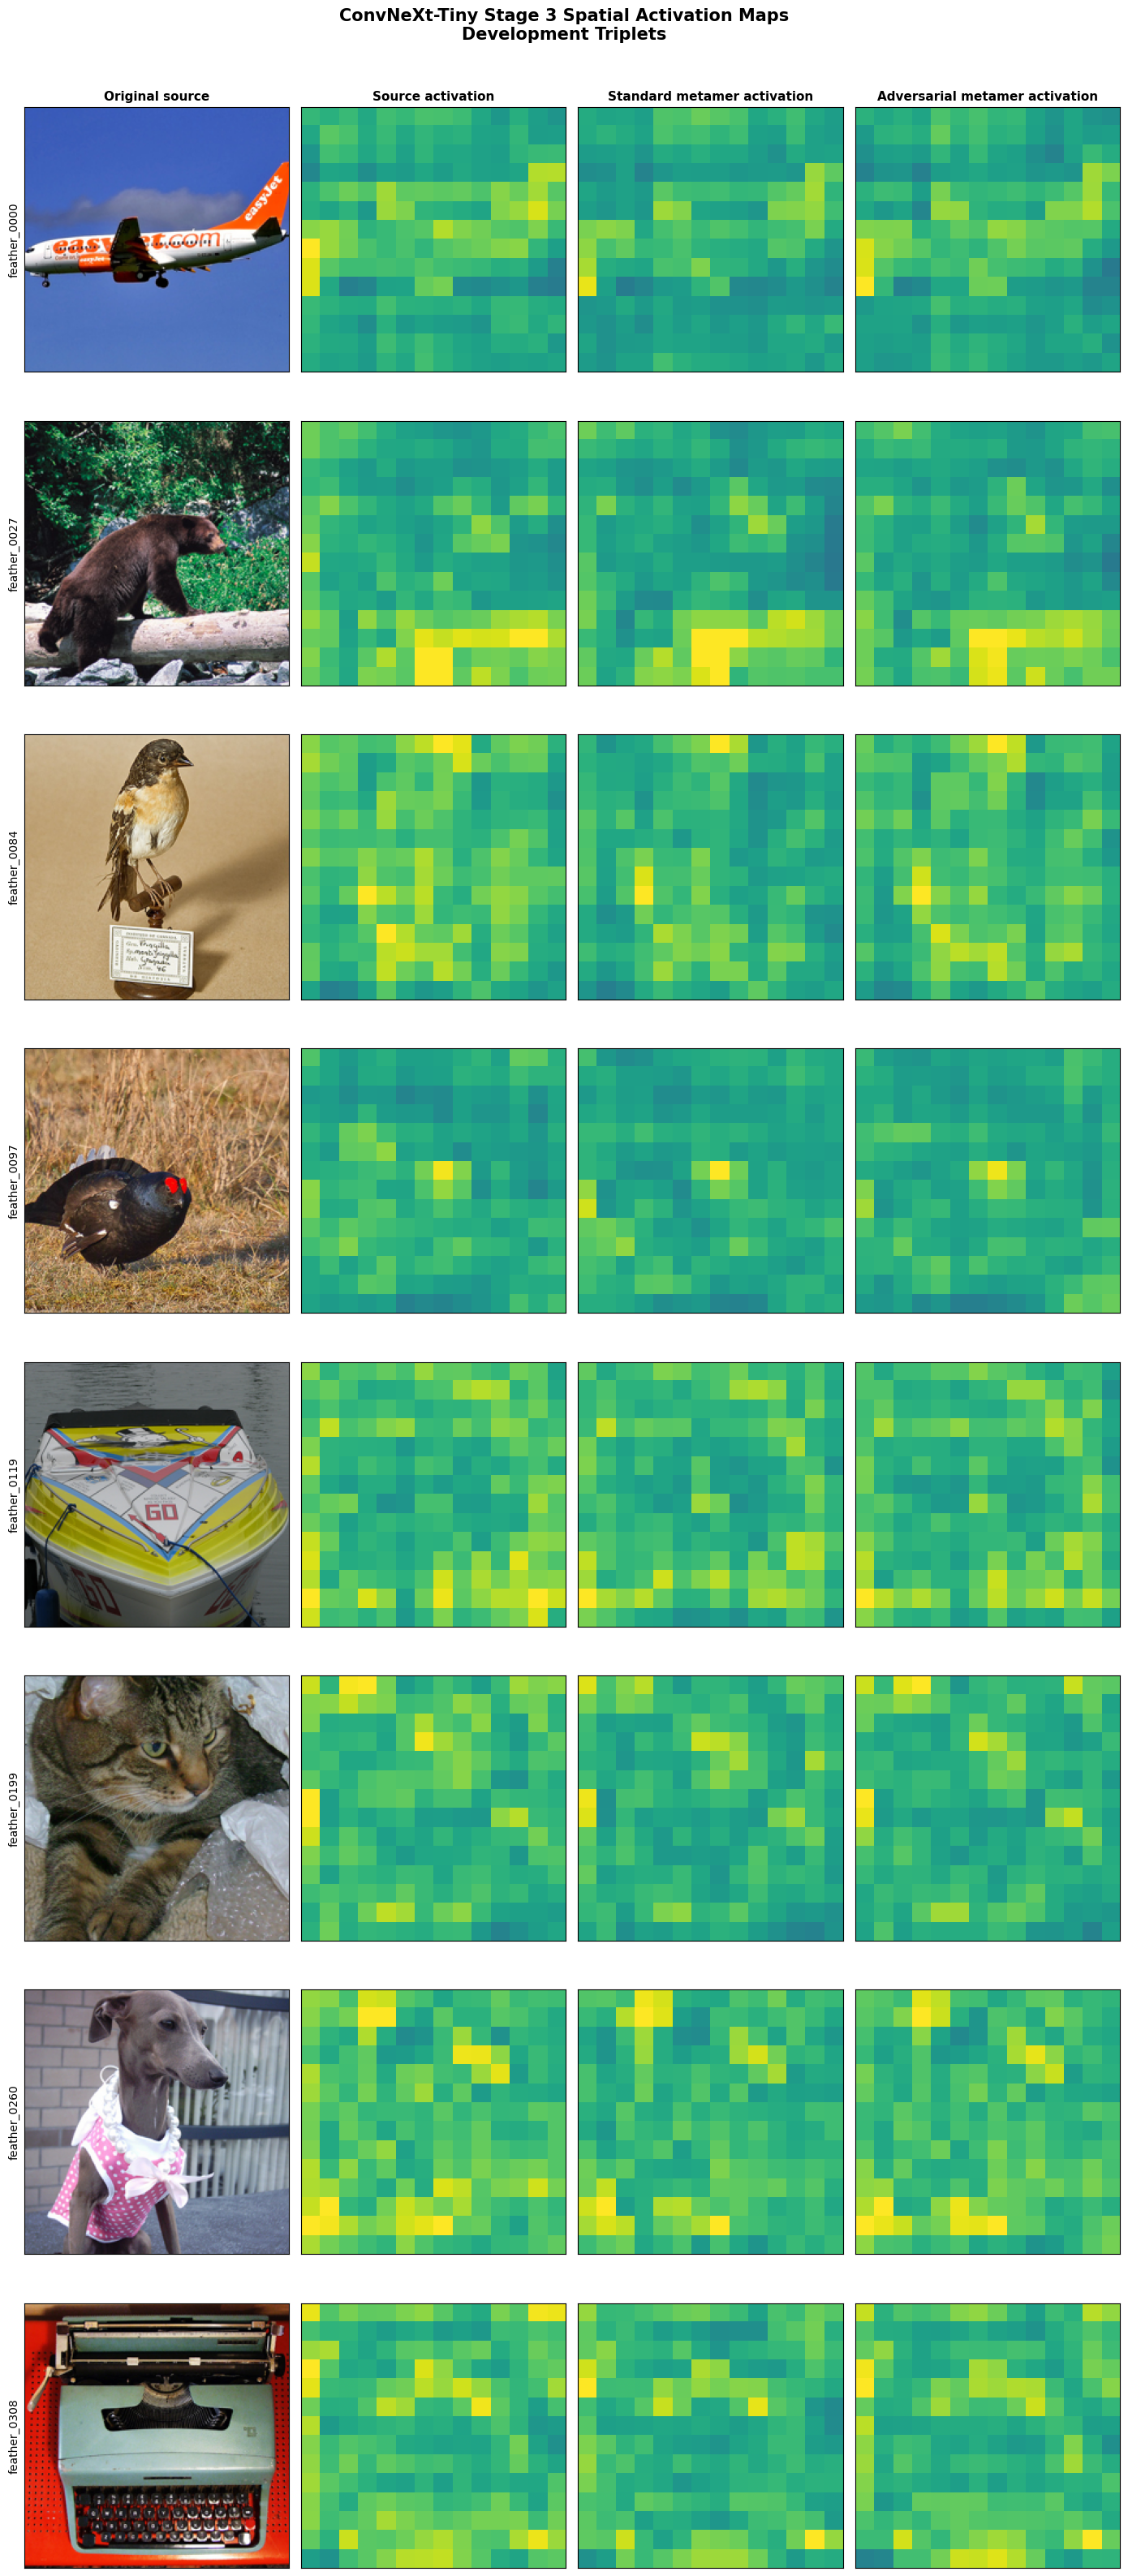


Generating Figure 7.2: Pooled activation distributions...


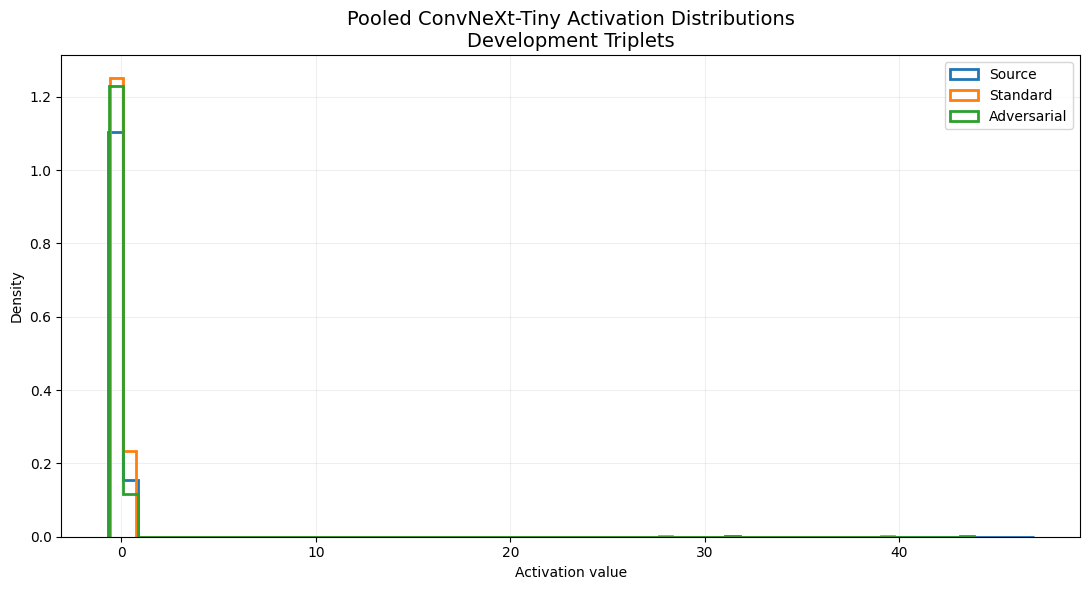


Generating Figure 7.3: Paired activation similarity...


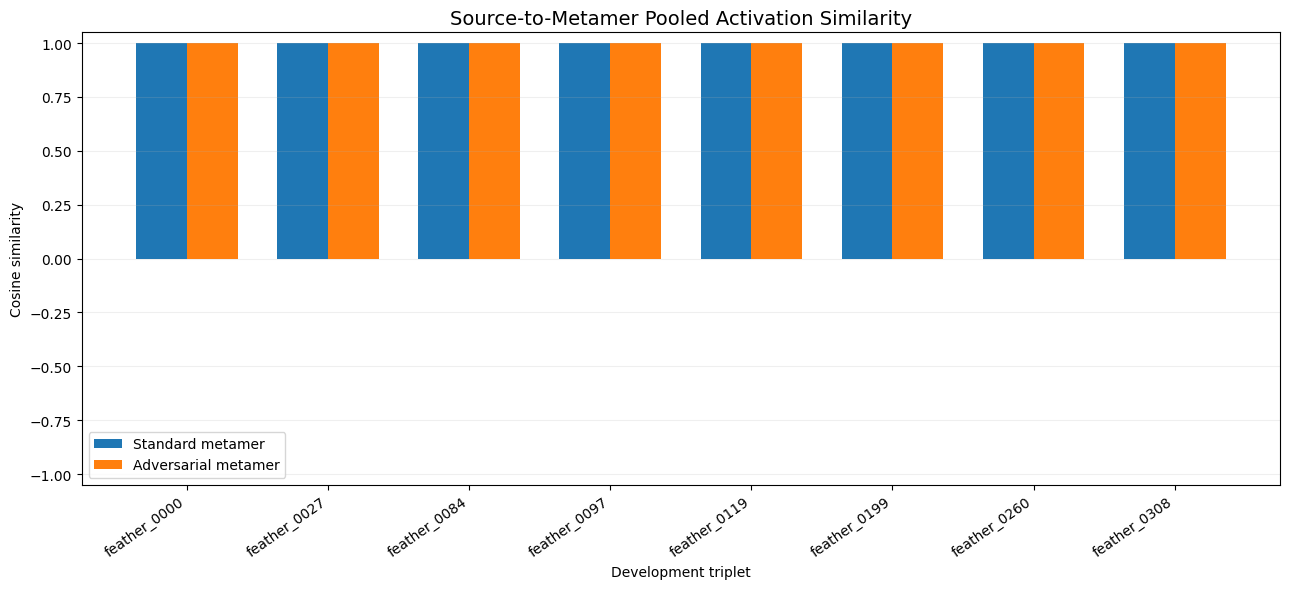


ACTIVATION DIAGNOSTIC VISUALIZATIONS COMPLETE
Development triplets visualized: 8

Generated figures:
/content/drive/MyDrive/metamer-sae/activations/visualizations/figure_7_1_spatial_activation_maps.png
/content/drive/MyDrive/metamer-sae/activations/visualizations/figure_7_2_pooled_activation_distributions.png
/content/drive/MyDrive/metamer-sae/activations/visualizations/figure_7_3_source_metamer_similarity.png

Saved numerical results:
/content/drive/MyDrive/metamer-sae/activations/visualizations/figure_7_3_similarity_values.csv

Mean cosine similarities:
Standard: 0.9995
Adversarial: 0.9997

Primary evaluation and reserve data were not used.


In [ ]:
# ================================================================
# METAMER-SAE — STAGE 7: ACTIVATION DIAGNOSTIC VISUALIZATIONS
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

print("=" * 75)
print("METAMER-SAE — ACTIVATION DIAGNOSTIC VISUALIZATIONS")
print("=" * 75)

# ------------------------------------------------
# 1. Paths
# ------------------------------------------------

ACTIVATION_ROOT = os.path.join(
    PROJECT_ROOT, "activations"
)

VISUALIZATION_DIR = os.path.join(
    ACTIVATION_ROOT, "visualizations"
)

os.makedirs(VISUALIZATION_DIR, exist_ok=True)

FEATHER_ROOT = os.path.join(
    ACTIVATION_ROOT, "feather"
)

INVENTORY_PATH = os.path.join(
    PROJECT_ROOT,
    "natural_images",
    "manifests",
    "feather_stimulus_inventory.csv"
)

# ------------------------------------------------
# 2. Load Feather metadata
# ------------------------------------------------

inventory = pd.read_csv(INVENTORY_PATH)

conditions = {
    "Source": {
        "directory": os.path.join(FEATHER_ROOT, "source"),
        "inventory_condition": "source",
    },
    "Standard": {
        "directory": os.path.join(
            FEATHER_ROOT, "standard_resnet50"
        ),
        "inventory_condition": "standard_resnet50",
    },
    "Adversarial": {
        "directory": os.path.join(
            FEATHER_ROOT, "adversarial_resnet50"
        ),
        "inventory_condition": "adversarial_resnet50",
    },
}

metadata_by_condition = {}
spatial_by_condition = {}
pooled_by_condition = {}

for condition_name, config in conditions.items():

    directory = config["directory"]

    metadata = pd.read_csv(
        os.path.join(directory, "metadata.csv")
    )

    spatial = np.load(
        os.path.join(
            directory, "spatial_activations.npy"
        ),
        mmap_mode="r"
    )

    pooled = np.load(
        os.path.join(
            directory, "pooled_activations.npy"
        ),
        mmap_mode="r"
    )

    # Derive sample IDs consistently.
    metadata["sample_id"] = metadata["filename"].apply(
        lambda name: "_".join(
            os.path.splitext(name)[0].split("_")[:2]
        )
    )

    metadata = metadata.set_index("sample_id")

    metadata_by_condition[condition_name] = metadata
    spatial_by_condition[condition_name] = spatial
    pooled_by_condition[condition_name] = pooled

# ------------------------------------------------
# 3. Select development triplets only
# ------------------------------------------------

development_ids = set(
    inventory[
        (inventory["condition"] == "source")
        & (inventory["split"] == "development")
    ]["filename"].apply(
        lambda name: "_".join(
            os.path.splitext(name)[0].split("_")[:2]
        )
    )
)

development_ids = sorted(development_ids)

assert len(development_ids) == 8

# Confirm all conditions contain the same development IDs.
for condition_name in conditions:

    assert development_ids == sorted(
        [
            sample_id
            for sample_id in development_ids
            if sample_id in metadata_by_condition[
                condition_name
            ].index
        ]
    )

print(f"Development triplets selected: {len(development_ids)}")
print("Primary evaluation and reserve sets excluded.")

# ------------------------------------------------
# 4. Helper: find activation index and image path
# ------------------------------------------------

def get_metadata(condition_name, sample_id):

    return metadata_by_condition[
        condition_name
    ].loc[sample_id]


def get_activation_index(condition_name, sample_id):

    return int(
        get_metadata(
            condition_name, sample_id
        )["activation_index"]
    )


def get_image(condition_name, sample_id):

    record = get_metadata(condition_name, sample_id)

    image_path = os.path.join(
        PROJECT_ROOT,
        record["relative_path"]
    )

    with Image.open(image_path) as image:
        return image.convert("RGB").copy()


# ------------------------------------------------
# 5. FIGURE 7.1 — Spatial activation maps
# ------------------------------------------------

print("\nGenerating Figure 7.1: Spatial activation maps...")

fig, axes = plt.subplots(
    nrows=len(development_ids),
    ncols=4,
    figsize=(14, 4 * len(development_ids))
)

column_titles = [
    "Original source",
    "Source activation",
    "Standard metamer activation",
    "Adversarial metamer activation",
]

for column, title in enumerate(column_titles):
    axes[0, column].set_title(
        title,
        fontsize=11,
        fontweight="bold"
    )

# Compute one shared colour scale for comparable maps.
all_activation_maps = []

for sample_id in development_ids:

    for condition_name in conditions:

        index = get_activation_index(
            condition_name, sample_id
        )

        activation = np.asarray(
            spatial_by_condition[condition_name][index]
        )

        # Mean absolute activation across 384 channels.
        activation_map = np.mean(
            np.abs(activation.astype(np.float32)),
            axis=0
        )

        all_activation_maps.append(activation_map)

shared_vmax = np.percentile(
    np.concatenate(
        [item.ravel() for item in all_activation_maps]
    ),
    99
)

for row, sample_id in enumerate(development_ids):

    # Original source image.
    source_image = get_image("Source", sample_id)

    axes[row, 0].imshow(source_image)
    axes[row, 0].set_ylabel(
        sample_id,
        fontsize=10
    )

    # Three activation maps.
    for column, condition_name in enumerate(
        ["Source", "Standard", "Adversarial"],
        start=1
    ):

        index = get_activation_index(
            condition_name, sample_id
        )

        activation = np.asarray(
            spatial_by_condition[condition_name][index]
        )

        activation_map = np.mean(
            np.abs(activation.astype(np.float32)),
            axis=0
        )

        axes[row, column].imshow(
            activation_map,
            cmap="viridis",
            vmin=0,
            vmax=shared_vmax
        )

    for column in range(4):
        axes[row, column].set_xticks([])
        axes[row, column].set_yticks([])

fig.suptitle(
    "ConvNeXt-Tiny Stage 3 Spatial Activation Maps\n"
    "Development Triplets",
    fontsize=15,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()

figure1_path = os.path.join(
    VISUALIZATION_DIR,
    "figure_7_1_spatial_activation_maps.png"
)

plt.savefig(
    figure1_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------
# 6. FIGURE 7.2 — Pooled activation distributions
# ------------------------------------------------

print("\nGenerating Figure 7.2: Pooled activation distributions...")

fig, ax = plt.subplots(figsize=(11, 6))

distribution_data = {}

for condition_name in conditions:

    indices = [
        get_activation_index(condition_name, sample_id)
        for sample_id in development_ids
    ]

    values = np.asarray(
        pooled_by_condition[condition_name][indices]
    ).astype(np.float32).ravel()

    distribution_data[condition_name] = values

    ax.hist(
        values,
        bins=60,
        density=True,
        histtype="step",
        linewidth=2,
        label=condition_name
    )

ax.set_title(
    "Pooled ConvNeXt-Tiny Activation Distributions\n"
    "Development Triplets",
    fontsize=14
)

ax.set_xlabel("Activation value")
ax.set_ylabel("Density")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

figure2_path = os.path.join(
    VISUALIZATION_DIR,
    "figure_7_2_pooled_activation_distributions.png"
)

plt.savefig(
    figure2_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------
# 7. FIGURE 7.3 — Paired source-to-metamer similarity
# ------------------------------------------------

print("\nGenerating Figure 7.3: Paired activation similarity...")

similarity_results = []

for sample_id in development_ids:

    source_index = get_activation_index(
        "Source", sample_id
    )

    standard_index = get_activation_index(
        "Standard", sample_id
    )

    adversarial_index = get_activation_index(
        "Adversarial", sample_id
    )

    source_vector = np.asarray(
        pooled_by_condition["Source"][source_index],
        dtype=np.float64
    )

    standard_vector = np.asarray(
        pooled_by_condition["Standard"][standard_index],
        dtype=np.float64
    )

    adversarial_vector = np.asarray(
        pooled_by_condition["Adversarial"][adversarial_index],
        dtype=np.float64
    )

    def cosine_similarity(a, b):

        denominator = (
            np.linalg.norm(a) * np.linalg.norm(b)
        )

        if denominator == 0:
            return np.nan

        return float(np.dot(a, b) / denominator)

    similarity_results.append({
        "sample_id": sample_id,
        "standard_similarity": cosine_similarity(
            source_vector, standard_vector
        ),
        "adversarial_similarity": cosine_similarity(
            source_vector, adversarial_vector
        ),
    })

similarity_df = pd.DataFrame(similarity_results)

fig, ax = plt.subplots(figsize=(13, 6))

x = np.arange(len(similarity_df))
width = 0.36

ax.bar(
    x - width / 2,
    similarity_df["standard_similarity"],
    width,
    label="Standard metamer"
)

ax.bar(
    x + width / 2,
    similarity_df["adversarial_similarity"],
    width,
    label="Adversarial metamer"
)

ax.set_xticks(x)
ax.set_xticklabels(
    similarity_df["sample_id"],
    rotation=35,
    ha="right"
)

ax.set_ylabel("Cosine similarity")
ax.set_xlabel("Development triplet")
ax.set_title(
    "Source-to-Metamer Pooled Activation Similarity",
    fontsize=14
)

ax.set_ylim(-1.05, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

figure3_path = os.path.join(
    VISUALIZATION_DIR,
    "figure_7_3_source_metamer_similarity.png"
)

plt.savefig(
    figure3_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------
# 8. Save numerical similarity results
# ------------------------------------------------

similarity_csv_path = os.path.join(
    VISUALIZATION_DIR,
    "figure_7_3_similarity_values.csv"
)

similarity_df.to_csv(
    similarity_csv_path,
    index=False
)

# ------------------------------------------------
# 9. Final report
# ------------------------------------------------

print("\n" + "=" * 75)
print("ACTIVATION DIAGNOSTIC VISUALIZATIONS COMPLETE")
print("=" * 75)

print(f"Development triplets visualized: {len(development_ids)}")

print("\nGenerated figures:")
print(figure1_path)
print(figure2_path)
print(figure3_path)

print("\nSaved numerical results:")
print(similarity_csv_path)

print("\nMean cosine similarities:")

print(
    "Standard:",
    round(
        similarity_df["standard_similarity"].mean(),
        4
    )
)

print(
    "Adversarial:",
    round(
        similarity_df["adversarial_similarity"].mean(),
        4
    )
)

print("\nPrimary evaluation and reserve data were not used.")
print("=" * 75)

In [ ]:
# ================================================================
# METAMER-SAE — STAGE 8: NOTEBOOK 03 FINAL VERIFICATION
# ================================================================

import os
import json
import numpy as np
import pandas as pd
from datetime import datetime, timezone

print("=" * 75)
print("METAMER-SAE — NOTEBOOK 03 FINAL VERIFICATION")
print("=" * 75)

# ------------------------------------------------
# 1. Define paths
# ------------------------------------------------

ACTIVATION_ROOT = os.path.join(PROJECT_ROOT, "activations")

AUDIT_PATH = os.path.join(
    ACTIVATION_ROOT,
    "audit",
    "comprehensive_activation_integrity_audit.json"
)

VISUALIZATION_DIR = os.path.join(
    ACTIVATION_ROOT,
    "visualizations"
)

CLOSURE_DIR = os.path.join(
    ACTIVATION_ROOT,
    "audit"
)

os.makedirs(CLOSURE_DIR, exist_ok=True)

# ------------------------------------------------
# 2. Required activation files
# ------------------------------------------------

activation_groups = {
    "imagenette_train": os.path.join(
        ACTIVATION_ROOT, "natural_images", "train"
    ),
    "imagenette_validation": os.path.join(
        ACTIVATION_ROOT, "natural_images", "validation"
    ),
    "feather_source": os.path.join(
        ACTIVATION_ROOT, "feather", "source"
    ),
    "feather_standard": os.path.join(
        ACTIVATION_ROOT, "feather", "standard_resnet50"
    ),
    "feather_adversarial": os.path.join(
        ACTIVATION_ROOT, "feather", "adversarial_resnet50"
    ),
}

expected_counts = {
    "imagenette_train": 9469,
    "imagenette_validation": 3925,
    "feather_source": 48,
    "feather_standard": 48,
    "feather_adversarial": 48,
}

verification_results = {}

print("\nChecking activation groups...")

for group_name, directory in activation_groups.items():

    spatial_path = os.path.join(
        directory, "spatial_activations.npy"
    )

    pooled_path = os.path.join(
        directory, "pooled_activations.npy"
    )

    metadata_path = os.path.join(
        directory, "metadata.csv"
    )

    progress_path = os.path.join(
        directory, "extraction_progress.json"
    )

    assert os.path.isfile(spatial_path), (
        f"Missing spatial activations: {group_name}"
    )

    assert os.path.isfile(pooled_path), (
        f"Missing pooled activations: {group_name}"
    )

    assert os.path.isfile(metadata_path), (
        f"Missing metadata: {group_name}"
    )

    assert os.path.isfile(progress_path), (
        f"Missing progress report: {group_name}"
    )

    spatial = np.load(spatial_path, mmap_mode="r")
    pooled = np.load(pooled_path, mmap_mode="r")
    metadata = pd.read_csv(metadata_path)

    expected_count = expected_counts[group_name]

    assert spatial.shape == (
        expected_count, 384, 14, 14
    ), f"Incorrect spatial shape: {group_name}"

    assert pooled.shape == (
        expected_count, 384
    ), f"Incorrect pooled shape: {group_name}"

    assert len(metadata) == expected_count, (
        f"Incorrect metadata count: {group_name}"
    )

    assert spatial.dtype == np.float16
    assert pooled.dtype == np.float32

    # Verify values in chunks to avoid loading all arrays into RAM.
    for start in range(0, expected_count, 256):

        end = min(start + 256, expected_count)

        assert np.isfinite(
            np.asarray(spatial[start:end])
        ).all()

        assert np.isfinite(
            np.asarray(pooled[start:end])
        ).all()

    with open(progress_path, "r") as file:
        progress = json.load(file)

    verification_results[group_name] = {
        "sample_count": int(expected_count),
        "spatial_shape": list(spatial.shape),
        "pooled_shape": list(pooled.shape),
        "spatial_dtype": str(spatial.dtype),
        "pooled_dtype": str(pooled.dtype),
        "metadata_rows": int(len(metadata)),
        "all_values_finite": True,
        "progress_report_exists": True,
    }

    print(
        f"PASS: {group_name} — "
        f"{expected_count:,} samples"
    )

# ------------------------------------------------
# 3. Check comprehensive integrity audit
# ------------------------------------------------

assert os.path.isfile(AUDIT_PATH), (
    "Comprehensive activation audit is missing."
)

with open(AUDIT_PATH, "r") as file:
    integrity_audit = json.load(file)

print("\nComprehensive activation audit:")
print("File exists:", True)

# ------------------------------------------------
# 4. Check visualization outputs
# ------------------------------------------------

required_visualizations = [
    "figure_7_1_spatial_activation_maps.png",
    "figure_7_2_pooled_activation_distributions.png",
    "figure_7_3_source_metamer_similarity.png",
    "figure_7_3_similarity_values.csv",
]

print("\nChecking visualization files...")

for filename in required_visualizations:

    path = os.path.join(
        VISUALIZATION_DIR,
        filename
    )

    assert os.path.isfile(path), (
        f"Missing visualization: {filename}"
    )

    assert os.path.getsize(path) > 0, (
        f"Empty visualization: {filename}"
    )

    print("PASS:", filename)

# ------------------------------------------------
# 5. Verify numerical similarity results
# ------------------------------------------------

similarity_path = os.path.join(
    VISUALIZATION_DIR,
    "figure_7_3_similarity_values.csv"
)

similarity_df = pd.read_csv(similarity_path)

assert len(similarity_df) == 8

assert similarity_df[
    "standard_similarity"
].notna().all()

assert similarity_df[
    "adversarial_similarity"
].notna().all()

# ------------------------------------------------
# 6. Compute final totals
# ------------------------------------------------

total_imagenette = (
    expected_counts["imagenette_train"]
    + expected_counts["imagenette_validation"]
)

total_feather = (
    expected_counts["feather_source"]
    + expected_counts["feather_standard"]
    + expected_counts["feather_adversarial"]
)

total_images = total_imagenette + total_feather

# ------------------------------------------------
# 7. Save Notebook 03 closure report
# ------------------------------------------------

closure_report = {
    "project": "metamer-sae",
    "notebook": "03_observer_and_activation_extraction",
    "status": "complete",
    "closure_timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "observer": {
        "architecture": "ConvNeXt-Tiny",
        "weights": "ImageNet-1K pretrained",
        "framework": "TorchVision",
        "input_size": [224, 224],
        "feature_stage": "Stage 3",
        "spatial_shape_per_image": [384, 14, 14],
        "pooled_shape_per_image": [384],
        "frozen": True,
    },

    "activation_groups": verification_results,

    "dataset_totals": {
        "imagenette_images": total_imagenette,
        "feather_images": total_feather,
        "total_images": total_images,
    },

    "development_similarity": {
        "number_of_triplets": 8,
        "mean_standard_cosine_similarity": float(
            similarity_df[
                "standard_similarity"
            ].mean()
        ),
        "mean_adversarial_cosine_similarity": float(
            similarity_df[
                "adversarial_similarity"
            ].mean()
        ),
    },

    "data_discipline": {
        "pca_sae_fitting_on_feather": False,
        "primary_evaluation_used_for_diagnostics": False,
        "reserve_used_for_diagnostics": False,
        "imagenette_training_reserved_for_model_fitting": True,
        "imagenette_validation_reserved_for_validation": True,
    },

    "integrity_audit_path": AUDIT_PATH,

    "visualization_directory": VISUALIZATION_DIR,

    "next_notebook": "04_pca_analysis",
}

closure_path = os.path.join(
    CLOSURE_DIR,
    "notebook_03_closure_report.json"
)

with open(closure_path, "w") as file:
    json.dump(
        closure_report,
        file,
        indent=4
    )

# ------------------------------------------------
# 8. Final report
# ------------------------------------------------

print("\n" + "=" * 75)
print("NOTEBOOK 03 FINAL VERIFICATION PASSED")
print("=" * 75)

print("Imagenette images:", f"{total_imagenette:,}")
print("Feather images:", f"{total_feather:,}")
print("Total images:", f"{total_images:,}")

print("\nActivation groups verified:", len(verification_results))
print("Visualization files verified:", len(required_visualizations))

print("\nMean development cosine similarity:")
print(
    "Standard:",
    round(
        similarity_df["standard_similarity"].mean(),
        4
    )
)
print(
    "Adversarial:",
    round(
        similarity_df["adversarial_similarity"].mean(),
        4
    )
)

print("\nClosure report saved:")
print(closure_path)

print("\nNotebook 03 is ready for formal closure.")
print("=" * 75)


METAMER-SAE — NOTEBOOK 03 FINAL VERIFICATION

Checking activation groups...
PASS: imagenette_train — 9,469 samples
PASS: imagenette_validation — 3,925 samples
PASS: feather_source — 48 samples
PASS: feather_standard — 48 samples
PASS: feather_adversarial — 48 samples

Comprehensive activation audit:
File exists: True

Checking visualization files...
PASS: figure_7_1_spatial_activation_maps.png
PASS: figure_7_2_pooled_activation_distributions.png
PASS: figure_7_3_source_metamer_similarity.png
PASS: figure_7_3_similarity_values.csv

NOTEBOOK 03 FINAL VERIFICATION PASSED
Imagenette images: 13,394
Feather images: 144
Total images: 13,538

Activation groups verified: 5
Visualization files verified: 4

Mean development cosine similarity:
Standard: 0.9995
Adversarial: 0.9997

Closure report saved:
/content/drive/MyDrive/metamer-sae/activations/audit/notebook_03_closure_report.json

Notebook 03 is ready for formal closure.
